# Task 2 – Model Baseline und Data Preparation
**Data Science WS 2026/27 | HdM | Case Study „Air Quality Sensor Calibration"**

**Forschungsfrage:** Kann die PM2.5-Messung eines Low-Cost-Sensors zusammen mit weiteren Sensoren und Wetterdaten genutzt werden, um die Messung eines hochwertigen Referenzgeräts (`pm25_target`) präzise zu schätzen?

**Unsere Aufgabe (Task 2):**
1. Baseline-Modell (lineare Regression) mit minimalem Preprocessing erstellen und auf der Validierung bewerten
2. Die in Task 1 gefundenen Datenqualitätsprobleme mit einzelnen Preprocessing-Modulen beheben
3. Jedes Modul **einzeln** und in **Kombination** mit einer neuen linearen Regression prüfen (MAE und R²)
4. Overfitting prüfen (Training vs. Validierung)
5. Bestes Modell + finale Data Preparation einmalig auf die Testdaten anwenden
6. Ergebnisse visualisieren (absolute und relative Verbesserung zur Baseline)
7. Vorbereitete Trainings-, Validierungs- und Testdaten als CSV exportieren (Übergabe an Task 3)

**Spielregeln, die im gesamten Notebook gelten:**
- Alle Parameter (Mediane, Kappungsgrenzen, Skalierung, Feature-Auswahl) werden **nur auf dem Trainingsanteil** gelernt und danach auf Validierung und Test angewendet.
- Wie in Task 1 werden Zeilen ohne Label **vor** dem Split aus der Trainingsdatei entfernt. Danach werden in Validierung und Test **keine Zeilen gelöscht** und **keine Labels verändert**. Im Test werden Zeilen ohne Label nur bei der Berechnung von MAE/R² ausgelassen.
- Jedes Experiment wird mit sprechendem Namen, Beschreibung und Kennzahlen in ein **Log-File** (`Output/evaluation_log.csv`) geschrieben.
- Die Testdaten werden erst ganz am Ende verwendet, nachdem das finale Modell feststeht.

**Aufbau des Notebooks**

| Abschnitt | Inhalt |
|---|---|
| 1 | Setup, Daten laden, Train/Validation-Split |
| 2 | Evaluations-Framework und Log-File |
| 3 | Baseline und erste Analyse der Baseline |
| 4 | Werkzeugkasten: Preprocessing-Module M1–M6 inkl. Analyse (u. a. Pearson vs. Spearman) |
| 5 | Pipeline: Module in fester Reihenfolge verbinden |
| 6 | Experimente: jedes Modul einzeln |
| 7 | Experimente: Kombinationen der Module |
| 8 | Gesamtvergleich, Visualisierung, Overfitting-Check, Auswahl des finalen Modells |
| 9 | Finales Modell auf den Testdaten |
| 10 | Analyse: Warum ist der Test schlechter als die Validierung? |
| 11 | Export der vorbereiteten Datensätze |
| 12 | Learnings, Übergabe an Task 3 und Coding-Reflexion |

### Anknüpfung an Task 1

Task 2 setzt direkt die Handlungsempfehlungen aus der Data Exploration (Task 1) um. Die folgende Tabelle zeigt, welcher Befund aus Task 1 in welchem Modul behandelt wird.

| Befund / Empfehlung aus Task 1 | Modul in Task 2 |
|---|---|
| Fehlende Werte, v. a. `co2` (927), `ufp` (777), `o3` (747), Wetterdaten (428) | **M2 Missing Values** – Median, Mittelwert, Regressionsimputation, Zeilenlöschung (nur Training) |
| Extreme Ausreißer, v. a. `pm25_lowcost` (max. 595 µg/m³ bei Label-Max. 15,6) sowie `no`, `black_carbon` | **M3 Outlier Handling** – Auswahl der Methode über den Vergleich Pearson vs. Spearman (Hinweis aus der Präsentation) |
| Sehr unterschiedliche Wertebereiche (z. B. `ufp` vs. `black_carbon`) | **M4 Scaling** – Standardisierung inkl. Analyse, warum sie bei linearer Regression nichts ändert |
| `timestamp` ist nicht direkt als Feature nutzbar | **M5 Feature Engineering** – Tageszeit, Windrichtung als Kreis, Feuchte-Interaktion |
| Schwach korrelierte / redundante Features prüfen | **M6 Feature Selection** – korrelationsbasiert (`corrwith`) und Multikollinearität (VIF) |
| Offene Frage: Warum ist der Test in Task 1b so viel schlechter als die Validierung? | **Abschnitt 10** – Analyse der Testdaten (Vollständigkeit, Saison) |

### Umsetzung des Feedbacks aus dem Vorjahr

Das Vorjahresprojekt (gleiche Aufgabe, anderer Datensatz) erhielt 21/25 Punkte. Die Kritikpunkte haben wir so umgesetzt:

| Feedback Vorjahr | Umsetzung in diesem Notebook |
|---|---|
| Baseline wurde nur auf 3 Features erzeugt (konzeptioneller Fehler) | Baseline auf allen 14 numerischen Features (Abschnitt 3) |
| Baseline-Wert hätte analysiert werden sollen | Abschnitt 3.1: Koeffizienten-Analyse, Streudiagramm Low-Cost vs. Referenz |
| Validation-Split fehlte / Zwischenschritte als einzelne Modelle | 80/20-Split wie Task 1b; jedes Modul und jede Kombination als eigenes Modell im Log (Abschnitte 6, 7) |
| Modularisierung | Einheitliche Modul-Schnittstelle und Pipeline (Abschnitte 4, 5) |
| Noch keine Feature Selection in Task 2 | M6 mit Korrelationsfilter und VIF (Lab 10c) |
| Kurze Analyse, warum Scaling nichts bringt | M4: Begründung vorab, Beleg in Abschnitt 6 (exakt 0 %) |
| Grafische Gegenüberstellung aller Ergebnisse | Abschnitt 8.1: alle Modelle in einem Diagramm |
| Einzelergebnisse mit Delta zur Baseline | Spalten „Delta MAE (abs/%)" im Log; Delta-Diagramme in Abschnitt 6 und 8 |
| Sprechende Modellnamen statt „M5" | Jedes Modell trägt einen beschreibenden Namen |
| Kombinationen der Maßnahmen erproben (z. B. MVH + OH) | Abschnitt 7 und Kombinationsmatrix 7.1 |
| Learnings auf den Folien zu dünn | Interpretation nach jedem Schritt, Learnings und Register in Abschnitt 12 |
| „Gute Umsetzung von OHE" | Hier nicht nötig: Der Datensatz enthält keine kategorialen Features. Die einzigen nicht numerischen Spalten sind `timestamp` und `year_month`, die wir über M5 (Tageszeit) nutzbar machen. |

Zusätzlich sind uns in Task 2 zwei Auffälligkeiten aufgefallen, die in Task 1 noch nicht behandelt wurden: negative Konzentrationswerte (`no`, im Test zusätzlich `o3`) und der Verlauf von `rain_vol`, der auf einen aufsummierten Zähler hindeutet. Beides wird in **M1 Regelbasierte Korrekturen** behandelt.

## 1. Setup, Daten laden und Split

Wir verwenden nur die Bibliotheken aus den Python Labs der Vorlesung: `pandas`, `numpy`, `matplotlib` und `scikit-learn`.

In [1]:
# Datenmanipulation
import pandas as pd
import numpy as np

# Visualisierung
import matplotlib.pyplot as plt

# Modell, Split, Evaluation und Preprocessing (wie in den Python Labs)
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.preprocessing import StandardScaler, QuantileTransformer

# Einheitliche Darstellung der Tabellen
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

# Ordner für Ein- und Ausgabedateien
DATA_DIR = "Data/"
OUTPUT_DIR = "Output/"

In [2]:
# Originaldaten laden – diese beiden DataFrames werden NIE verändert
raw_train = pd.read_csv(DATA_DIR + "pm25_train.csv", parse_dates=["timestamp"])
raw_test = pd.read_csv(DATA_DIR + "pm25_test.csv", parse_dates=["timestamp"])

# Kontrolle gegen die Aufgabenstellung (3.613 Trainings- und 1.464 Testzeilen)
assert len(raw_train) == 3613
assert len(raw_test) == 1464

print("Training:", raw_train.shape, "| Zeitraum:", raw_train["timestamp"].min(), "bis", raw_train["timestamp"].max())
print("Test:    ", raw_test.shape, "| Zeitraum:", raw_test["timestamp"].min(), "bis", raw_test["timestamp"].max())
display(raw_train.head())

Training: (3613, 17) | Zeitraum: 2024-06-03 11:00:00 bis 2024-10-31 23:00:00
Test:     (1464, 17) | Zeitraum: 2024-11-01 00:00:00 bis 2024-12-31 23:00:00


,timestamp,year_month,pm25_target,pm25_lowcost,no,no2,o3,co2,black_carbon,ufp,temperature,relative_humidity,pressure,wind_speed,wind_direction,rain_vol,glob_rad
0,2024-06-03 11:00:00,2024-06,6.26,4.48,1.1,5.9,42.6,452.8,0.393,4757.4,14.951,61.676,1013.662,0.765,66.126,45.35,436.257
1,2024-06-03 12:00:00,2024-06,5.99,4.10,1.2,5.7,44.3,451.0,0.377,5033.6,15.224,60.849,1013.400,1.329,51.441,45.35,480.905
2,2024-06-03 13:00:00,2024-06,6.01,3.69,1.6,5.9,43.7,450.4,0.364,5846.9,15.782,59.932,1013.103,1.331,52.637,45.35,708.009
3,2024-06-03 14:00:00,2024-06,7.93,4.53,1.4,6.7,43.3,454.4,0.453,5975.0,15.877,59.112,1012.868,1.380,54.700,45.35,547.942
4,2024-06-03 15:00:00,2024-06,7.49,3.82,1.3,6.3,42.2,453.5,0.399,5211.7,16.108,58.005,1012.576,1.775,50.297,45.35,550.972


**Wichtig für später:** Die Trainingsdaten stammen aus Juni bis Oktober, die Testdaten aus November und Dezember. Die Testdaten liegen also in einer anderen Jahreszeit. Das greifen wir in Abschnitt 10 wieder auf.

### Train/Validation-Split

Wir übernehmen den Split **exakt aus Task 1b**, damit die Validierungsergebnisse direkt vergleichbar sind:

1. Zeilen ohne `pm25_target` werden aus der **Trainingsdatei** entfernt (`dropna(subset=["pm25_target"])`). Ohne Label kann eine Zeile weder zum Training noch zur Bewertung beitragen.
2. Die gelabelten Zeilen werden mit `train_test_split(test_size=0.2, random_state=42)` in 80 % Training und 20 % Validierung geteilt.

**Warum vor dem Split?** Gleiche `random_state` reicht nicht: Teilt man zuerst die ganze Datei und entfernt die Zeilen ohne Label danach, entstehen andere Validierungszeilen (bei uns hätten nur 233 von 682 Zeilen übereingestimmt). Ab dem Split gilt die Regel der Aufgabenstellung: In der Validierung und im Test werden keine Zeilen mehr entfernt. Die Testdatei behält alle 1.464 Zeilen, auch die 45 ohne Label.

Wir speichern nur die **Indizes** der beiden Anteile. So kann jedes Experiment dieselbe Aufteilung wiederverwenden.

In [3]:
TARGET = "pm25_target"

# Schritt 1 wie in Task 1b: nur gelabelte Zeilen der Trainingsdatei
labeled_train = raw_train.dropna(subset=[TARGET])
print("Trainingsdatei:", len(raw_train), "| ohne Label:", len(raw_train) - len(labeled_train), "| gelabelt:", len(labeled_train))

# Schritt 2 wie in Task 1b: 80/20-Split mit random_state=42
train_split, val_split = train_test_split(labeled_train, test_size=0.2, random_state=42)
train_idx = train_split.index
val_idx = val_split.index

# Kontrolle: gleiche Größen wie in Task 1b (2.727 Training, 682 Validierung)
assert len(train_idx) == 2727 and len(val_idx) == 682

split_overview = pd.DataFrame({
    "Zeilen": [len(train_idx), len(val_idx), len(raw_test)],
    "davon ohne Label": [raw_train.loc[train_idx, TARGET].isna().sum(),
                         raw_train.loc[val_idx, TARGET].isna().sum(),
                         raw_test[TARGET].isna().sum()],
    "Umgang": ["identisch mit Task 1b", "identisch mit Task 1b, keine weiteren Zeilen entfernt",
               "alle Zeilen bleiben, Bewertung nur mit Label"]
}, index=["Training (80 %)", "Validierung (20 %)", "Test"])
display(split_overview)

Trainingsdatei: 3613 | ohne Label: 204 | gelabelt: 3409


,Zeilen,davon ohne Label,Umgang
Training (80 %),2727,0,identisch mit Task 1b
Validierung (20 %),682,0,"identisch mit Task 1b, keine weiteren Zeilen e..."
Test,1464,45,"alle Zeilen bleiben, Bewertung nur mit Label"


## 2. Evaluations-Framework und Log-File

Damit alle Modelle exakt gleich bewertet werden, kapseln wir Training und Bewertung in Funktionen:

- `evaluate_model()` trainiert eine **lineare Regression** und berechnet MAE und R² auf Training und Validierung.
- `log_result()` schreibt das Ergebnis mit sprechendem Namen, Modulbezeichnung und Beschreibung in die Ergebnisliste und speichert sie sofort als CSV-Log-File.

Zusätzlich berechnen wir für jedes Modell das **Delta zur Baseline** (absolut und in %) und die **Lücke zwischen Validierungs- und Trainings-MAE** als einfachen Overfitting-Indikator.

Zur Erinnerung:
- **MAE** (Mean Absolute Error): durchschnittliche absolute Abweichung der Vorhersage vom echten Wert in µg/m³ → kleiner ist besser
- **R²**: Anteil der Varianz des Labels, den das Modell erklärt → größer ist besser (1 = perfekt, 0 = so gut wie der Mittelwert, < 0 = schlechter als der Mittelwert)

In [4]:
def evaluate_model(X_train, y_train, X_eval, y_eval):
    # Trainiert eine lineare Regression und bewertet sie auf Training und einem Evaluationsdatensatz.
    # Zeilen ohne Label im Evaluationsdatensatz werden nur bei der Bewertung ausgelassen, nicht gelöscht.
    model = LinearRegression()
    model.fit(X_train, y_train)

    has_label = y_eval.notna().to_numpy()
    pred_train = model.predict(X_train)
    pred_eval = model.predict(X_eval)

    metrics = {
        "MAE_train": mean_absolute_error(y_train, pred_train),
        "MAE_val": mean_absolute_error(y_eval[has_label], pred_eval[has_label]),
        "R2_train": r2_score(y_train, pred_train),
        "R2_val": r2_score(y_eval[has_label], pred_eval[has_label]),
    }
    return model, metrics


# Ergebnisliste – jede Zeile ist ein Experiment
results = []
LOG_FILE = OUTPUT_DIR + "evaluation_log.csv"


def log_result(name, module, description, n_features, metrics):
    # Ergebnis speichern und Log-File sofort aktualisieren
    entry = {"Modell": name, "Modul": module, "Beschreibung": description, "Anzahl Features": n_features}
    entry.update(metrics)
    results.append(entry)

    log_df = pd.DataFrame(results)
    base_mae = log_df.loc[0, "MAE_val"]   # erste Zeile ist immer die Baseline
    base_r2 = log_df.loc[0, "R2_val"]
    log_df["Delta MAE (abs)"] = base_mae - log_df["MAE_val"]                # positiv = besser als Baseline
    log_df["Delta MAE (%)"] = (base_mae - log_df["MAE_val"]) / base_mae * 100
    log_df["Delta R2 (abs)"] = log_df["R2_val"] - base_r2
    log_df["Overfitting-Lücke (MAE_val - MAE_train)"] = log_df["MAE_val"] - log_df["MAE_train"]
    log_df.round(4).to_csv(LOG_FILE, index=False, sep=";", decimal=",")
    return log_df


def show_results(log_df, rows=None):
    # Kompakte Ansicht der wichtigsten Spalten
    cols = ["Modell", "Anzahl Features", "MAE_train", "MAE_val", "R2_val", "Delta MAE (abs)", "Delta MAE (%)",
            "Overfitting-Lücke (MAE_val - MAE_train)"]
    view = log_df[cols] if rows is None else log_df.loc[rows, cols]
    display(view.round(4))

## 3. Baseline: lineare Regression mit minimalem Preprocessing

**Konzept:** Die Baseline soll zeigen, wie gut ein Modell mit dem **Originaldatensatz** ohne nennenswerte Aufbereitung ist. Alles, was wir später verbessern, wird an ihr gemessen.

Aus dem Feedback des Vorjahres haben wir gelernt, dass eine Baseline auf wenigen ausgewählten Features ein konzeptioneller Fehler ist. Deshalb verwendet unsere Baseline **alle 14 numerischen Features** (die Aufgabenstellung zählt 16 Features inkl. `timestamp` und `year_month`).

Minimal heißt bei uns genau zwei Schritte, ohne die eine lineare Regression technisch nicht laufen kann:
1. Zeilen ohne Label sind nicht im Training (bereits beim Split wie in Task 1 entfernt)
2. Fehlende Feature-Werte mit dem **Median des Trainingsanteils** füllen (`LinearRegression` akzeptiert keine NaN). Der Median entspricht der Vorgehensweise aus Task 1b.

`timestamp` und `year_month` sind keine numerischen Features und werden in der Baseline nicht verwendet.

In [5]:
# Alle numerischen Spalten außer dem Label sind Features
baseline_features = [col for col in raw_train.select_dtypes(include="number").columns if col != TARGET]
print("Baseline-Features (" + str(len(baseline_features)) + "):", baseline_features)

# Trainingsanteil: nur Zeilen mit Label
train_base = raw_train.loc[train_idx]
train_base = train_base[train_base[TARGET].notna()]
val_base = raw_train.loc[val_idx]

# Median NUR aus dem Trainingsanteil – auch für die Validierung
train_medians = train_base[baseline_features].median()
X_train_base = train_base[baseline_features].fillna(train_medians)
X_val_base = val_base[baseline_features].fillna(train_medians)

baseline_model, baseline_metrics = evaluate_model(X_train_base, train_base[TARGET], X_val_base, val_base[TARGET])
log_df = log_result("Baseline (alle Features, Median-Imputation)", "Baseline",
                    "Originaldaten, alle 14 numerischen Features, NaN durch Trainings-Median ersetzt",
                    len(baseline_features), baseline_metrics)
show_results(log_df)

Baseline-Features (14): ['pm25_lowcost', 'no', 'no2', 'o3', 'co2', 'black_carbon', 'ufp', 'temperature', 'relative_humidity', 'pressure', 'wind_speed', 'wind_direction', 'rain_vol', 'glob_rad']


,Modell,Anzahl Features,MAE_train,MAE_val,R2_val,Delta MAE (abs),Delta MAE (%),Overfitting-Lücke (MAE_val - MAE_train)
0,"Baseline (alle Features, Median-Imputation)",14,1.3261,1.3417,0.359,0.0,0.0,0.0156


### 3.1 Erste Analyse der Baseline

Im Vorjahr wurde kritisiert, dass die Baseline nicht analysiert wurde. Deshalb schauen wir uns an, **welche Features das Baseline-Modell tatsächlich nutzt**. Wie in Task 1 multiplizieren wir dafür jeden Koeffizienten mit der Standardabweichung des Features. So sieht man, um wie viel µg/m³ sich die Vorhersage ändert, wenn sich das Feature um eine typische Schwankung (eine Standardabweichung) verändert.

Zusätzlich betrachten wir den wichtigsten fachlichen Zusammenhang direkt: Low-Cost-Sensor gegen Referenzmessung.

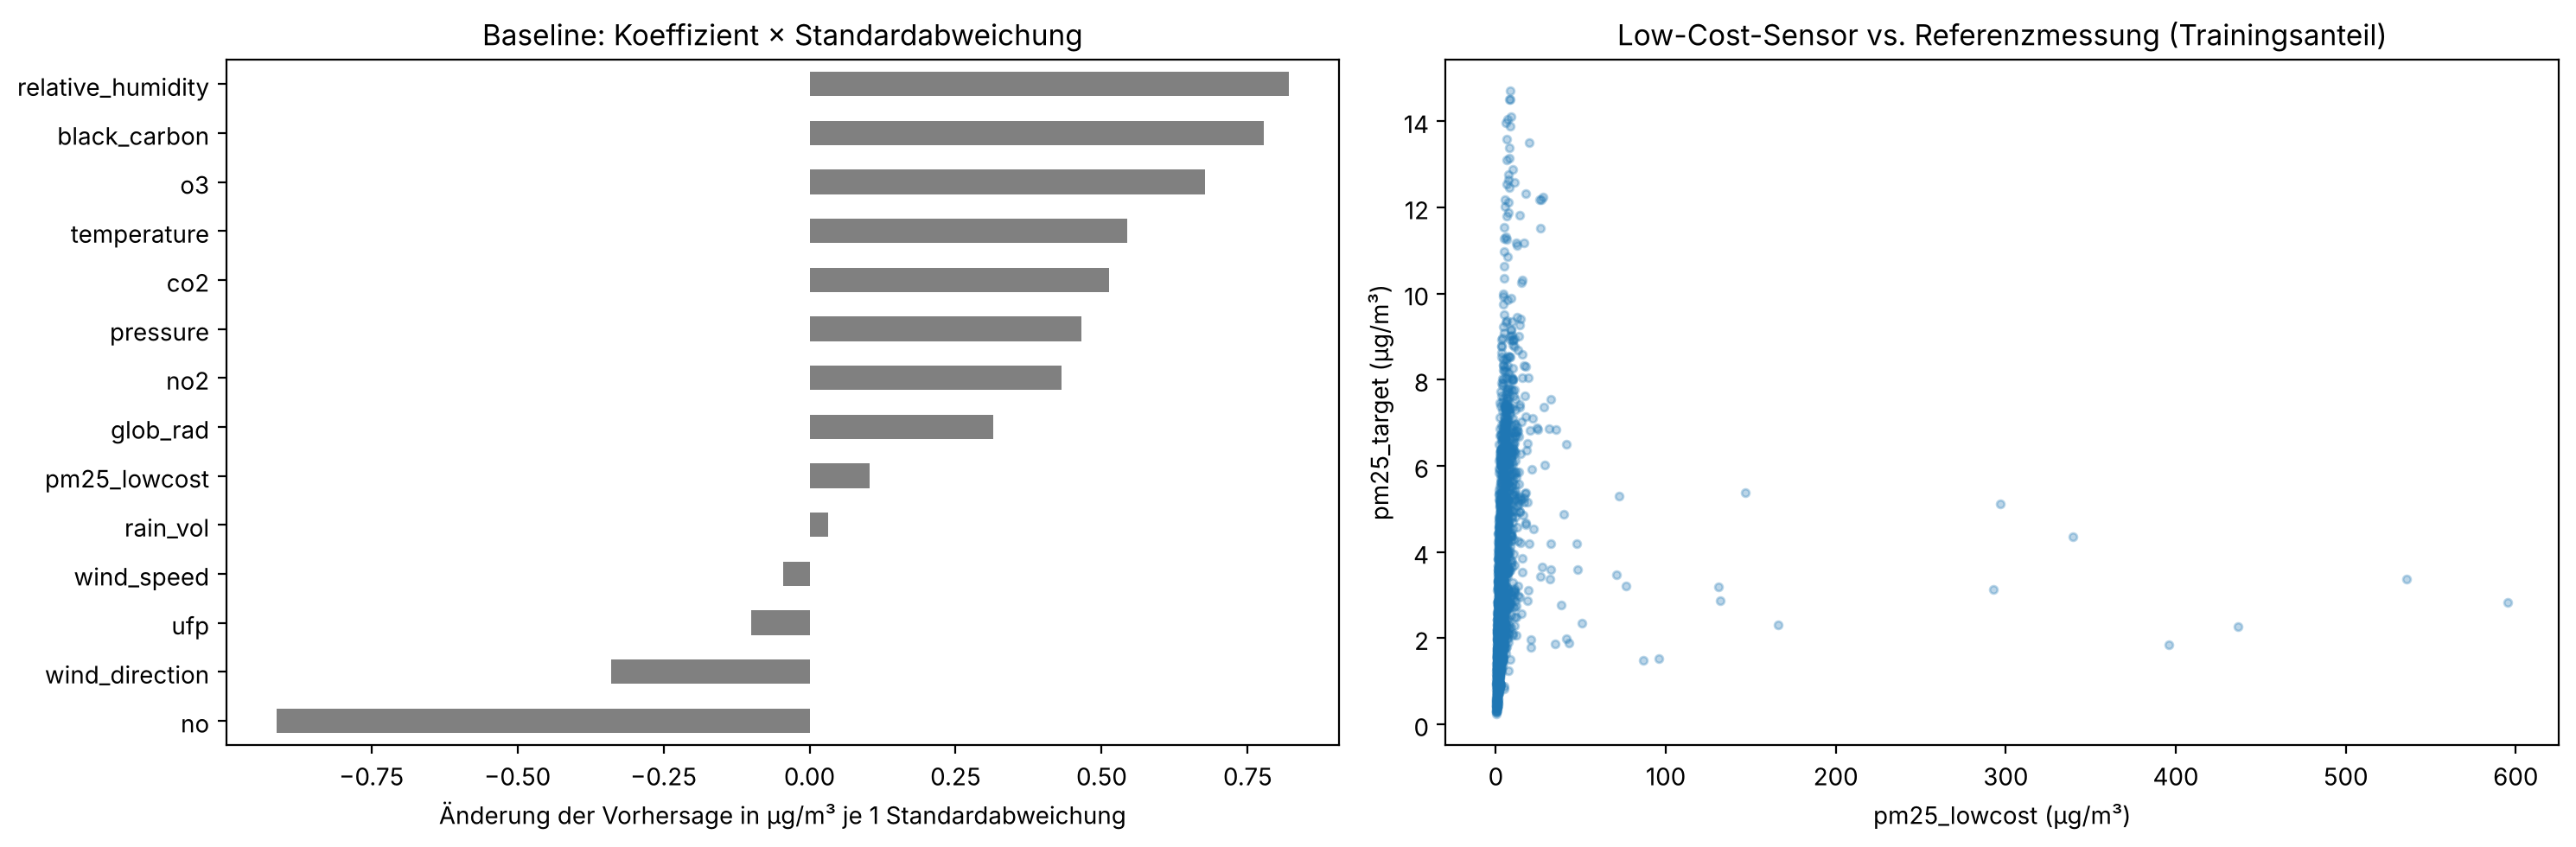

Koeffizient pm25_lowcost: 0.00451
Maximum pm25_target (Referenz): 14.71 µg/m³
Anteil Trainingszeilen mit pm25_lowcost über diesem Maximum: 2.9 %
Maximum pm25_lowcost: 595.53 µg/m³


In [6]:
baseline_importance = pd.Series(baseline_model.coef_ * X_train_base.std().values, index=baseline_features).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

baseline_importance.plot.barh(ax=axes[0], color="grey")
axes[0].set_title("Baseline: Koeffizient × Standardabweichung")
axes[0].set_xlabel("Änderung der Vorhersage in µg/m³ je 1 Standardabweichung")

axes[1].scatter(train_base["pm25_lowcost"], train_base[TARGET], alpha=0.3, s=10)
axes[1].set_title("Low-Cost-Sensor vs. Referenzmessung (Trainingsanteil)")
axes[1].set_xlabel("pm25_lowcost (µg/m³)")
axes[1].set_ylabel("pm25_target (µg/m³)")

plt.tight_layout()
plt.show()

print("Koeffizient pm25_lowcost:", round(baseline_model.coef_[baseline_features.index("pm25_lowcost")], 5))
# Vergleichsgröße: der höchste Wert, den das Referenzgerät im Trainingsanteil je gemessen hat
print("Maximum pm25_target (Referenz):", train_base[TARGET].max(), "µg/m³")
print("Anteil Trainingszeilen mit pm25_lowcost über diesem Maximum:",
      round((train_base["pm25_lowcost"] > train_base[TARGET].max()).mean() * 100, 2), "%")
print("Maximum pm25_lowcost:", train_base["pm25_lowcost"].max(), "µg/m³")

**Interpretation der Baseline:**

- Die Baseline erreicht auf der Validierung einen **MAE von 1,34 µg/m³** bei einem **R² von 0,36**. Bei einem mittleren Label von etwa 3,3 µg/m³ ist das ein Fehler von rund 40 %.
- **Kontrolle gegen Task 1b:** Der Validierungs-MAE von 1,3417 entspricht exakt dem Modell mit allen Features aus Task 1b (Schritt 13). Split und Median-Imputation sind also identisch, und die Ergebnisse beider Tasks lassen sich direkt vergleichen.
- Auffällig ist, dass der Koeffizient von `pm25_lowcost` mit **0,005** praktisch null ist. Das Feature, das fachlich am meisten aussagen sollte, wird vom Modell fast ignoriert.
- Das Streudiagramm legt einen Grund nahe: Wenige extreme Low-Cost-Werte (bis 595 µg/m³) bestimmen die Steigung. Die Referenz misst im Trainingsanteil höchstens 14,7 µg/m³; nur 2,9 % der Low-Cost-Werte liegen darüber, sie sind aber bis zu 40-mal so groß. Das passt zu Task 1b, wo `pm25_lowcost` allein ein R² von nahezu 0 hatte.

**Learning:** Schon die Analyse der Baseline zeigt den vermutlich wichtigsten Hebel. Ob er wirklich wirkt, prüfen wir in M3.

## 4. Werkzeugkasten: die Preprocessing-Module M1–M6

Jedes Problem aus Task 1 wird durch ein eigenes **Modul** behandelt. Alle Module folgen demselben Muster, damit man sie frei kombinieren kann:

```
modul(train_part, other_parts, method)  ->  train_part, other_parts, info
```

- `train_part`: Trainingsanteil – hier werden Parameter **gelernt** (z. B. Median, Kappungsgrenze)
- `other_parts`: Liste aus Validierung und Test – hier werden die gelernten Parameter nur **angewendet**
- `method`: welche Variante des Moduls verwendet wird (z. B. `"median"` oder `"regression"`)
- `info`: was das Modul gelernt bzw. verändert hat (zur Dokumentation)

Eine Ausnahme ist M1: Die Umrechnung des Regenzählers braucht den Wert der **Vorstunde**. Ein zufällig gezogener Validierungsanteil ist keine lückenlose Zeitreihe mehr, deshalb läuft M1 auf der jeweils ganzen Originaldatei (Trainingsdatei bzw. Testdatei). M1 lernt keine Parameter und nutzt kein Label. Ganz ohne Berührung ist es aber nicht: Für eine Trainingszeile kann die Vorstunde im Validierungsanteil liegen. Wir halten das für vertretbar, weil auch im späteren Einsatz der Zählerstand der Vorstunde bekannt ist. Wir nennen es aber bewusst, statt pauschal „keine Leakage" zu behaupten.

| Modul | Problem aus Task 1 | Varianten |
|---|---|---|
| M1 Regelbasierte Korrekturen | physikalisch unmögliche Werte, kumulierter Regenzähler | an / aus |
| M2 Missing Values | fehlende Feature-Werte | Median, Mittelwert, Regressionsimputation, Zeilen löschen (nur Training) |
| M3 Outlier Handling | extreme Sensorwerte | Winsorisierung 95 % / 99 %, IQR-Kappung, Pearson-optimierte Kappung, Log-, Rang-Transformation |
| M4 Scaling | unterschiedliche Wertebereiche | Standardisierung |
| M5 Feature Engineering | Zeitstempel nicht nutzbar, Windrichtung als Kreis, Feuchteeffekt | Tageszeit, Windrichtung, Feuchte-Interaktion |
| M6 Feature Selection | schwache / redundante Features | Korrelationsfilter, VIF-Check |

#### Woher stammen die Methoden?

Wir haben uns bewusst an den Python Labs und Vorlesungen orientiert. Wo wir darüber hinausgehen, ist das in der letzten Spalte gekennzeichnet.

| Modul | Methode | Quelle im Kurs | Eigene Ergänzung |
|---|---|---|---|
| Split, Bewertung | `train_test_split`, `LinearRegression`, MAE, R² | Labs 09c, 10a; Task 1b | – |
| M1 | Plausibilitätsregeln (Werte < 0 auf 0) | Vorlesung Missing Value Handling: „Rule based Imputation" | Umrechnung `rain_vol` → Regen pro Stunde (`diff()`) |
| M2 | Median, Mittelwert (`fillna`), Listwise Deletion, Regressionsimputation | Lab 04 Missing Value Handling (Solution) | – |
| M3 | Winsorisierung, IQR-Grenze, 3-Std-Grenze | Vorlesung + Lab 05 Outlier Handling, `OutlierRemover`-Klasse (Pipeline-Demo 2) | Wahl der Features und Perzentile über Pearson vs. Spearman |
| M3 | Log-, Rang-Transformation (`QuantileTransformer`) | Vorlesung + Lab 06 Transformation | – |
| M4 | `StandardScaler` | Vorlesung Feature Scaling, Pipeline-Labs | – |
| M5 | Kombinierte Features | Vorlesung Transformation: „Combine data" | Tageszeit/Windrichtung als sin/cos (Kreis-Darstellung) |
| M6 | `corrwith(label)`, VIF | Lab 10c Feature Selection for Regression | VIF mit `LinearRegression` statt `statsmodels` berechnet |
| Gesamt | Module nacheinander auf Training fitten und auf Validierung/Test anwenden | Pipeline-Labs (`fit` auf Training, `transform` auf Rest) | Steuerung über ein Konfigurations-Dictionary statt `sklearn.Pipeline` |

### M1 – Regelbasierte Korrekturen

Bei der genaueren Prüfung der Rohdaten sind uns zwei Auffälligkeiten begegnet, die in Task 1 noch nicht behandelt wurden. Zuerst prüfen wir sie, dann leiten wir die Regel ab.

1. **Negative Werte:** Wir prüfen alle numerischen Spalten in Training **und** Test auf Werte unter 0.
2. **Verlauf von `rain_vol`:** Wir prüfen, ob der Wert im Zeitverlauf jemals sinkt.

,negativ Training,negativ Test,Minimum Training,Minimum Test
no,486,99,-2.700,-2.000
o3,0,142,0.400,-1.200
temperature,0,38,5.752,-1.883


,kleinster Wert,Median des Features,Spannweite des Features (Max - Min)
no (Training),-2.7,1.6,1134.4
o3 (Test),-1.2,14.6,37.6


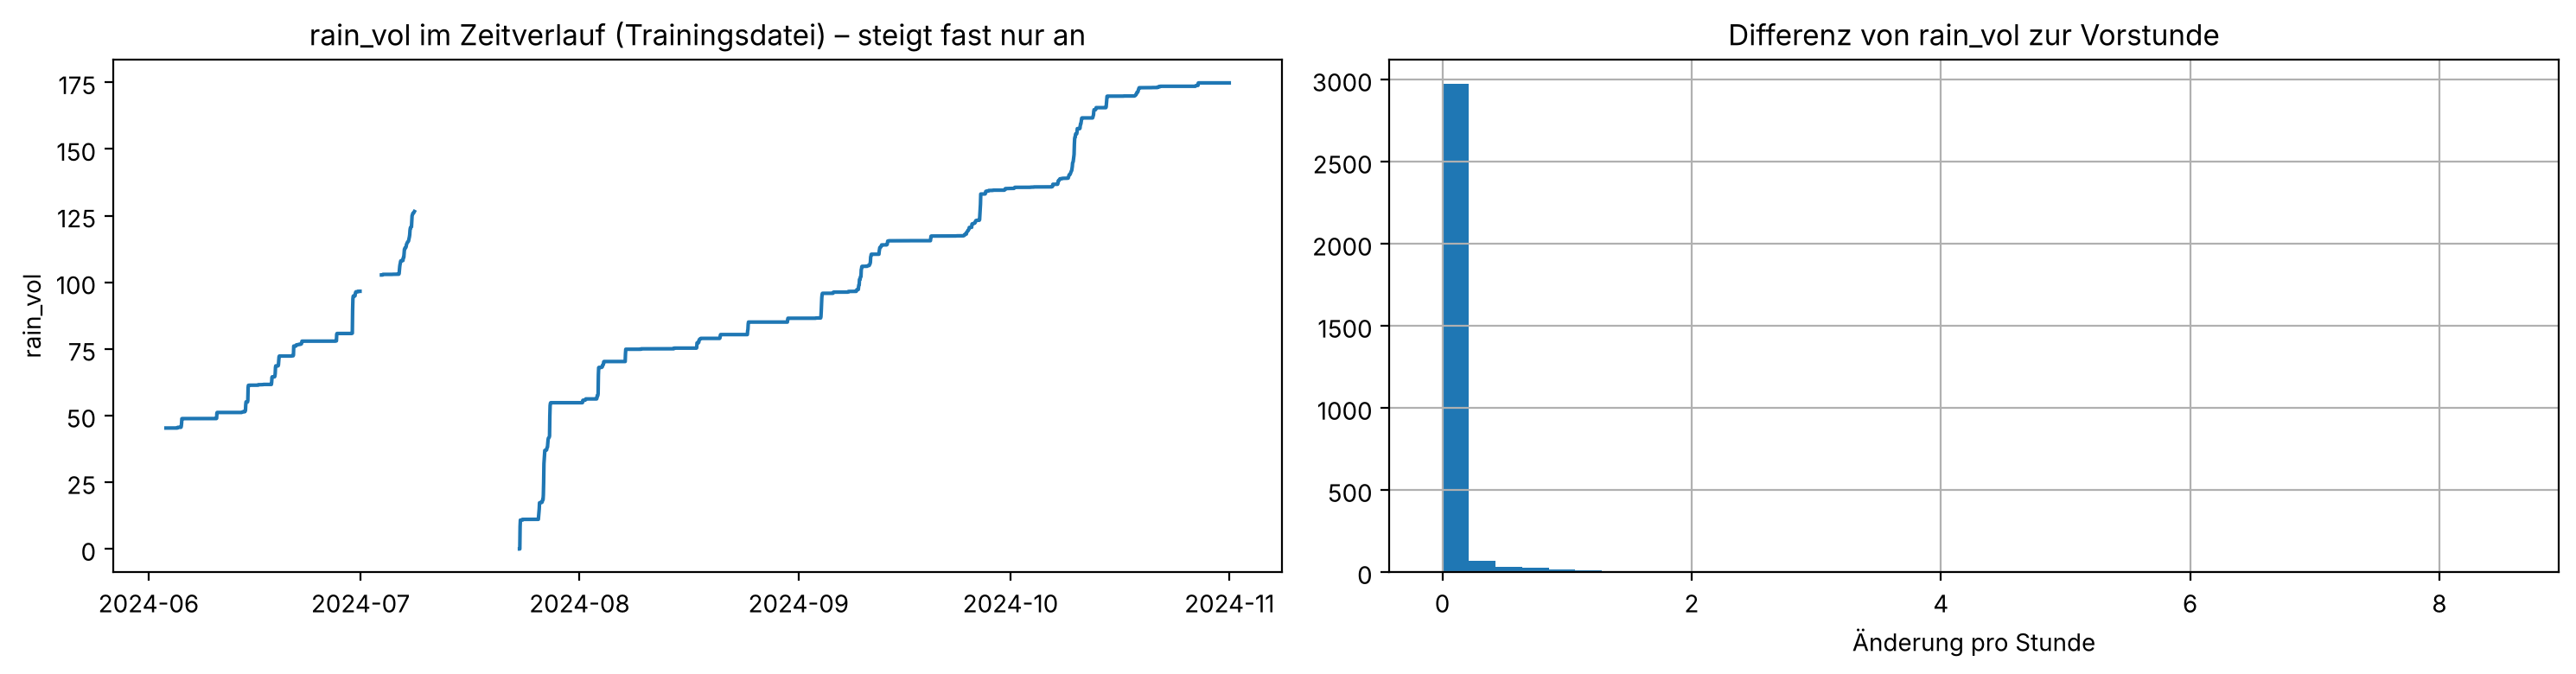

Stunden mit sinkendem rain_vol (Training): 0 von 3182
Stunden mit Anstieg: 517 | ohne Änderung: 2665
rain_vol am Anfang / Ende der Trainingsdatei: 45.35 / 174.82
rain_vol am Anfang der Testdatei: 174.82


In [7]:
numeric_cols = [col for col in raw_train.select_dtypes(include="number").columns if col != TARGET]
negative_check = pd.DataFrame({
    "negativ Training": (raw_train[numeric_cols] < 0).sum(),
    "negativ Test": (raw_test[numeric_cols] < 0).sum(),
    "Minimum Training": raw_train[numeric_cols].min(),
    "Minimum Test": raw_test[numeric_cols].min(),
})
display(negative_check[(negative_check["negativ Training"] > 0) | (negative_check["negativ Test"] > 0)])

# Sind die negativen Werte groß (echte Fehler) oder klein und nahe 0 (Messrauschen)?
# Vergleich: Wie groß sind typische Werte desselben Features?
noise_check = pd.DataFrame({
    "kleinster Wert": [raw_train["no"].min(), raw_test["o3"].min()],
    "Median des Features": [raw_train["no"].median(), raw_test["o3"].median()],
    "Spannweite des Features (Max - Min)": [raw_train["no"].max() - raw_train["no"].min(),
                                            raw_test["o3"].max() - raw_test["o3"].min()],
}, index=["no (Training)", "o3 (Test)"])
display(noise_check.round(2))

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
axes[0].plot(raw_train["timestamp"], raw_train["rain_vol"])
axes[0].set_title("rain_vol im Zeitverlauf (Trainingsdatei) – steigt fast nur an")
axes[0].set_ylabel("rain_vol")
raw_train["rain_vol"].diff().hist(bins=40, ax=axes[1])
axes[1].set_title("Differenz von rain_vol zur Vorstunde")
axes[1].set_xlabel("Änderung pro Stunde")
plt.tight_layout()
plt.show()

rain_diff = raw_train["rain_vol"].diff()
print("Stunden mit sinkendem rain_vol (Training):", int((rain_diff < 0).sum()), "von", int(rain_diff.notna().sum()))
print("Stunden mit Anstieg:", int((rain_diff > 0).sum()), "| ohne Änderung:", int((rain_diff == 0).sum()))
print("rain_vol am Anfang / Ende der Trainingsdatei:", raw_train["rain_vol"].dropna().iloc[0], "/", raw_train["rain_vol"].dropna().iloc[-1])
print("rain_vol am Anfang der Testdatei:", raw_test["rain_vol"].dropna().iloc[0])

In [8]:
# Konzentrationen (Schadstoffe, Partikel) können nicht negativ sein.
# Temperatur ist bewusst NICHT dabei: Minusgrade im Winter (Testdaten) sind echte Werte.
CONCENTRATION_COLS = ["pm25_lowcost", "no", "no2", "o3", "co2", "black_carbon", "ufp"]


def m1_rules(df):
    # Regelbasierte Korrekturen. Keine gelernten Parameter -> wird auf jede Originaldatei als Ganzes angewendet.
    df = df.copy()

    # Regel 1: negative Konzentrationen sind physikalisch unmöglich -> 0
    df[CONCENTRATION_COLS] = df[CONCENTRATION_COLS].clip(lower=0)

    # Regel 2: kumulierten Regenzähler in Regen pro Stunde umrechnen
    # Voraussetzung: Datei ist zeitlich sortiert (stündliches Raster, in Task 1 geprüft)
    assert df["timestamp"].is_monotonic_increasing
    df["rain_hourly"] = df["rain_vol"].diff().clip(lower=0)
    df.loc[df.index[0], "rain_hourly"] = 0      # erste Stunde hat keine Vorstunde
    df = df.drop(columns="rain_vol")
    return df


train_m1 = m1_rules(raw_train)
test_m1 = m1_rules(raw_test)
print("Negative Konzentrationen nach M1 – Training:", int((train_m1[CONCENTRATION_COLS] < 0).sum().sum()),
      "| Test:", int((test_m1[CONCENTRATION_COLS] < 0).sum().sum()))
display(train_m1[["timestamp", "rain_hourly"]].describe().T)

Negative Konzentrationen nach M1 – Training: 0 | Test: 0


,count,mean,min,25%,50%,75%,max,std
timestamp,3613,2024-08-17 17:00:00,2024-06-03 11:00:00,2024-07-11 02:00:00,2024-08-17 17:00:00,2024-09-24 08:00:00,2024-10-31 23:00:00,NaN
rain_hourly,3183.0,0.078521,0.0,0.0,0.0,0.0,8.531,0.440869


**Ergebnis und Begründung M1:**

- **Negative Werte:** Im Training ist nur `no` betroffen (486 Werte, Minimum −2,7). Im **Test** kommen 142 negative `o3`-Werte hinzu. Für Konzentrationen ist ein Wert unter 0 physikalisch nicht möglich. Die zweite Tabelle zeigt, dass die negativen Werte **klein und nahe 0** sind: Bei `no` liegt das Minimum bei −2,7, bei einer Spannweite des Features von über 1.100. Das spricht eher für Messrauschen nahe der Nachweisgrenze als für grobe Fehlmessungen. Auf 0 zu setzen verändert die Werte deshalb nur minimal. Deshalb gilt die Regel für **alle Konzentrations-Features**, nicht nur für `no`. Die 38 negativen Temperaturen im Test sind dagegen echte Wintertemperaturen und bleiben unverändert.
- **`rain_vol`:** Mehrere Beobachtungen sprechen für einen aufsummierten Zähler und nicht für einen Stundenwert:
  1. In 3.182 aufeinanderfolgenden Stunden sinkt der Wert **kein einziges Mal**. Er bleibt meist gleich (2.665 Stunden) und steigt in 517 Stunden.
  2. Er wächst über den Trainingszeitraum von 45,35 auf 174,82.
  3. Die Testdatei beginnt **genau beim letzten Trainingswert** (174,82). Nach dem großen Sensorausfall im Test startet der Wert am 18.12. neu bei 0,7, was zu einem zurückgesetzten Zähler passt.

  Ein Messprotokoll, das das bestätigt, haben wir nicht. Die Umrechnung in Regen pro Stunde ist deshalb eine **begründete Annahme**.

**Learning:** Ein Feature kann „gut aussehen" (keine Ausreißer, normale Werte) und trotzdem anders kodiert sein, als man erwartet. Den Zähler haben wir erst im Zeitverlauf erkannt, nicht über Histogramme oder Boxplots.

### M2 – Missing Value Handling

Aus Task 1 wissen wir, dass vor allem `co2`, `ufp`, `o3` und die Wetterdaten fehlen. Wichtig ist, **wie** die Werte fehlen: einzeln verstreut oder in langen Blöcken. Das entscheidet, welche Methode sinnvoll ist.

In [9]:
def longest_gap(series):
    # Länge des längsten zusammenhängenden NaN-Blocks (in Stunden)
    is_missing = series.isna()
    block_id = (is_missing != is_missing.shift()).cumsum()
    block_lengths = is_missing.groupby(block_id).sum()
    return int(block_lengths.max())


mv_overview = pd.DataFrame({
    "fehlend (Anzahl)": raw_train.isna().sum(),
    "fehlend (%)": (raw_train.isna().mean() * 100).round(1),
    "längster Block (Stunden)": [longest_gap(raw_train[col]) for col in raw_train.columns],
})
display(mv_overview[mv_overview["fehlend (Anzahl)"] > 0].sort_values("fehlend (Anzahl)", ascending=False))

,fehlend (Anzahl),fehlend (%),längster Block (Stunden)
co2,927,25.7,568
ufp,777,21.5,248
o3,747,20.7,513
pm25_lowcost,461,12.8,306
pressure,428,11.8,356
temperature,428,11.8,356
relative_humidity,428,11.8,356
wind_speed,428,11.8,356
wind_direction,428,11.8,356
rain_vol,428,11.8,356


Die meisten Lücken sind **lange Blöcke** (bis zu mehrere Wochen), also Sensorausfälle. Einzelne verstreute Lücken gibt es kaum.

Wir testen vier Varianten aus Lab 04 *Missing Value Handling*:

| Variante | Vorgehen | Erwartung |
|---|---|---|
| `median` | Trainings-Median (= Baseline) | robust gegen Ausreißer |
| `mean` | Trainings-Mittelwert | wird durch Ausreißer verzerrt (z. B. `pm25_lowcost`: Mittelwert 5,5 vs. Median 2,7) |
| `regression` | Regressionsimputation wie im Lab: fehlende Werte von `co2`, `ufp` und `o3` (die drei Features mit den meisten Lücken) werden mit einer linearen Regression aus `no2` und `black_carbon` geschätzt; Rest Median | nutzt die Zusammenhänge zwischen Schadstoffen statt eines festen Werts |
| `drop_rows` | Trainingszeilen ohne `pm25_lowcost` löschen (Listwise Deletion), Rest Median | nur im Training erlaubt; das wichtigste Feature wird nicht „erfunden" |

Für die Regressionsimputation kommen als Prädiktoren nur Features infrage, die im Training fast vollständig sind (`no`, `no2`, `black_carbon`). Sonst müsste man Lücken mit Lücken schätzen. Von diesen wählen wir `no2` und `black_carbon`, weil sie mit den Ziel-Features am stärksten korrelieren (Tabelle unten). Die Regressionsmodelle werden nur auf dem Trainingsanteil gelernt.

**Warum bei `drop_rows` nur Zeilen ohne `pm25_lowcost`?** Würden wir wie im Lab alle Zeilen mit irgendeiner Lücke löschen, verlören wir einen Großteil des Trainings (Zahlen in der Zelle unten). `pm25_lowcost` ist das Feature, auf dem die Fragestellung beruht (Kalibrierung des Low-Cost-Sensors). Dort wiegt ein „erfundener" Median-Wert am schwersten, deshalb testen wir das Löschen gezielt nur für dieses Feature.

Die folgende Zelle belegt die Auswahl der Prädiktoren: Sie zeigt für die drei Features mit den meisten Lücken, wie stark sie im Trainingsanteil mit den fast vollständigen Features korrelieren.

Eine zeitliche Interpolation haben wir bewusst **nicht** verwendet: Sie kommt in den Labs nicht vor, die Lücken sind überwiegend wochenlange Blöcke, und bei zufällig geteilten Daten würden Werte aus Validierungszeilen in Trainingszeilen übernommen.

In [10]:
# Beleg für die Prädiktoren der Regressionsimputation (nur Trainingsanteil)
mv_train = raw_train.loc[train_idx]
candidates = ["no", "no2", "black_carbon"]
predictor_check = mv_train[["co2", "ufp", "o3"] + candidates].corr().loc[["co2", "ufp", "o3"], candidates]
predictor_check["fehlende Werte (Ziel)"] = mv_train[["co2", "ufp", "o3"]].isna().sum()
display(predictor_check.round(2))
print("Fehlende Werte der Prädiktoren im Trainingsanteil:", mv_train[candidates].isna().sum().to_dict())

# Beleg für die Variante drop_rows: Warum löschen wir nur Zeilen ohne pm25_lowcost und nicht alle Zeilen mit Lücken?
feature_cols_mv = [col for col in mv_train.select_dtypes(include="number").columns if col != TARGET]
print("Trainingszeilen gesamt:", len(mv_train))
print("Zeilen mit mindestens einer Lücke (komplette Listwise Deletion):", int(mv_train[feature_cols_mv].isna().any(axis=1).sum()))
print("Zeilen ohne pm25_lowcost (unsere Variante):", int(mv_train["pm25_lowcost"].isna().sum()))

,no,no2,black_carbon,fehlende Werte (Ziel)
co2,0.46,0.68,0.45,756
ufp,0.49,0.58,0.66,458
o3,-0.09,-0.46,-0.16,586


Fehlende Werte der Prädiktoren im Trainingsanteil: {'no': 13, 'no2': 13, 'black_carbon': 0}
Trainingszeilen gesamt: 2727
Zeilen mit mindestens einer Lücke (komplette Listwise Deletion): 1718
Zeilen ohne pm25_lowcost (unsere Variante): 263


In [11]:
# Regressionsimputation (Lab 04): Ziel-Feature -> fast vollständige Prädiktoren
# Auswahl begründet durch die Tabelle in der Zelle darüber (Vollständigkeit + Korrelation im Trainingsanteil)
REGRESSION_IMPUTATION = {
    "co2": ["no2", "black_carbon"],
    "ufp": ["no2", "black_carbon"],
    "o3": ["no2", "black_carbon"],
}


def m2_missing_values(train_part, other_parts, method):
    # Füllt fehlende Feature-Werte. Statistiken kommen ausschließlich aus dem Trainingsanteil.
    train_part = train_part.copy()
    feature_cols = [col for col in train_part.select_dtypes(include="number").columns if col != TARGET]
    info = {"Methode": method}

    if method == "drop_rows":
        # Listwise Deletion – NUR im Training erlaubt
        before = len(train_part)
        train_part = train_part[train_part["pm25_lowcost"].notna()]
        info["gelöschte Trainingszeilen"] = before - len(train_part)

    # Füllwert: Mittelwert oder Median des Trainingsanteils
    if method == "mean":
        fill_values = train_part[feature_cols].mean()
    else:
        fill_values = train_part[feature_cols].median()   # median, regression (Rest), drop_rows (Rest)

    other_parts = [part.copy() for part in other_parts]
    if method == "regression":
        for target_col, predictors in REGRESSION_IMPUTATION.items():
            # Wie im Lab: nur Zeilen ohne fehlende Werte für das Training des Imputationsmodells
            complete = train_part[[target_col] + predictors].dropna()
            reg = LinearRegression().fit(complete[predictors], complete[target_col])
            info[target_col + " R² der Imputation"] = round(reg.score(complete[predictors], complete[target_col]), 3)
            # Schätzen, wo das Ziel fehlt, die Prädiktoren aber vorhanden sind (Rest später per Median)
            for part in [train_part] + other_parts:
                mask = part[target_col].isna() & part[predictors].notna().all(axis=1)
                if mask.any():
                    part.loc[mask, target_col] = reg.predict(part.loc[mask, predictors])

    info["noch fehlende Werte vor dem Füllen (Training)"] = int(train_part[feature_cols].isna().sum().sum())
    train_part[feature_cols] = train_part[feature_cols].fillna(fill_values)

    filled_others = []
    for part in other_parts:
        part = part.copy()
        part[feature_cols] = part[feature_cols].fillna(fill_values)
        filled_others.append(part)
    return train_part, filled_others, info

**Beleg für die Prädiktoren:** `no2` korreliert mit allen drei Ziel-Features deutlich (co2: 0,68, ufp: 0,58, o3: −0,46), `black_carbon` mit co2 und ufp (0,45 bzw. 0,66). `no` korreliert mit o3 kaum (−0,09) und hängt selbst stark mit `no2` zusammen (0,59), deshalb verwenden wir es nicht. Beide Prädiktoren sind im Trainingsanteil fast vollständig (13 bzw. 0 fehlende Werte).

**Einordnung M2:** Die Daten fehlen fast ausschließlich in langen Blöcken (bis zu 568 Stunden am Stück). Bei solchen Ausfällen gibt es keine Nachbarwerte, an denen man sich orientieren könnte. Deshalb erwarten wir von M2 insgesamt nur einen kleinen Effekt. Die Regressionsimputation nutzt immerhin die Zusammenhänge zwischen den Schadstoffen; wie gut das gelingt, zeigt das R² der Imputationsmodelle in Abschnitt 6.

### M3 – Outlier Handling: Pearson vs. Spearman

In der Task-1-Präsentation kam der Hinweis, die **Pearson- und die Spearman-Korrelation** zu vergleichen, weil dabei etwas auffällt, das bei den Ausreißern hilft.

**Was ist der Unterschied?**
- **Pearson** misst den **linearen** Zusammenhang der echten Werte. Ein einzelner extremer Wert kann ihn stark verfälschen, weil er quadratisch in die Berechnung eingeht.
- **Spearman** ist die Pearson-Korrelation der **Ränge** (1., 2., 3. … kleinster Wert). Wie extrem ein Ausreißer ist, spielt dann keine Rolle mehr. Es zählt nur die Reihenfolge. Spearman misst also, ob ein **monotoner** Zusammenhang besteht („je höher A, desto höher B").

**Unsere Idee:** Ist Spearman deutlich höher als Pearson, ist das ein **Hinweis**, dass ein monotoner Zusammenhang durch einzelne extreme Werte verzerrt wird. Ein Beweis ist es allein nicht: Auch ein gekrümmter (nicht linearer) Zusammenhang führt zu einer Lücke. Welche Ursache vorliegt, prüfen wir deshalb anschließend: Schließt eine Kappung der Extremwerte die Lücke, sprechen die Daten für Ausreißer. Bleibt sie bestehen, für Nichtlinearität. Die Korrelationen berechnen wir nur auf dem Trainingsanteil.

,Pearson,Spearman,Lücke (|Spearman| - |Pearson|)
pm25_lowcost,0.080,0.717,0.638
black_carbon,0.269,0.569,0.300
no,0.040,0.224,0.185
no2,0.234,0.357,0.123
ufp,0.250,0.329,0.078
o3,0.005,-0.070,0.065
co2,0.237,0.302,0.065
relative_humidity,0.117,0.175,0.058
rain_vol,-0.008,-0.047,0.040
wind_speed,-0.180,-0.200,0.020


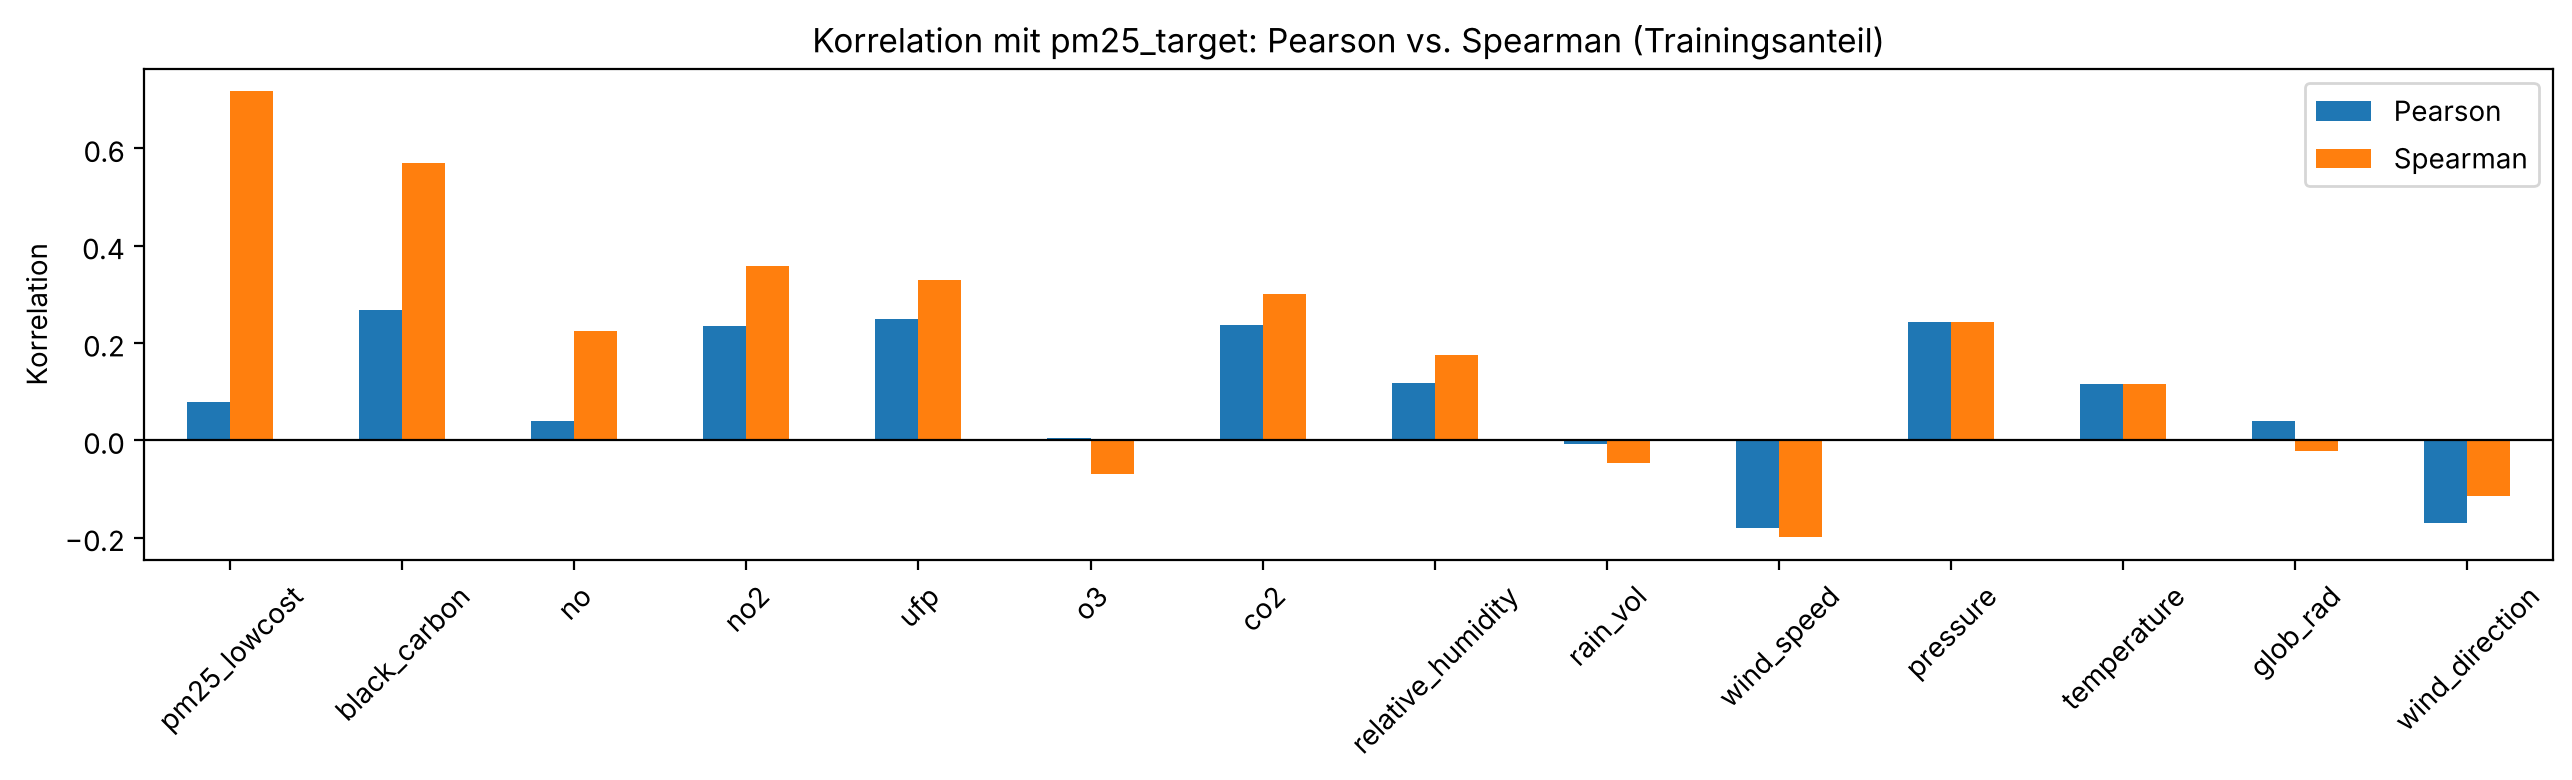

In [12]:
train_corr_base = raw_train.loc[train_idx]
train_corr_base = train_corr_base[train_corr_base[TARGET].notna()]
numeric_train = train_corr_base.select_dtypes(include="number").drop(columns=TARGET)

corr_compare = pd.DataFrame({
    "Pearson": numeric_train.corrwith(train_corr_base[TARGET], method="pearson"),
    "Spearman": numeric_train.corrwith(train_corr_base[TARGET], method="spearman"),
})
corr_compare["Lücke (|Spearman| - |Pearson|)"] = corr_compare["Spearman"].abs() - corr_compare["Pearson"].abs()
corr_compare = corr_compare.sort_values("Lücke (|Spearman| - |Pearson|)", ascending=False)
display(corr_compare.round(3))

corr_compare[["Pearson", "Spearman"]].plot.bar(figsize=(13, 4), rot=45)
plt.title("Korrelation mit pm25_target: Pearson vs. Spearman (Trainingsanteil)")
plt.axhline(0, color="black", linewidth=0.8)
plt.ylabel("Korrelation")
plt.tight_layout()
plt.show()

In [13]:
# Schwelle 0.15: In der sortierten Tabelle liegt der größte Sprung unterhalb von 'no' (0.185 -> 0.123).
# Ob die Schwelle passt, prüfen wir in Abschnitt 6.1 mit 0.10 und 0.25 im Modell.
GAP_THRESHOLD = 0.15
OUTLIER_FEATURES = corr_compare[corr_compare["Lücke (|Spearman| - |Pearson|)"] > GAP_THRESHOLD].index.tolist()
print("Features für das Outlier Handling:", OUTLIER_FEATURES)

Features für das Outlier Handling: ['pm25_lowcost', 'black_carbon', 'no']


**Das ist die Auffälligkeit aus dem Hinweis:** Bei `pm25_lowcost` beträgt die Pearson-Korrelation nur **0,08**, die Spearman-Korrelation dagegen **0,72**. Die **Reihenfolge** der Low-Cost-Werte passt also gut zur Referenz, der **lineare** Zusammenhang der echten Werte kaum. Schwächer gilt dasselbe für `black_carbon` (0,27 vs. 0,57) und `no` (0,04 vs. 0,22).

Was wir daraus ableiten, und was noch nicht:
1. Der Vergleich zeigt, **bei welchen Features** sich eine genauere Prüfung lohnt. Bei Temperatur oder Luftdruck sind beide Werte gleich, dort gibt es keinen Hinweis auf Verzerrung.
2. Er beweist allein noch **nicht**, dass Ausreißer die Ursache sind. Ob eine Kappung die Lücke schließt, prüfen wir in den nächsten Schritten.

#### Pearson vs. Spearman als Korrelationsmatrizen

Bisher haben wir nur die Korrelation jedes Features mit dem Label betrachtet. Eine Ausreißerbehandlung verändert aber auch die Zusammenhänge **zwischen** den Features. Deshalb vergleichen wir die vollständigen Korrelationsmatrizen:

1. **Pearson**: lineare Zusammenhänge der echten Werte
2. **Spearman**: monotone Zusammenhänge der Ränge
3. **Differenz |Spearman| − |Pearson|**: Wo ist sie groß? Dort verdecken Ausreißer (oder ein nicht linearer Verlauf) einen Zusammenhang.

Alle Matrizen werden nur auf dem Trainingsanteil berechnet.

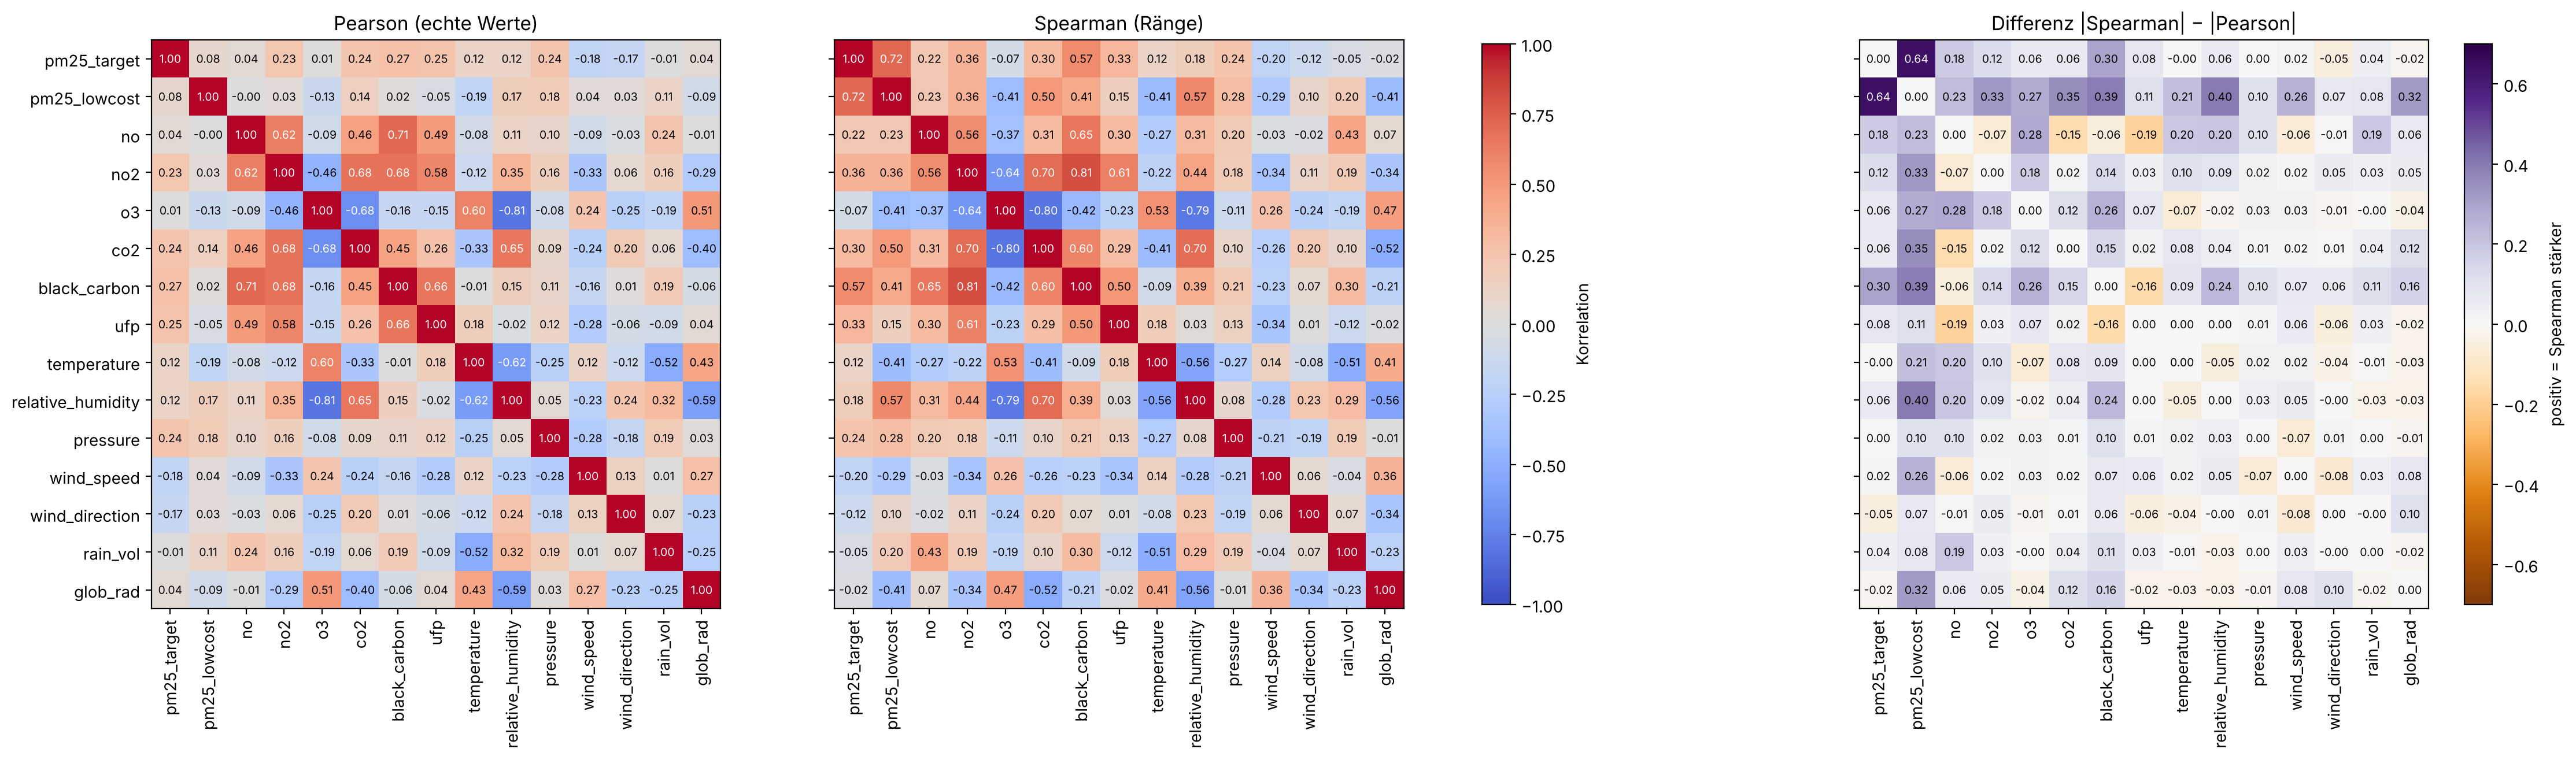

In [14]:
def plot_corr_matrix(matrix, ax, title, vmin=-1, vmax=1, cmap="coolwarm", show_ylabels=True):
    # Korrelationsmatrix als Heatmap mit Zahlenwerten (nur matplotlib, wie in den Labs)
    image = ax.imshow(matrix.values, cmap=cmap, vmin=vmin, vmax=vmax)
    ax.set_xticks(range(len(matrix.columns)))
    ax.set_xticklabels(matrix.columns, rotation=90)
    ax.set_yticks(range(len(matrix.index)))
    ax.set_yticklabels(matrix.index if show_ylabels else [])   # Beschriftung nur links, sonst überlappt sie
    for i in range(len(matrix.index)):
        for j in range(len(matrix.columns)):
            value = matrix.iloc[i, j]
            ax.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=7,
                    color="white" if abs(value) > 0.6 * max(abs(vmin), abs(vmax)) else "black")
    ax.set_title(title)
    return image


numeric_with_label = train_corr_base.select_dtypes(include="number")
pearson_matrix = numeric_with_label.corr(method="pearson")
spearman_matrix = numeric_with_label.corr(method="spearman")
diff_matrix = spearman_matrix.abs() - pearson_matrix.abs()

fig, axes = plt.subplots(1, 3, figsize=(27, 9))
plot_corr_matrix(pearson_matrix, axes[0], "Pearson (echte Werte)")
img = plot_corr_matrix(spearman_matrix, axes[1], "Spearman (Ränge)", show_ylabels=False)
fig.colorbar(img, ax=axes[:2], shrink=0.7, label="Korrelation")
img_diff = plot_corr_matrix(diff_matrix, axes[2], "Differenz |Spearman| − |Pearson|", vmin=-0.7, vmax=0.7, cmap="PuOr",
                            show_ylabels=False)
fig.colorbar(img_diff, ax=axes[2], shrink=0.7, label="positiv = Spearman stärker")
plt.show()

Im zweiten Schritt prüfen wir, ob die Winsorisierung am 95. Perzentil (Vorschlag aus Task 1) die Pearson-Matrix an die Spearman-Matrix heranführt. Dafür kappen wir die drei Ausreißer-Features probeweise auf dem Trainingsanteil und vergleichen die Matrizen für die wichtigsten Features.

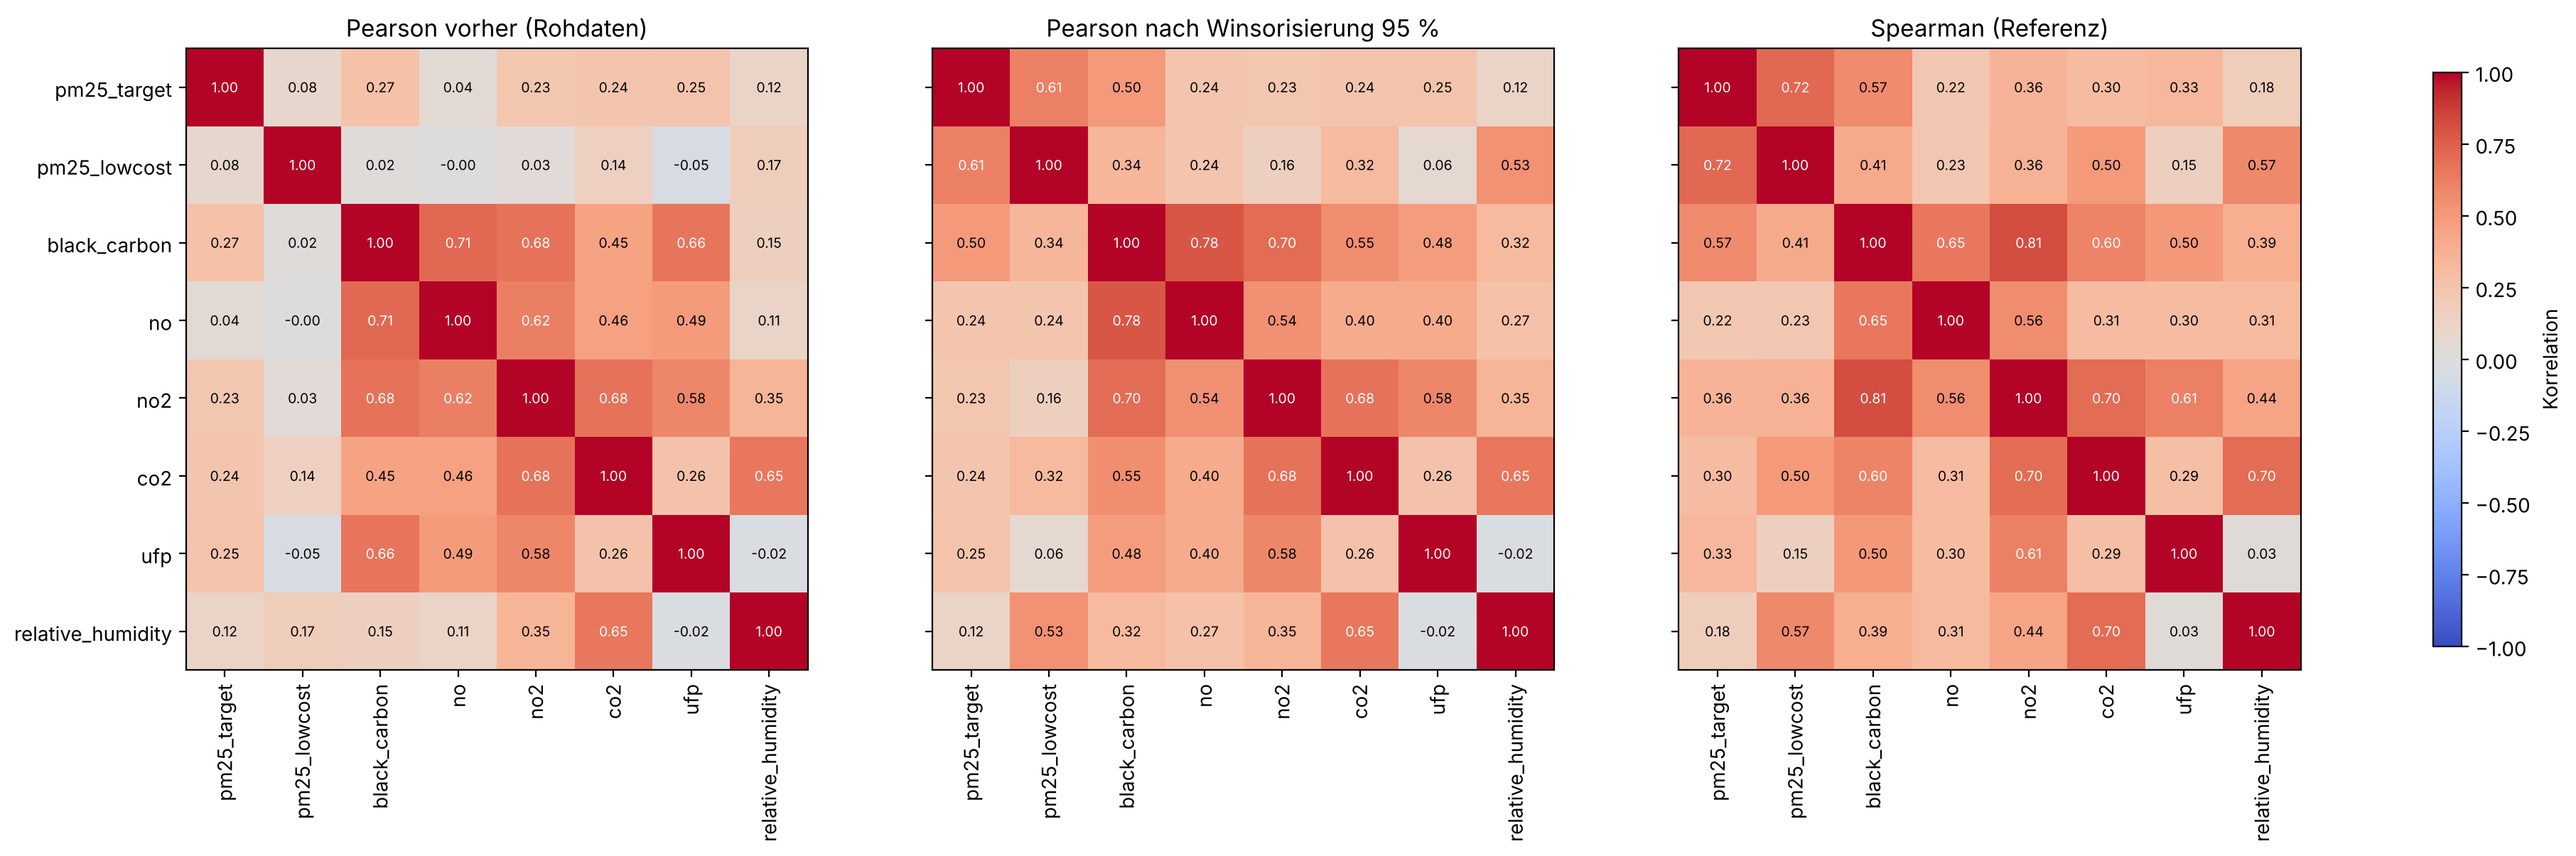

,Pearson vorher,Pearson nach Winsor 95 %,Spearman
pm25_target,0.08,0.61,0.72
black_carbon,0.02,0.34,0.41
no,-0.00,0.24,0.23
no2,0.03,0.16,0.36
co2,0.14,0.32,0.50
ufp,-0.05,0.06,0.15
relative_humidity,0.17,0.53,0.57


In [15]:
matrix_features = [TARGET, "pm25_lowcost", "black_carbon", "no", "no2", "co2", "ufp", "relative_humidity"]

capped_train = train_corr_base[matrix_features].copy()
for feature in OUTLIER_FEATURES:
    capped_train[feature] = capped_train[feature].clip(upper=capped_train[feature].quantile(0.95))

pearson_raw = train_corr_base[matrix_features].corr(method="pearson")
pearson_capped = capped_train.corr(method="pearson")
spearman_sel = train_corr_base[matrix_features].corr(method="spearman")

fig, axes = plt.subplots(1, 3, figsize=(24, 7.5))
plot_corr_matrix(pearson_raw, axes[0], "Pearson vorher (Rohdaten)")
plot_corr_matrix(pearson_capped, axes[1], "Pearson nach Winsorisierung 95 %", show_ylabels=False)
img = plot_corr_matrix(spearman_sel, axes[2], "Spearman (Referenz)", show_ylabels=False)
fig.colorbar(img, ax=axes, shrink=0.7, label="Korrelation")
plt.show()

# Die Zeile von pm25_lowcost im direkten Vergleich
lowcost_row = pd.DataFrame({
    "Pearson vorher": pearson_raw["pm25_lowcost"],
    "Pearson nach Winsor 95 %": pearson_capped["pm25_lowcost"],
    "Spearman": spearman_sel["pm25_lowcost"],
}).drop(index="pm25_lowcost")
display(lowcost_row.round(2))

**Interpretation der Korrelationsmatrizen:**

- **In der Differenzmatrix fällt eine komplette Zeile und Spalte auf: `pm25_lowcost`.** Die Lücke besteht also nicht nur zum Label, sondern zu fast allen anderen Features. Schwächer sieht man dasselbe Muster bei `black_carbon` und `no`.
- **Die Winsorisierung am 95. Perzentil schließt einen Großteil der Lücke.** Pearson mit dem Label steigt von 0,08 auf 0,61 (Spearman: 0,72). Auch die übrige Zeile nähert sich Spearman an, z. B. `pm25_lowcost` ↔ `black_carbon` von 0,02 auf 0,34 (Spearman 0,41). Dass bereits die Kappung von 5 % der Werte so viel bewirkt, **spricht dafür**, dass einzelne Extremwerte den linearen Zusammenhang verzerren.
- **Nebenbefund Luftfeuchte:** Zwischen `pm25_lowcost` und `relative_humidity` liegt Pearson in den Rohdaten bei 0,17, nach der Kappung bei 0,53, Spearman bei 0,57. Diesen Zusammenhang untersuchen wir im nächsten Schritt genauer.
- Ganz erreicht Pearson die Spearman-Werte nicht. Der Rest deutet auf einen zusätzlich **nicht linearen** Zusammenhang hin, den eine Kappung allein nicht linear machen kann.

**Learning:** Die Matrix-Sicht zeigt mehr als die einzelne Korrelation mit dem Label. Erst hier wurde der Zusammenhang zwischen Sensor und Luftfeuchte sichtbar, aus dem später das Feature `lowcost_x_humidity` entstanden ist.

#### Wann und warum entstehen die Ausreißer von `pm25_lowcost`?

Bevor wir Werte verändern, prüfen wir, ob die Ausreißer eher **Messfehler** oder **echte Extremwerte** sind (Empfehlung aus Task 1). Das Label (Referenzgerät) dient dabei als Kontrolle: Wäre die Luft wirklich stark belastet, müsste auch `pm25_target` hoch sein. Eine physikalische Ursache können wir aus den Daten allein nicht beweisen, wir können aber prüfen, ob die Daten zu einer Erklärung passen.

**Was ist ein „Extremwert"?** Wir betrachten Low-Cost-Werte über **30 µg/m³**. Begründung: Das ist rund das Doppelte des höchsten Werts, den das Referenzgerät im Trainingsanteil gemessen hat (14,7 µg/m³, siehe Ausgabe). Solche Werte kann die Referenz in keiner einzigen Stunde bestätigen. Die Schwelle dient nur der Analyse, nicht der späteren Kappung.

Maximum pm25_target im Trainingsanteil: 14.71 µg/m³


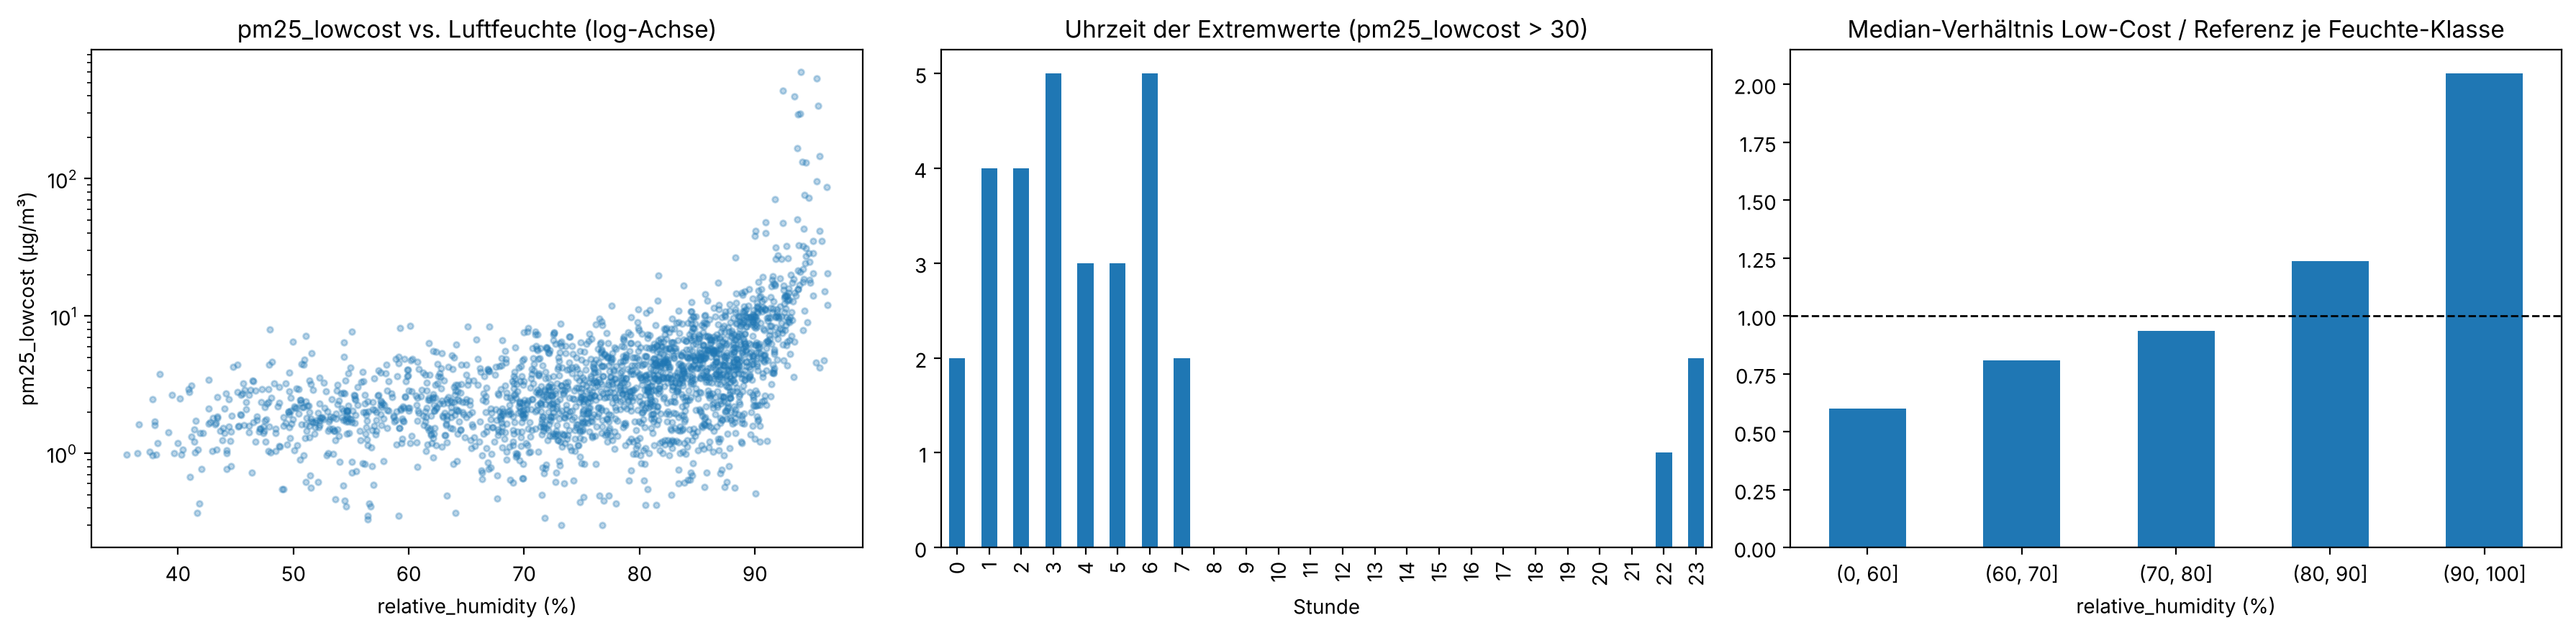

Extremwerte (> 30 µg/m³): 31
Median-Luftfeuchte bei Extremwerten: 94.0 %  | gesamt: 78.8 %
Maximum pm25_target bei diesen Extremwerten: 7.55 µg/m³


In [16]:
lc = train_corr_base.dropna(subset=["pm25_lowcost", "relative_humidity"]).copy()
lc["Verhältnis lowcost / target"] = lc["pm25_lowcost"] / lc[TARGET]
lc["Feuchte-Klasse"] = pd.cut(lc["relative_humidity"], bins=[0, 60, 70, 80, 90, 100])
EXTREME_THRESHOLD = 30   # ca. 2 x Maximum der Referenz
print("Maximum pm25_target im Trainingsanteil:", train_corr_base[TARGET].max(), "µg/m³")
extreme = lc[lc["pm25_lowcost"] > EXTREME_THRESHOLD]

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

axes[0].scatter(lc["relative_humidity"], lc["pm25_lowcost"], s=8, alpha=0.3)
axes[0].set_yscale("log")
axes[0].set_title("pm25_lowcost vs. Luftfeuchte (log-Achse)")
axes[0].set_xlabel("relative_humidity (%)")
axes[0].set_ylabel("pm25_lowcost (µg/m³)")

extreme["timestamp"].dt.hour.value_counts().sort_index().reindex(range(24), fill_value=0).plot.bar(ax=axes[1])
axes[1].set_title("Uhrzeit der Extremwerte (pm25_lowcost > 30)")
axes[1].set_xlabel("Stunde")

lc.groupby("Feuchte-Klasse", observed=True)["Verhältnis lowcost / target"].median().plot.bar(ax=axes[2], rot=0)
axes[2].axhline(1, color="black", linestyle="--", linewidth=1)
axes[2].set_title("Median-Verhältnis Low-Cost / Referenz je Feuchte-Klasse")
axes[2].set_xlabel("relative_humidity (%)")

plt.tight_layout()
plt.show()

print("Extremwerte (> 30 µg/m³):", len(extreme))
print("Median-Luftfeuchte bei Extremwerten:", round(extreme["relative_humidity"].median(), 1), "%  | gesamt:",
      round(lc["relative_humidity"].median(), 1), "%")
print("Maximum pm25_target bei diesen Extremwerten:", extreme[TARGET].max(), "µg/m³")

**Interpretation:** Die Daten sprechen dafür, dass die Extremwerte **Fehlmessungen des Low-Cost-Sensors** sind und keine echte Luftbelastung:
- Sie treten nur zwischen **22 und 7 Uhr** auf, bei einer medianen Luftfeuchte von **94 %** (gesamt: 79 %).
- Die Referenz misst gleichzeitig höchstens **7,6 µg/m³**, also normale Werte.
- Das Verhältnis Low-Cost/Referenz steigt mit der Luftfeuchte gleichmäßig an: unter 60 % misst der Sensor etwa 40 % weniger als die Referenz, über 90 % etwa doppelt so viel.

**Unsere Hypothese:** Optische Low-Cost-Sensoren sind dafür bekannt, bei sehr hoher Luftfeuchte (z. B. nächtlicher Nebel über dem Rhein) zu viel Feinstaub zu messen, weil Partikel Wasser aufnehmen und größer erscheinen. Unsere Daten passen zu dieser Erklärung, beweisen können wir sie damit aber nicht. Es könnte weitere Einflüsse geben, die nachts zusammen mit hoher Feuchte auftreten (z. B. Temperatur).

**Konsequenz für die Data Preparation:**
1. Da die Referenz in diesen Stunden normal misst, halten wir es für gerechtfertigt, die Extremwerte zu **entschärfen**. Löschen dürfen wir sie in Validierung und Test nicht; wir verändern deshalb nur Feature-Werte (Kappung bzw. Transformation).
2. Der Feuchte-Zusammenhang zeigt sich im gesamten Wertebereich, nicht nur bei den Extremwerten. Ob ein Feature daraus hilft, prüfen wir in **M5**.

#### Welche Kappungsgrenze ist die richtige?

Task 1 hat eine Winsorisierung auf das **95. Perzentil** vorgeschlagen, also den Standardwert aus der Vorlesung. Die Vorlesung winsorisiert **beidseitig** (unten am 5., oben am 95. Perzentil). Wir kappen standardmäßig nur nach oben, weil die Probleme nur oben liegen: Die Ausreißer-Features haben keine Werte unter 0 mehr (nach M1), und sehr niedrige Werte bedeuten saubere Luft. Ob diese Annahme stimmt, prüfen wir in Abschnitt 6.1, indem wir die beidseitige Variante aus der Vorlesung direkt dagegen testen. Mit dem Pearson/Spearman-Vergleich können wir die Grenze aber auch **datenbasiert** prüfen. Wir kappen probeweise an verschiedenen Perzentilen und beobachten, wie nah Pearson dabei an Spearman herankommt. Zusätzlich vergleichen wir zwei Transformationen aus der Vorlesung, die Ausreißer ohne feste Grenze entschärfen:

- **Log-Transformation**: staucht große Werte stark zusammen (geeignet für rechtsschiefe Verteilungen). Wir verwenden `log1p` = log(1 + x), weil in den Daten Werte von 0 vorkommen (nach M1) und log(0) nicht definiert ist.
- **Rang-Transformation**: genau der „Raum", in dem Spearman rechnet. Der Wert wird durch seinen Rang ersetzt (umgesetzt mit dem `QuantileTransformer` aus der Vorlesung). Wir wählen `output_distribution="uniform"`, weil das laut Vorlesung genau der Rang-Transformation entspricht (gleichverteilte Ränge). Die Variante `"normal"` wäre der zweite Schritt der Vorlesung (Quantile Transformation), der die Ränge zusätzlich auf eine Normalverteilung abbildet.

,Kappung 0.8,Kappung 0.85,Kappung 0.9,Kappung 0.95,Kappung 0.975,Kappung 0.99,Kappung 1.0,Log,Rang (= Spearman)
pm25_lowcost,0.657,0.661,0.649,0.613,0.558,0.423,0.080,0.563,0.717
black_carbon,0.516,0.521,0.517,0.499,0.477,0.423,0.269,0.459,0.569
no,0.210,0.224,0.235,0.239,0.240,0.220,0.040,0.226,0.224


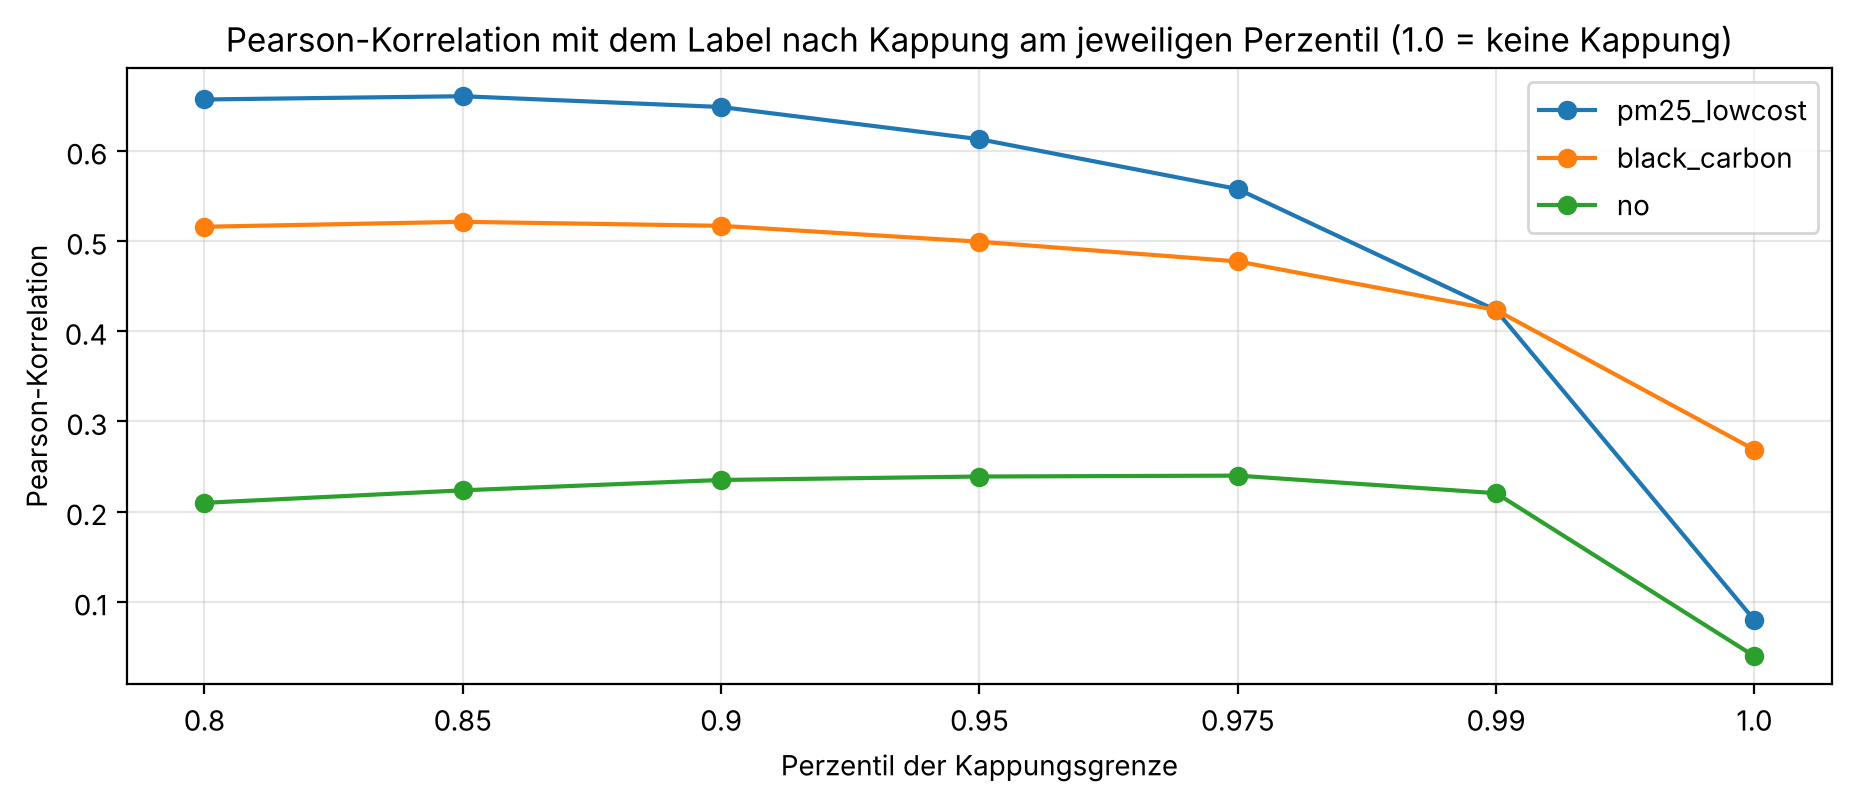

In [17]:
# Geprüfte Perzentile: vom 95. Perzentil der Vorlesung in beide Richtungen, plus 1.0 = keine Kappung als Vergleich
CAP_PERCENTILES = [0.80, 0.85, 0.90, 0.95, 0.975, 0.99]
percentiles = CAP_PERCENTILES + [1.0]
y_corr = train_corr_base[TARGET]

scan_rows = {}
for feature in OUTLIER_FEATURES:
    x = train_corr_base[feature]
    row = {}
    for q in percentiles:
        row["Kappung " + str(q)] = x.clip(upper=x.quantile(q)).corr(y_corr)
    row["Log"] = np.log1p(x.clip(lower=0)).corr(y_corr)
    row["Rang (= Spearman)"] = x.corr(y_corr, method="spearman")
    scan_rows[feature] = row

scan_df = pd.DataFrame(scan_rows).T
display(scan_df.round(3))

kappung_cols = [col for col in scan_df.columns if col.startswith("Kappung")]
scan_df[kappung_cols].T.plot(marker="o", figsize=(11, 4))
plt.xticks(range(len(kappung_cols)), [c.replace("Kappung ", "") for c in kappung_cols])
plt.title("Pearson-Korrelation mit dem Label nach Kappung am jeweiligen Perzentil (1.0 = keine Kappung)")
plt.xlabel("Perzentil der Kappungsgrenze")
plt.ylabel("Pearson-Korrelation")
plt.grid(alpha=0.3)
plt.show()

**Interpretation:**
- Bei `pm25_lowcost` steigt die Pearson-Korrelation durch eine Kappung von 0,08 auf bis zu **0,66** (Kappung am 85. Perzentil). Das 95. Perzentil aus Task 1 erreicht 0,61, das 99. Perzentil nur 0,42.
- Keine Kappung erreicht den Spearman-Wert (0,72). Ein Teil des Zusammenhangs ist offenbar nicht linear und lässt sich durch Kappen allein nicht herstellen.
- Bei `no` verläuft die Kurve flacher. Dort bringt schon eine leichte Kappung (95. bis 97,5. Perzentil) am meisten.
- Log- und Rang-Transformation helfen ebenfalls deutlich, liegen bei der Einzelkorrelation aber unter der besten Kappung.

**Wichtig:** Eine hohe Korrelation zwischen **einem** Feature und dem Label garantiert noch kein besseres **Modell** mit allen Features. Deshalb testen wir alle Varianten im Modell.

#### Wie wir den Hinweis aus der Präsentation verstanden haben

Der Hinweis lautete sinngemäß: Pearson und Spearman vergleichen, dann fällt etwas auf, das bei den Ausreißern hilft. Eine erste Überlegung war die Winsorisierung auf das 95. Perzentil, es gebe aber noch einen „besseren Raum". **Was genau damit gemeint war, wissen wir nicht sicher.** Wir haben deshalb die naheliegenden Lesarten alle geprüft, statt uns auf eine festzulegen:

| Lesart | Wo im Notebook | Ergebnis |
|---|---|---|
| Eine **bessere Kappungsgrenze** als das 95. Perzentil | Pearson-Scan oben; M3-Varianten in Abschnitt 6 | IQR-Grenze minimal besser als 95 %; 99 % zu großzügig; Pearson-optimale Grenze (85 %) zu streng |
| Der **Rangraum**, in dem Spearman rechnet | Rang-Transformation (M3) | hilft deutlich, aber schwächer als Kappung, weil Abstände verloren gehen |
| Der **Log-Raum** | Log-Transformation (M3) | ebenfalls schwächer als Kappung |
| Den Low-Cost-Wert **zusammen mit der Luftfeuchte** betrachten | Feuchte-Analyse (M3), Feuchte-Interaktion (M5) | nach der Kappung der zweitgrößte Hebel |

Die letzte Lesart halten wir für besonders plausibel: Die Lücke zwischen Pearson und Spearman zeigt, dass der Zusammenhang monoton, aber nicht linear ist, und die Korrelationsmatrizen zeigen, dass dahinter ein Zusammenhang mit der Luftfeuchte steht. Die genaue Bedeutung sollte im Coaching geklärt werden. Unsere Ergebnisse decken jede der vier Lesarten ab.

In [18]:
# pearson_opt verwendet dieselben Perzentile wie der Scan oben (CAP_PERCENTILES)


def m3_outliers(train_part, other_parts, method):
    # Behandelt Ausreißer in OUTLIER_FEATURES. Grenzen werden nur auf dem Trainingsanteil bestimmt.
    # Es werden keine Zeilen gelöscht, nur Feature-Werte verändert (in Validierung/Test erlaubt).
    train_part = train_part.copy()
    other_parts = [part.copy() for part in other_parts]
    info = {"Methode": method}

    for feature in OUTLIER_FEATURES:
        x = train_part[feature]

        if method == "winsor95_both":
            # Beidseitige Winsorisierung wie in der Vorlesung (5. und 95. Perzentil) – nur als Kontrollversuch
            lower, upper = x.quantile(0.05), x.quantile(0.95)
            train_part[feature] = train_part[feature].clip(lower=lower, upper=upper)
            for part in other_parts:
                part[feature] = part[feature].clip(lower=lower, upper=upper)

        elif method in ["winsor95", "winsor99", "iqr", "pearson_opt"]:
            # 1) Obergrenze bestimmen (nur nach oben, da kleine Werte = saubere Luft plausibel sind)
            if method == "winsor95":
                upper = x.quantile(0.95)
            elif method == "winsor99":
                upper = x.quantile(0.99)
            elif method == "iqr":
                q1, q3 = x.quantile(0.25), x.quantile(0.75)
                upper = q3 + 1.5 * (q3 - q1)          # obere Boxplot-Grenze (Task 1, Pipeline_Lab2: OutlierRemover)
            else:
                # Perzentil wählen, bei dem die Pearson-Korrelation mit dem Label am höchsten ist
                corr_by_q = {q: x.clip(upper=x.quantile(q)).corr(train_part[TARGET]) for q in CAP_PERCENTILES}
                best_q = max(corr_by_q, key=corr_by_q.get)
                upper = x.quantile(best_q)
                info[feature + " Perzentil"] = best_q
            info[feature + " Obergrenze"] = round(upper, 3)
            # 2) Grenze auf alle Datensätze anwenden
            train_part[feature] = train_part[feature].clip(upper=upper)
            for part in other_parts:
                part[feature] = part[feature].clip(upper=upper)

        elif method == "log":
            # log(1 + x); negative Werte vorher auf 0, da der Logarithmus dort nicht definiert ist
            train_part[feature] = np.log1p(train_part[feature].clip(lower=0))
            for part in other_parts:
                part[feature] = np.log1p(part[feature].clip(lower=0))

        elif method == "rank":
            # Rang-Transformation über den QuantileTransformer (gleichverteilt zwischen 0 und 1)
            # n_quantiles=100: das Lab nutzt 5 Quantile für 9 Zeilen; bei ca. 2.700 Zeilen ist eine feinere Abstufung sinnvoll
            qt = QuantileTransformer(n_quantiles=100, output_distribution="uniform")
            train_part[feature] = qt.fit_transform(train_part[[feature]]).ravel()
            for part in other_parts:
                part[feature] = qt.transform(part[[feature]]).ravel()

    return train_part, other_parts, info

### M4 – Scaling

Task 1 hat empfohlen, eine Standardisierung zu prüfen, weil die Features sehr unterschiedliche Wertebereiche haben (z. B. `ufp` ≈ 10.000 vs. `black_carbon` ≈ 1).

**Unsere Erwartung vorab:** Bei einer *normalen* linearen Regression (ohne Regularisierung) bringt Skalierung **keine** Verbesserung der Vorhersage. Der Grund: Die Standardisierung `x' = (x − Mittelwert) / Std` ist selbst eine lineare Transformation. Das Modell gleicht sie exakt aus, indem es den Koeffizienten mit der Standardabweichung multipliziert und den Achsenabschnitt verschiebt. Die Vorhersagen bleiben identisch, nur die Koeffizienten werden vergleichbar. Wir testen es trotzdem, um die Annahme zu belegen (Feedback Vorjahr: „Kurze Analyse, warum Scaling hier nichts bringt").

Die Vorlesung nennt neben der Z-Standardisierung auch den `RobustScaler` und Min-Max-Normalisierung. Alle drei sind lineare Transformationen (x − a) / b und führen bei der linearen Regression aus demselben Grund zu identischen Vorhersagen. Deshalb testen wir stellvertretend nur den `StandardScaler`.

In [19]:
def m4_scaling(train_part, other_parts, method, feature_cols):
    # Standardisierung: Mittelwert und Standardabweichung kommen nur aus dem Trainingsanteil
    info = {"Methode": method}
    if method != "standard":
        return train_part, other_parts, info

    train_part = train_part.copy()
    scaler = StandardScaler()
    train_part[feature_cols] = scaler.fit_transform(train_part[feature_cols])

    scaled_others = []
    for part in other_parts:
        part = part.copy()
        part[feature_cols] = scaler.transform(part[feature_cols])
        scaled_others.append(part)
    return train_part, scaled_others, info

### M5 – Feature Engineering

Aus den Analysen oben ergeben sich drei neue Features:

1. **Tageszeit (`hour`)**: Die Ausreißer treten fast nur nachts auf, und Luftschadstoffe haben einen Tagesrhythmus (Verkehr, Durchmischung der Luft). Die Stunde als einfache Zahl 0–23 wäre aber irreführend: 23 Uhr und 0 Uhr liegen zeitlich direkt nebeneinander, als Zahl aber 23 auseinander. Deshalb stellen wir die Uhrzeit als Punkt auf einem Kreis dar (`hour_sin`, `hour_cos`).
2. **Windrichtung (`wind`)**: Dasselbe Problem: 359° und 1° sind fast dieselbe Richtung. Auch hier verwenden wir Sinus und Kosinus.
3. **Feuchte-Interaktion (`humidity`)**: In M3 haben wir gesehen, dass das Verhältnis Low-Cost/Referenz mit der Luftfeuchte steigt. Unsere Hypothese ist ein Feuchteeffekt des optischen Sensors. Ob das Feature hilft, entscheidet die Validierung. Eine lineare Regression kann einen solchen Effekt nur erfassen, wenn wir ihn als **kombiniertes Feature** anbieten: `pm25_lowcost × relative_humidity / 100` (Vorlesung Transformation: „Combine data").
   - **Warum ein Produkt?** Die Analyse in M3 zeigt ein **Verhältnis**, das mit der Feuchte steigt: Bei hoher Feuchte misst der Sensor das Doppelte, bei niedriger etwas weniger. Der Fehler ist also proportional zum Messwert. Ein Produkt bildet genau das ab, eine einfache Summe nicht.
   - **Warum / 100?** Die Feuchte wird damit von Prozent in einen Anteil (0–1) umgerechnet. Für die Vorhersage der linearen Regression ändert das nichts (lineare Skalierung, siehe M4), der Wert bleibt aber in der Größenordnung von `pm25_lowcost` und ist leichter zu lesen.

**Wichtig – Reihenfolge:** M5 läuft **nach** dem Outlier Handling. Würde man das Interaktionsfeature aus den ungekappten Werten bilden, würden sich die Ausreißer (bis 595 µg/m³) direkt in das neue Feature übertragen. Belegt wird das in Abschnitt 6/7: „M5 Feuchte-Interaktion (ohne Kappung)" gegen „Kombi M1-M3 + Feuchte-Interaktion".

Bevor wir die Features bauen, prüfen wir die beiden Annahmen zu Tageszeit und Windrichtung in den Daten.

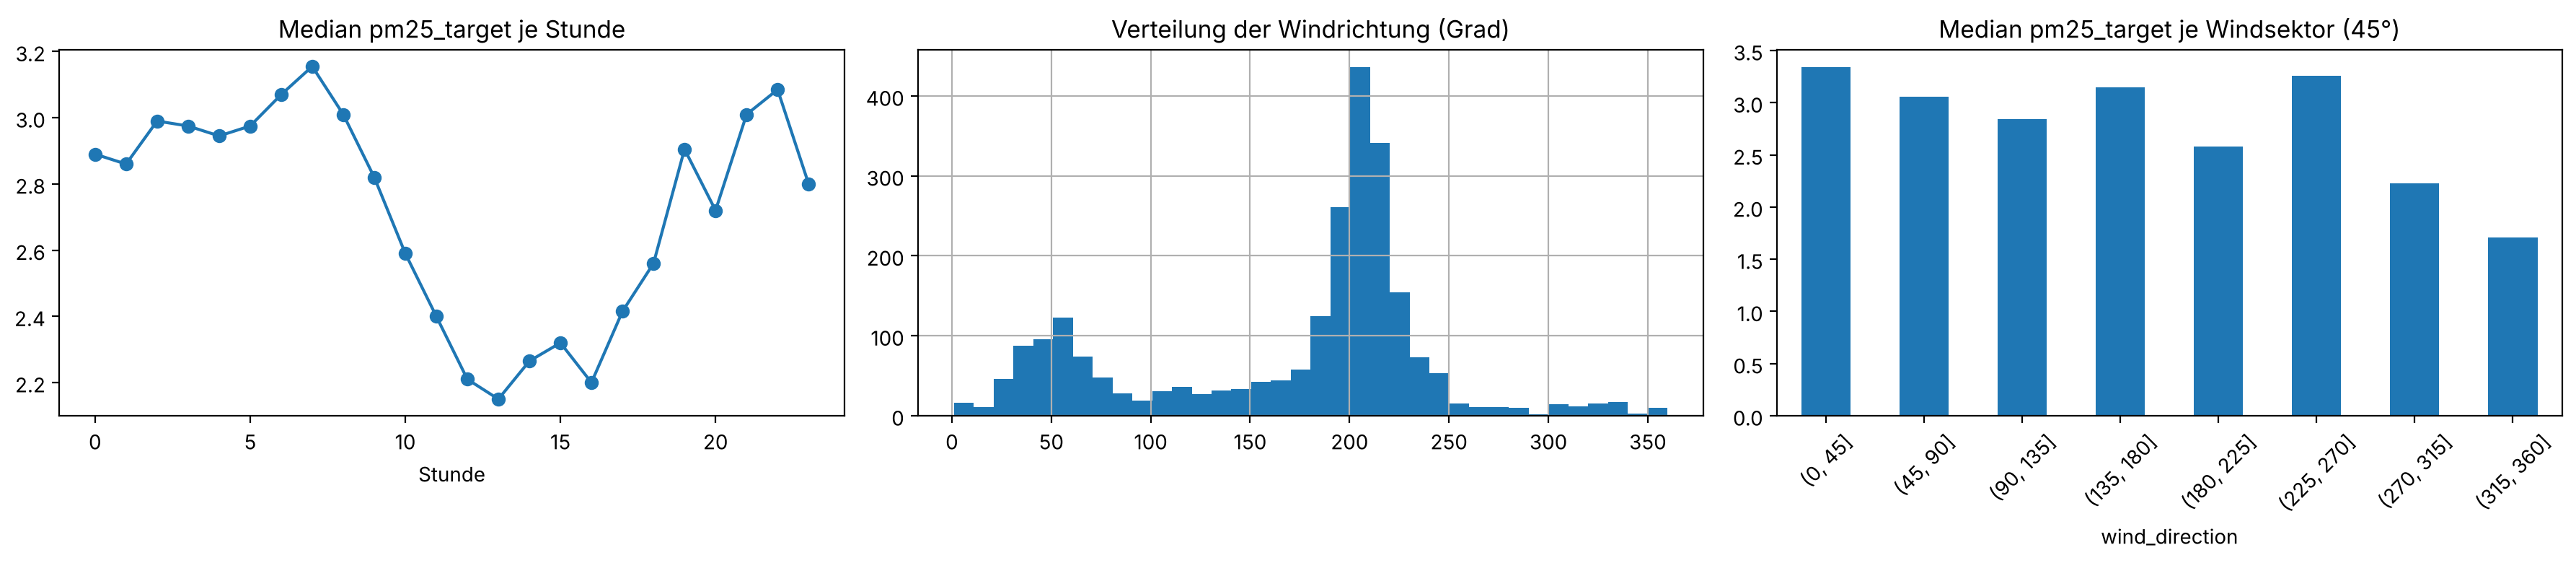

Spannweite der Stunden-Mediane: 2.15 bis 3.16 µg/m³
Windrichtung unter 20°: 26 | über 340°: 13


In [20]:
m5_check = raw_train.loc[train_idx].copy()
fig, axes = plt.subplots(1, 3, figsize=(18, 4))

# Annahme 1: Das Label hat einen Tagesrhythmus
m5_check.groupby(m5_check["timestamp"].dt.hour)[TARGET].median().plot(marker="o", ax=axes[0])
axes[0].set_title("Median pm25_target je Stunde")
axes[0].set_xlabel("Stunde")

# Annahme 2: Windrichtung ist ein Kreis – Werte nahe 0° und nahe 360° kommen beide vor
m5_check["wind_direction"].hist(bins=36, ax=axes[1])
axes[1].set_title("Verteilung der Windrichtung (Grad)")

# ... und das Label unterscheidet sich je Richtung
sector = pd.cut(m5_check["wind_direction"], bins=range(0, 361, 45))
m5_check.groupby(sector, observed=True)[TARGET].median().plot.bar(ax=axes[2], rot=45)
axes[2].set_title("Median pm25_target je Windsektor (45°)")
plt.tight_layout()
plt.show()

hourly = m5_check.groupby(m5_check["timestamp"].dt.hour)[TARGET].median()
print("Spannweite der Stunden-Mediane:", round(hourly.min(), 2), "bis", round(hourly.max(), 2), "µg/m³")
print("Windrichtung unter 20°:", int((m5_check["wind_direction"] < 20).sum()),
      "| über 340°:", int((m5_check["wind_direction"] > 340).sum()))

**Beleg für die beiden Annahmen:**
- **Tagesrhythmus:** Die Stunden-Mediane von `pm25_target` schwanken zwischen 2,2 und 3,2 µg/m³. Die Tageszeit trägt also Information über das Label. Ob das Modell sie zusätzlich zu den Sensoren nutzen kann, zeigt der Test in Abschnitt 6.
- **Windrichtung als Kreis:** Es gibt Werte direkt unter 20° (26) und direkt über 340° (13). Diese Richtungen liegen nebeneinander, als Zahl aber über 300 auseinander. Die sin/cos-Darstellung bringt sie zusammen. Die Mediane je Windsektor unterscheiden sich ebenfalls deutlich (1,7 bis 3,3 µg/m³).

Beide Darstellungen als Kreis gehen über die Labs hinaus (siehe Quellentabelle) und werden deshalb im Modell auf ihren Nutzen geprüft.

In [21]:
def m5_feature_engineering(train_part, other_parts, options):
    # Erzeugt neue Features. Keine gelernten Parameter -> auf alle Datensätze gleich anwenden.
    def add_features(df):
        df = df.copy()
        if "hour" in options:
            hour = df["timestamp"].dt.hour
            df["hour_sin"] = np.sin(2 * np.pi * hour / 24)
            df["hour_cos"] = np.cos(2 * np.pi * hour / 24)
        if "wind" in options:
            radians = np.deg2rad(df["wind_direction"])
            df["wind_dir_sin"] = np.sin(radians)
            df["wind_dir_cos"] = np.cos(radians)
            df = df.drop(columns="wind_direction")
        if "humidity" in options:
            df["lowcost_x_humidity"] = df["pm25_lowcost"] * df["relative_humidity"] / 100
        return df

    info = {"neue Features": options}
    return add_features(train_part), [add_features(part) for part in other_parts], info

### M6 – Feature Selection

Task 1 hat gezeigt, dass mehr Features nicht automatisch bessere Ergebnisse bringen. Wir verwenden die Methoden aus dem Lab *Feature Selection for Regression*:

1. **Korrelationsfilter**: `corrwith(label)` auf dem Trainingsanteil; Features mit |r| < 0,05 werden entfernt. Die Schwelle 0,05 bedeutet „praktisch kein linearer Zusammenhang". Sie ist eine eigene Festlegung, deshalb prüfen wir in Abschnitt 6.1 auch 0,10 und 0,15 (Task 1 hat 0,15 als Relevanzgrenze für die Heatmap verwendet). `pm25_lowcost` bleibt immer erhalten: Die Forschungsfrage lautet, ob man **mit dem Low-Cost-Sensor** die Referenz schätzen kann, und Task 1b schreibt es als Baseline-Feature vor. Ein Modell ohne dieses Feature würde die Frage nicht mehr beantworten.
2. **Multikollinearität (VIF)**: Der Variance Inflation Factor zeigt, wie stark ein Feature durch die anderen Features erklärt wird (VIF = 1 / (1 − R²)). Die Schwelle **VIF ≥ 10** stammt aus der Vorlesung *Feature Selection Part 2* (Folie „VIF: Interpretation and Actions"). Dort steht auch eine wichtige Einschränkung: Multikollinearität sollte vor allem behoben werden, wenn das Ziel die **Interpretation** der Feature-Wichtigkeit ist, nicht die **Vorhersage**. Unser Ziel ist Vorhersage. Wir erwarten deshalb, dass der VIF-Check eher nicht hilft, testen ihn aber. Statt `statsmodels` berechnen wir den VIF direkt mit `LinearRegression`, damit klar ist, was dahinter steckt.

In [22]:
CORR_THRESHOLD = 0.05
VIF_THRESHOLD = 10


def calc_vif(X):
    # VIF je Feature: Wie gut lässt sich das Feature aus allen anderen Features vorhersagen?
    vif = {}
    for col in X.columns:
        others = X.drop(columns=col)
        r2 = LinearRegression().fit(others, X[col]).score(others, X[col])
        vif[col] = 1 / (1 - r2) if r2 < 1 else np.inf
    return pd.Series(vif).sort_values(ascending=False)


def m6_feature_selection(train_part, feature_cols, method):
    # Gibt die ausgewählte Feature-Liste zurück. Entscheidung nur auf Basis des Trainingsanteils.
    info = {"Methode": method}
    if method is None:
        return feature_cols, info

    selected = list(feature_cols)
    if method in ["corr", "corr_vif"]:
        corr = train_part[selected].corrwith(train_part[TARGET]).abs()
        dropped = [col for col in selected if corr[col] < CORR_THRESHOLD and col != "pm25_lowcost"]
        selected = [col for col in selected if col not in dropped]
        info["entfernt (Korrelation)"] = dropped

    if method == "corr_vif":
        dropped_vif = []
        # schrittweise das Feature mit dem höchsten VIF entfernen, bis alle unter der Schwelle liegen
        # pm25_lowcost wird dabei nie entfernt
        while True:
            vif = calc_vif(train_part[selected]).drop("pm25_lowcost", errors="ignore")
            if vif.max() < VIF_THRESHOLD:      # Vorlesung: Handlungsbedarf ab VIF >= 10
                break
            dropped_vif.append(vif.idxmax())
            selected.remove(vif.idxmax())
        info["entfernt (VIF)"] = dropped_vif

    return selected, info

## 5. Pipeline: Module in fester Reihenfolge verbinden

Die Funktion `run_pipeline()` verbindet die Module. Welche Module mit welcher Variante laufen, steuert ein **Konfigurations-Dictionary**. So kann jede Kombination mit einer Zeile erzeugt werden, und der Ablauf ist für alle Experimente identisch.

**Datenfluss:**

```
Originaldateien (Training / Test)
   │  M1  Regelkorrekturen              (ganze Datei, keine gelernten Parameter)
   ▼
Split über feste Indizes aus Abschnitt 1  →  train_part | val_part | test_part
   │  M2  Missing Values   ─┐
   │  M3  Outlier Handling  │  Parameter werden auf train_part gelernt
   │  M5  Feature Eng.      │  und auf val_part / test_part angewendet
   │  M6  Feature Selection │
   │  M4  Scaling          ─┘
   ▼
X_train, y_train | X_val, y_val | X_test, y_test
```

**Begründung der Reihenfolge:**
- **M1 vor M3:** Der Logarithmus ist für negative Werte nicht definiert. Diesen Fehler haben wir beim ersten Testen tatsächlich bekommen (NaN nach `np.log1p`); die Zelle unter diesem Text zeigt es.
- **M2 vor M3:** Die Kappungsgrenzen werden auf den bereits gefüllten Trainingsdaten berechnet. Die gefüllten Mediane liegen weit unter jeder Obergrenze und verschieben die Grenzen deshalb kaum. Die zweite Zelle unter diesem Text belegt das.
- **M3 vor M5:** Das Interaktionsfeature soll aus bereits gekappten Werten gebildet werden.
- **M4 zum Schluss:** Die Skalierung soll auf die finalen Features angewendet werden.

In [23]:
# Beleg für die Reihenfolge M2 vor M3: Wie stark verschiebt die Median-Imputation die Kappungsgrenzen?
order_check = raw_train.loc[train_idx]
rows = []
for feature in OUTLIER_FEATURES:
    without_fill = order_check[feature].quantile(0.95)
    with_fill = order_check[feature].fillna(order_check[feature].median()).quantile(0.95)
    rows.append({"Feature": feature, "95. Perzentil ohne Füllen": without_fill, "95. Perzentil nach Median-Füllung": with_fill,
                 "Median (Füllwert)": order_check[feature].median()})
display(pd.DataFrame(rows).round(3))

,Feature,95. Perzentil ohne Füllen,95. Perzentil nach Median-Füllung,Median (Füllwert)
0,pm25_lowcost,11.315,10.988,2.750
1,black_carbon,2.264,2.264,0.624
2,no,24.100,24.070,1.600


In [24]:
# Beleg für die Reihenfolge M1 vor M3: log(1 + x) ist für den kleinsten no-Wert nicht definiert
with np.errstate(invalid="ignore"):          # die Warnung ist hier gewollt, das NaN ist der Beleg
    print("np.log1p(", raw_train["no"].min(), ") =", np.log1p(raw_train["no"].min()))

np.log1p( -2.7 ) = nan


In [25]:
BASE_CONFIG = {
    "M1_rules": False,       # True / False
    "M2_missing": "median",  # "median", "mean", "regression", "drop_rows"
    "M3_outliers": None,     # None, "winsor95", "winsor99", "iqr", "pearson_opt", "log", "rank"
    "M4_scaling": None,      # None, "standard"
    "M5_features": [],       # Liste aus "hour", "wind", "humidity"
    "M6_selection": None,    # None, "corr", "corr_vif"
}

NON_FEATURES = ["timestamp", "year_month", TARGET]


def run_pipeline(config):
    # Führt alle Module gemäß config aus und gibt die vorbereiteten Datensätze zurück
    cfg = BASE_CONFIG.copy()
    cfg.update(config)
    info = {}

    # Schritt 1: M1 braucht den Zeitbezug (Vorstunde) -> auf den ganzen Originaldateien
    train_file, test_file = raw_train.copy(), raw_test.copy()
    if cfg["M1_rules"]:
        train_file, test_file = m1_rules(train_file), m1_rules(test_file)

    # Schritt 2: Split über die festen Indizes aus Abschnitt 1 (identisch mit Task 1b)
    train_part = train_file.loc[train_idx]
    val_part = train_file.loc[val_idx]
    test_part = test_file

    # Schritt 3: Module mit gelernten Parametern (fit auf train_part)
    train_part, (val_part, test_part), info["M2"] = m2_missing_values(train_part, [val_part, test_part], cfg["M2_missing"])
    if cfg["M3_outliers"] is not None:
        train_part, (val_part, test_part), info["M3"] = m3_outliers(train_part, [val_part, test_part], cfg["M3_outliers"])
    if cfg["M5_features"]:
        train_part, (val_part, test_part), info["M5"] = m5_feature_engineering(train_part, [val_part, test_part], cfg["M5_features"])

    feature_cols = [col for col in train_part.columns if col not in NON_FEATURES]
    feature_cols, info["M6"] = m6_feature_selection(train_part, feature_cols, cfg["M6_selection"])
    train_part, (val_part, test_part), info["M4"] = m4_scaling(train_part, [val_part, test_part], cfg["M4_scaling"], feature_cols)

    # Sicherheitsprüfungen: Validierung und Test vollständig, Labels unverändert
    assert len(val_part) == len(val_idx) and len(test_part) == len(raw_test)
    assert val_part[TARGET].equals(raw_train.loc[val_idx, TARGET])
    assert test_part[TARGET].equals(raw_test[TARGET])
    for part in [train_part, val_part, test_part]:
        assert part[feature_cols].isna().sum().sum() == 0

    return {"train": train_part, "val": val_part, "test": test_part, "features": feature_cols, "info": info}


def run_experiment(name, module, description, config):
    # Pipeline ausführen, lineare Regression trainieren, Ergebnis ins Log schreiben
    data = run_pipeline(config)
    feats = data["features"]
    _, metrics = evaluate_model(data["train"][feats], data["train"][TARGET], data["val"][feats], data["val"][TARGET])
    return log_result(name, module, description, len(feats), metrics), data

**Kontrolle:** Die Pipeline ohne aktivierte Module muss exakt die Baseline aus Abschnitt 3 ergeben. So stellen wir sicher, dass die Pipeline korrekt arbeitet. Das Ergebnis wird nicht ins Log geschrieben.

In [26]:
check = run_pipeline({})
_, check_metrics = evaluate_model(check["train"][check["features"]], check["train"][TARGET],
                                  check["val"][check["features"]], check["val"][TARGET])
print("Baseline direkt:  ", round(baseline_metrics["MAE_val"], 6))
print("Baseline Pipeline:", round(check_metrics["MAE_val"], 6))
assert abs(check_metrics["MAE_val"] - baseline_metrics["MAE_val"]) < 1e-9

Baseline direkt:   1.341701
Baseline Pipeline: 1.341701


## 6. Experimente: jedes Modul einzeln

Jedes Modul wird zunächst **allein** auf die Baseline gesetzt. So sehen wir den isolierten Effekt jeder Maßnahme. Die Experimente werden in einer Liste definiert und in einer Schleife ausgeführt.

In [27]:
single_experiments = [
    # (sprechender Name, Modul, Beschreibung, Konfiguration)
    ("M1 Regelkorrekturen (Konzentrationen >= 0, Regen pro Stunde)", "M1", "negative Konzentrationen auf 0, rain_vol -> rain_hourly",
     {"M1_rules": True}),

    ("M2 Mittelwert-Imputation", "M2", "NaN durch Trainings-Mittelwert statt Median", {"M2_missing": "mean"}),
    ("M2 Regressionsimputation (co2, ufp, o3)", "M2", "Lineare Regression aus no2 und black_carbon (Lab 04), Rest Median",
     {"M2_missing": "regression"}),
    ("M2 Zeilen ohne pm25_lowcost löschen (nur Training)", "M2", "Listwise Deletion im Training, Rest Median",
     {"M2_missing": "drop_rows"}),

    ("M3 Winsorisierung 95. Perzentil", "M3", "Kappung oben am 95. Perzentil (Vorschlag Task 1)",
     {"M3_outliers": "winsor95"}),
    ("M3 Winsorisierung 99. Perzentil", "M3", "Kappung oben am 99. Perzentil", {"M3_outliers": "winsor99"}),
    ("M3 IQR-Kappung (Boxplot-Grenze)", "M3", "Kappung an Q3 + 1,5 * IQR", {"M3_outliers": "iqr"}),
    ("M3 Pearson-optimierte Kappung", "M3", "Perzentil mit maximaler Pearson-Korrelation je Feature",
     {"M3_outliers": "pearson_opt"}),
    ("M3 Log-Transformation", "M3", "log(1 + x) für Ausreißer-Features", {"M3_outliers": "log"}),
    ("M3 Rang-Transformation", "M3", "QuantileTransformer (Rangraum wie Spearman)", {"M3_outliers": "rank"}),

    ("M4 Standardisierung", "M4", "StandardScaler auf alle Features", {"M4_scaling": "standard"}),

    ("M5 Tageszeit (sin/cos)", "M5", "hour_sin, hour_cos aus timestamp", {"M5_features": ["hour"]}),
    ("M5 Windrichtung (sin/cos)", "M5", "wind_direction -> wind_dir_sin, wind_dir_cos", {"M5_features": ["wind"]}),
    ("M5 Feuchte-Interaktion (ohne Kappung)", "M5", "pm25_lowcost * relative_humidity / 100",
     {"M5_features": ["humidity"]}),

    ("M6 Korrelationsfilter (|r| < 0.05 entfernen)", "M6", "corrwith auf Trainingsanteil", {"M6_selection": "corr"}),
    ("M6 Korrelationsfilter + VIF-Check", "M6", "zusätzlich Features mit VIF > 10 entfernen",
     {"M6_selection": "corr_vif"}),
]

experiment_data = {}   # vorbereitete Daten je Experiment, z. B. für den späteren Export
for name, module, description, config in single_experiments:
    log_df, experiment_data[name] = run_experiment(name, module, description, config)

show_results(log_df)

,Modell,Anzahl Features,MAE_train,MAE_val,R2_val,Delta MAE (abs),Delta MAE (%),Overfitting-Lücke (MAE_val - MAE_train)
0,"Baseline (alle Features, Median-Imputation)",14,1.3261,1.3417,0.3590,0.0000,0.0000,0.0156
1,"M1 Regelkorrekturen (Konzentrationen >= 0, Reg...",14,1.3263,1.3420,0.3594,-0.0003,-0.0205,0.0157
2,M2 Mittelwert-Imputation,14,1.3290,1.3439,0.3596,-0.0022,-0.1629,0.0149
3,"M2 Regressionsimputation (co2, ufp, o3)",14,1.2987,1.3265,0.3904,0.0152,1.1345,0.0278
4,M2 Zeilen ohne pm25_lowcost löschen (nur Train...,14,1.3406,1.2951,0.4211,0.0466,3.4724,-0.0454
5,M3 Winsorisierung 95. Perzentil,14,0.8513,0.8792,0.6854,0.4625,34.4724,0.0279
6,M3 Winsorisierung 99. Perzentil,14,1.0597,1.0680,0.5249,0.2737,20.3988,0.0084
7,M3 IQR-Kappung (Boxplot-Grenze),14,0.8307,0.8545,0.7163,0.4872,36.3150,0.0238
8,M3 Pearson-optimierte Kappung,14,0.8317,0.8820,0.6954,0.4597,34.2645,0.0503
9,M3 Log-Transformation,14,0.8887,0.8900,0.6293,0.4517,33.6631,0.0014


Was haben die Module im Detail gelernt bzw. verändert? Die `info`-Ausgaben dokumentieren das, z. B. die Kappungsgrenzen in M3 und die entfernten Features in M6.

In [28]:
for name in ["M2 Regressionsimputation (co2, ufp, o3)", "M2 Zeilen ohne pm25_lowcost löschen (nur Training)", "M3 Winsorisierung 95. Perzentil",
             "M3 IQR-Kappung (Boxplot-Grenze)", "M3 Pearson-optimierte Kappung",
             "M6 Korrelationsfilter (|r| < 0.05 entfernen)", "M6 Korrelationsfilter + VIF-Check"]:
    module = name.split(" ")[0]
    print(name, "->", experiment_data[name]["info"][module])

M2 Regressionsimputation (co2, ufp, o3) -> {'Methode': 'regression', 'co2 R² der Imputation': 0.459, 'ufp R² der Imputation': 0.505, 'o3 R² der Imputation': 0.258, 'noch fehlende Werte vor dem Füllen (Training)': 2492}
M2 Zeilen ohne pm25_lowcost löschen (nur Training) -> {'Methode': 'drop_rows', 'gelöschte Trainingszeilen': 263, 'noch fehlende Werte vor dem Füllen (Training)': 3751}
M3 Winsorisierung 95. Perzentil -> {'Methode': 'winsor95', 'pm25_lowcost Obergrenze': np.float64(10.988), 'black_carbon Obergrenze': np.float64(2.264), 'no Obergrenze': np.float64(24.07)}
M3 IQR-Kappung (Boxplot-Grenze) -> {'Methode': 'iqr', 'pm25_lowcost Obergrenze': np.float64(8.825), 'black_carbon Obergrenze': np.float64(2.039), 'no Obergrenze': np.float64(11.4)}
M3 Pearson-optimierte Kappung -> {'Methode': 'pearson_opt', 'pm25_lowcost Perzentil': 0.85, 'pm25_lowcost Obergrenze': np.float64(6.222), 'black_carbon Perzentil': 0.85, 'black_carbon Obergrenze': np.float64(1.372), 'no Perzentil': 0.975, 'no O

In [29]:
# VIF der Baseline-Features (zur Einordnung von M6)
display(calc_vif(experiment_data["M4 Standardisierung"]["train"][baseline_features]).round(2).to_frame("VIF"))

,VIF
black_carbon,3.39
no2,3.23
no,3.04
relative_humidity,2.94
o3,2.81
temperature,2.45
co2,2.39
ufp,1.82
glob_rad,1.76
rain_vol,1.64


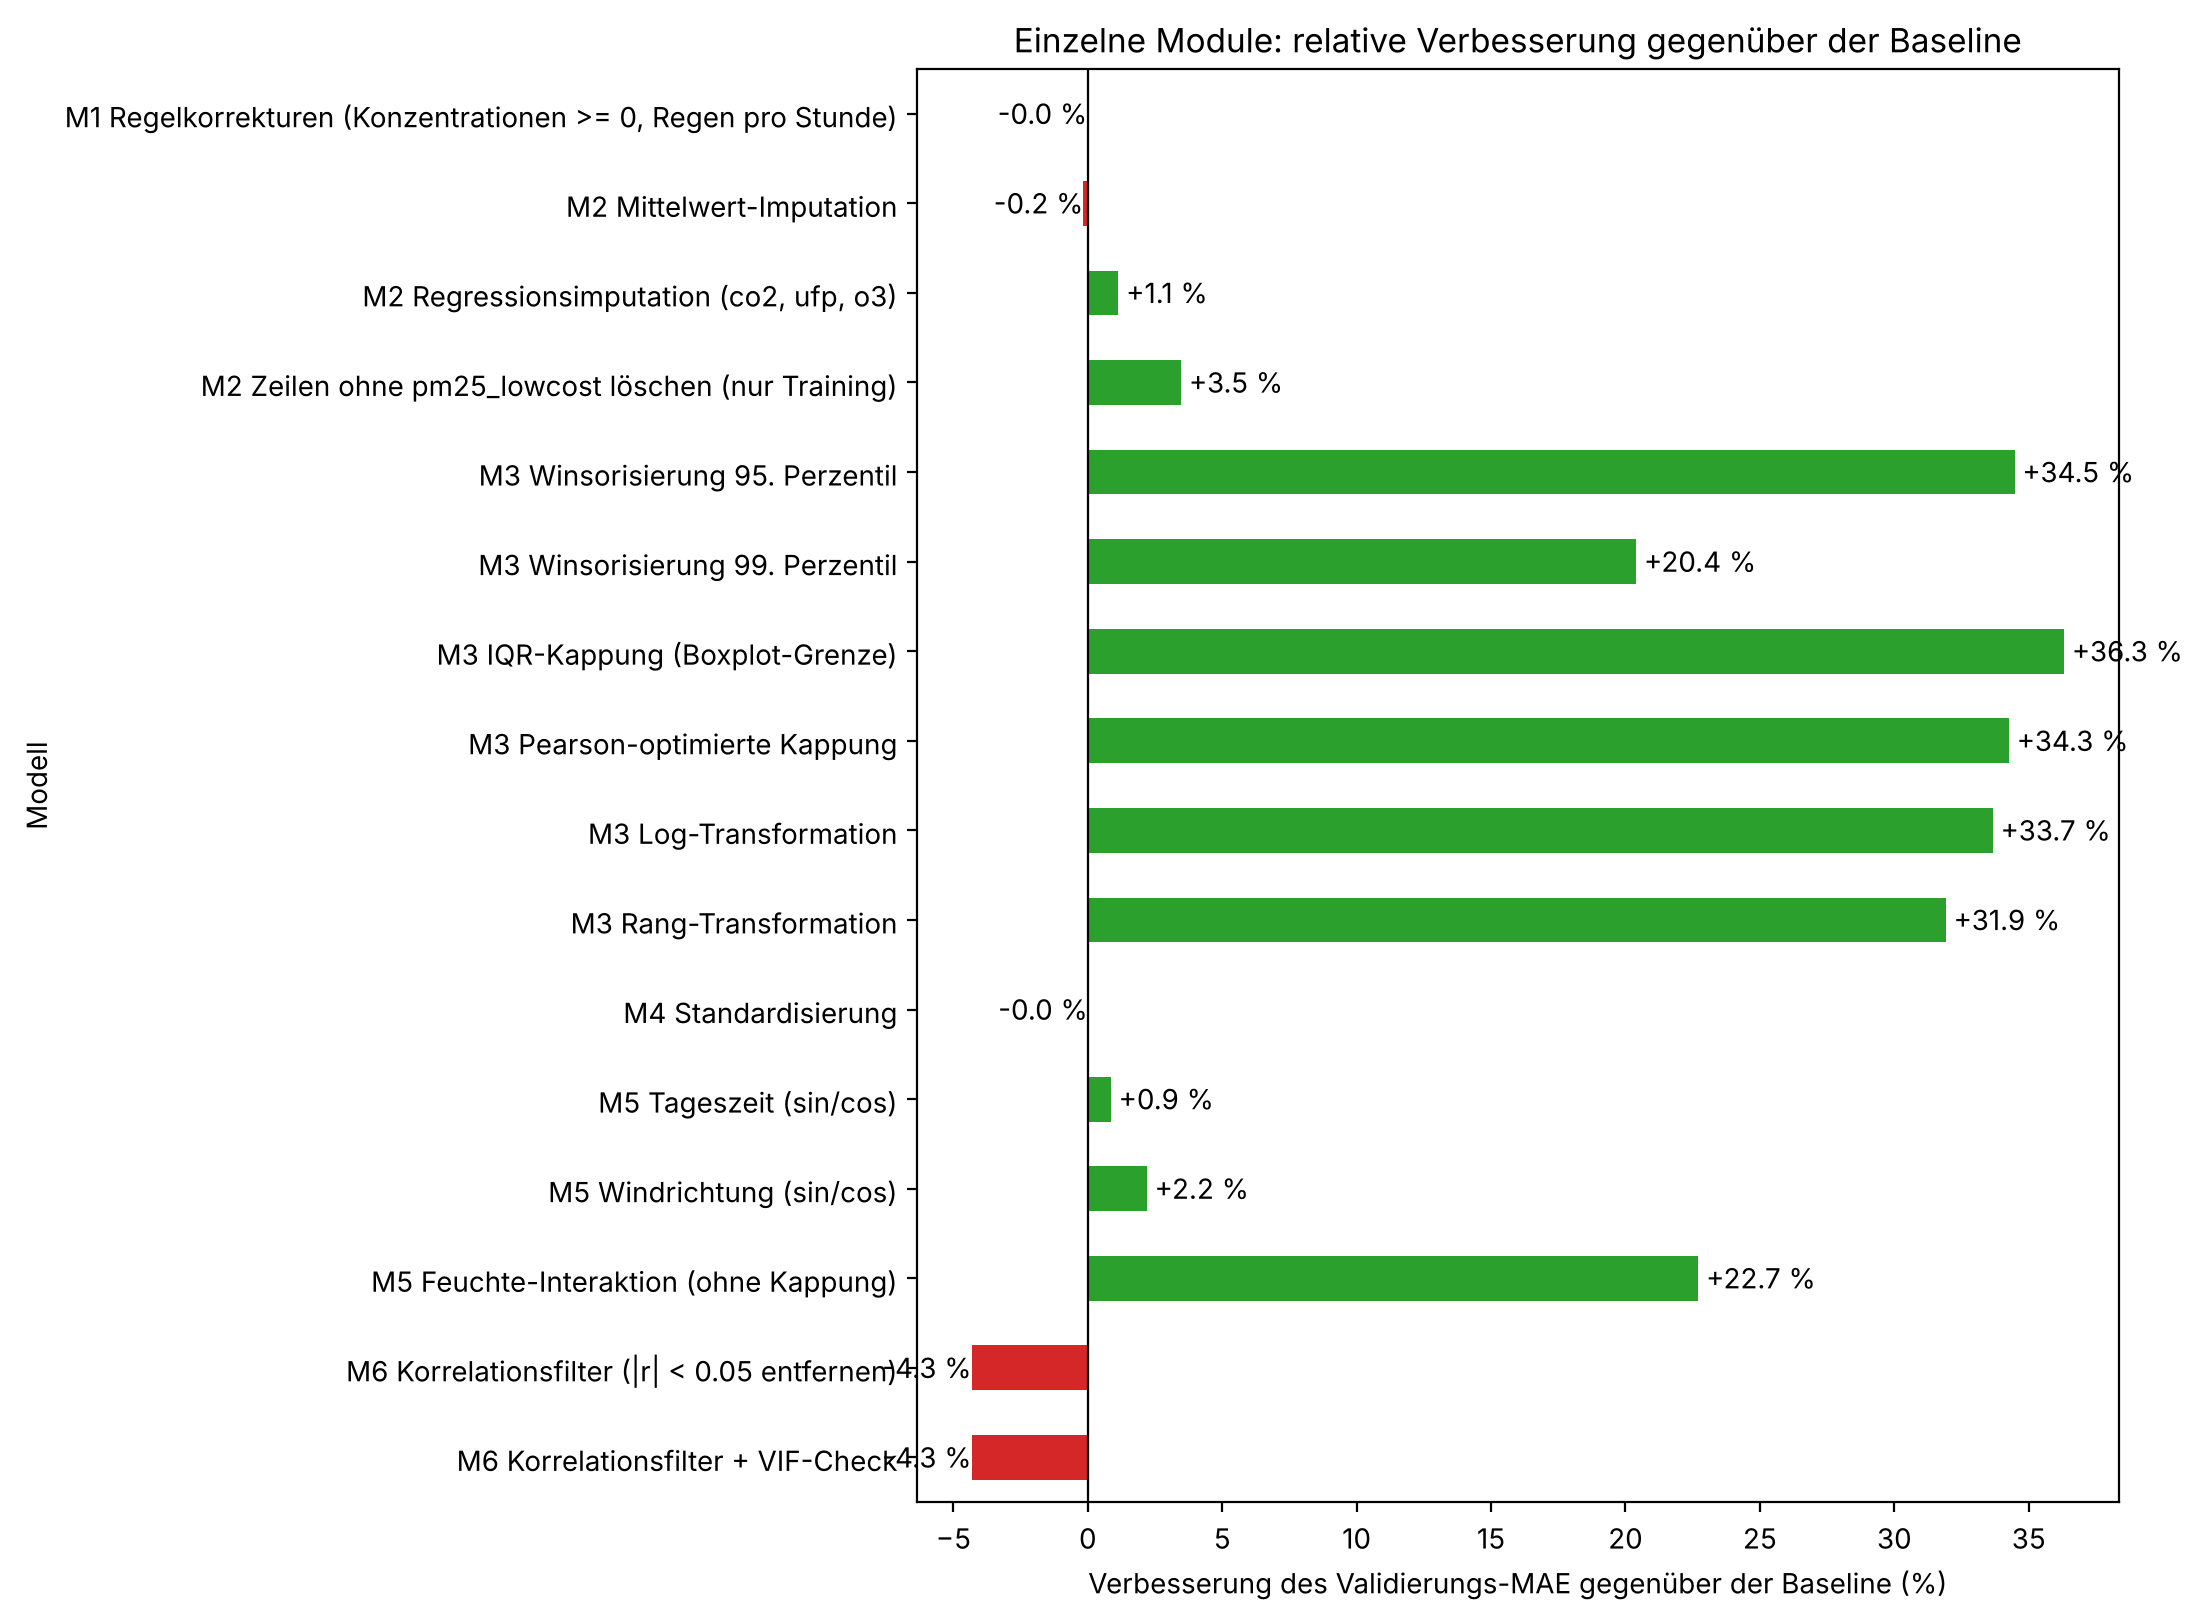

In [30]:
def plot_delta(log_df, rows, title):
    # Balkendiagramm: Verbesserung des Validierungs-MAE gegenüber der Baseline in %
    view = log_df.loc[rows].set_index("Modell")["Delta MAE (%)"]
    colors = ["tab:green" if value > 0 else "tab:red" for value in view]
    ax = view.plot.barh(figsize=(11, 0.45 * len(view) + 1), color=colors)
    ax.axvline(0, color="black", linewidth=0.8)
    for i, value in enumerate(view):
        ax.text(value, i, f" {value:+.1f} %", va="center", ha="left" if value >= 0 else "right")
    ax.set_title(title)
    ax.set_xlabel("Verbesserung des Validierungs-MAE gegenüber der Baseline (%)")
    ax.invert_yaxis()
    plt.tight_layout()
    plt.show()


plot_delta(log_df, log_df.index[1:], "Einzelne Module: relative Verbesserung gegenüber der Baseline")

**Interpretation der Einzel-Module:**

| Modul | Effekt auf Validierungs-MAE | Erklärung |
|---|---|---|
| **M3 Outlier Handling** | **−32 bis −36 %** (bester Wert: IQR-Kappung, MAE 0,85) | mit Abstand der größte Hebel; `pm25_lowcost` wird für das Modell erst nach der Kappung nutzbar |
| M3 Winsorisierung 99 % | −20 % | Grenze zu hoch, es bleiben zu viele Extremwerte |
| M5 Feuchte-Interaktion (ohne Kappung) | −23 % | hilft schon, obwohl die Extremwerte noch im Feature stecken |
| M2 Zeilen löschen (nur Training) | −3,5 % | ohne „erfundene" Werte im wichtigsten Feature wird die Steigung sauberer gelernt |
| M5 Windrichtung / Tageszeit | −2,2 % / −0,9 % | kleiner Zusatznutzen |
| M2 Regressionsimputation | −1,1 % | die Imputationsmodelle erklären nur 26–51 % der Varianz (R²); besser als ein fester Wert, aber kein großer Hebel |
| M1, M2 Mittelwert | ±0,2 % | fachlich sinnvolle Korrekturen, aber zu wenige betroffene Werte für einen messbaren Effekt |
| M4 Standardisierung | **exakt 0 %** | bestätigt unsere Erwartung: Die lineare Regression gleicht eine lineare Skalierung über die Koeffizienten aus |
| M6 Korrelationsfilter | +4,3 % (schlechter) | `no`, `o3` und `rain_vol` sind einzeln kaum mit dem Label korreliert, tragen im Zusammenspiel aber etwas bei |

**Learnings:**
- Die **Pearson-optimierte Kappung** (85. Perzentil für `pm25_lowcost`) ist im Modell *schlechter* als die IQR-Grenze. Die maximale Einzelkorrelation ist also nicht automatisch die beste Grenze; eine zu strenge Kappung verändert auch echte, höhere Messwerte. Der Pearson/Spearman-Vergleich war vor allem nützlich, um **die Features** für das Outlier Handling auszuwählen und **das 99. Perzentil auszuschließen**.
- Die **Rang-Transformation**, also genau der Raum, in dem Spearman rechnet, ist im Modell schwächer als die Kappung. Laut Vorlesung verzerrt sie Abstände, die die lineare Regression aber braucht.
- **Scaling** bringt bei der linearen Regression nichts (Feedback Vorjahr: „Analyse, warum Scaling nichts bringt"). Es wird erst für Task 3 relevant, z. B. bei regularisierten Modellen oder KNN.

### 6.1 Kontrollversuche: Halten unsere Festlegungen?

In den Modulen haben wir einige Werte selbst festgelegt. Hier prüfen wir sie im Modell, damit sie nicht nur behauptet sind. Die Kontrollversuche verwenden die beste Outlier-Variante aus Abschnitt 6 und werden **nicht** ins Log-File geschrieben. Sie sind keine Kandidaten für das finale Modell, sondern dienen nur der Begründung.

| Festlegung | Wo | Kontrollversuch |
|---|---|---|
| Lücke Pearson/Spearman > 0,15 wählt die Ausreißer-Features | M3 | Schwellen 0,10 (zusätzlich `no2`) und 0,25 (nur `pm25_lowcost`, `black_carbon`) |
| Kappung nur nach oben | M3 | beidseitige Winsorisierung wie in der Vorlesung (verglichen mit Winsor 95 %, weil die Vorlesung die Winsorisierung über Perzentile definiert) |
| Korrelationsfilter mit \|r\| < 0,05 | M6 | Schwellen 0,10 und 0,15 |

In [31]:
def validation_mae(config):
    # Pipeline ausführen und nur den Validierungs-MAE zurückgeben (ohne Log-Eintrag)
    data = run_pipeline(config)
    feats = data["features"]
    _, metrics = evaluate_model(data["train"][feats], data["train"][TARGET], data["val"][feats], data["val"][TARGET])
    return metrics["MAE_val"], len(feats)


best_single_m3 = log_df[log_df["Modul"] == "M3"].sort_values("MAE_val").iloc[0]
m3_method = [cfg["M3_outliers"] for name, _, _, cfg in single_experiments if name == best_single_m3["Modell"]][0]
print("Kontrollversuche mit M3 =", m3_method)

control = []

# 1) Schwelle für die Pearson/Spearman-Lücke
original_outlier_features = OUTLIER_FEATURES
for threshold in [0.10, 0.15, 0.25]:
    OUTLIER_FEATURES = corr_compare[corr_compare["Lücke (|Spearman| - |Pearson|)"] > threshold].index.tolist()
    mae, _ = validation_mae({"M3_outliers": m3_method})
    control.append({"Festlegung": "Lücken-Schwelle", "Variante": f"> {threshold:.2f}: " + ", ".join(OUTLIER_FEATURES),
                    "MAE_val": mae, "gewählt": threshold == GAP_THRESHOLD})
OUTLIER_FEATURES = original_outlier_features   # Originalzustand wiederherstellen

# 2) Nur nach oben vs. beidseitig (Vorlesung)
for method, label in [("winsor95", "nur oben (95. Perzentil)"), ("winsor95_both", "beidseitig (5. und 95. Perzentil)")]:
    mae, _ = validation_mae({"M3_outliers": method})
    control.append({"Festlegung": "Kappungsrichtung", "Variante": label, "MAE_val": mae, "gewählt": method == "winsor95"})

# 3) Schwelle des Korrelationsfilters (auf der besten Outlier-Variante)
for threshold in [0.05, 0.10, 0.15]:
    CORR_THRESHOLD = threshold
    mae, n = validation_mae({"M3_outliers": m3_method, "M6_selection": "corr"})
    control.append({"Festlegung": "Korrelationsfilter", "Variante": f"|r| < {threshold:.2f} entfernen ({n} Features)",
                    "MAE_val": mae, "gewählt": threshold == 0.05})
CORR_THRESHOLD = 0.05   # Originalzustand wiederherstellen
mae, n = validation_mae({"M3_outliers": m3_method})
control.append({"Festlegung": "Korrelationsfilter", "Variante": f"kein Filter ({n} Features)", "MAE_val": mae, "gewählt": False})

display(pd.DataFrame(control).round(4))

Kontrollversuche mit M3 = iqr


,Festlegung,Variante,MAE_val,gewählt
0,Lücken-Schwelle,"> 0.10: pm25_lowcost, black_carbon, no, no2",0.8558,False
1,Lücken-Schwelle,"> 0.15: pm25_lowcost, black_carbon, no",0.8545,True
2,Lücken-Schwelle,"> 0.25: pm25_lowcost, black_carbon",0.8741,False
3,Kappungsrichtung,nur oben (95. Perzentil),0.8792,True
4,Kappungsrichtung,beidseitig (5. und 95. Perzentil),0.8841,False
5,Korrelationsfilter,|r| < 0.05 entfernen (12 Features),0.8699,True
6,Korrelationsfilter,|r| < 0.10 entfernen (11 Features),0.8794,False
7,Korrelationsfilter,|r| < 0.15 entfernen (9 Features),1.0243,False
8,Korrelationsfilter,kein Filter (14 Features),0.8545,False


**Interpretation der Kontrollversuche:**

| Festlegung | Ergebnis | Bewertung |
|---|---|---|
| Lücken-Schwelle 0,15 | MAE 0,855; 0,10 (zusätzlich `no2`) 0,856; 0,25 (ohne `no`) 0,874 | Die Schwelle 0,15 ist die beste der drei. `no2` mitzukappen bringt nichts, `no` wegzulassen schadet. |
| Kappung nur nach oben | 0,879 gegenüber 0,884 beidseitig | Die beidseitige Variante aus der Vorlesung ist minimal schlechter. Das passt zu unserer Begründung, dass niedrige Werte keine Fehler sind. |
| Korrelationsfilter 0,05 | 0,870; 0,10: 0,879; 0,15: 1,024; ohne Filter: 0,855 | 0,05 ist der beste Filter. **Ohne Filter** ist das Modell aber noch besser. Das belegt die Entscheidung, M6 im finalen Modell nicht zu verwenden. |

Damit sind die drei Werte, die wir selbst festgelegt haben, nicht nur behauptet, sondern im Modell überprüft. Alle Unterschiede sind klein bis mittel. Sie würden die Gesamtaussage (M3 ist der größte Hebel) in keinem Fall ändern.

## 7. Experimente: Kombinationen der Module

Im Vorjahr wurde angemerkt, dass auch **Kombinationen** der Maßnahmen untersucht werden sollten (z. B. Missing Values + Outlier). Einzelne Module können sich gegenseitig verstärken oder aufheben.

Für die Kombinationen verwenden wir **je Modul die beste Variante aus Abschnitt 6** (nach Validierungs-MAE). Die Auswahl erfolgt automatisch aus dem Log, damit sie nachvollziehbar und nicht „von Hand" gesetzt ist.

In [32]:
def best_variant(candidates, mapping):
    # Beste Variante nach Validierungs-MAE; mapping übersetzt den Modellnamen in die Einstellung des Moduls
    best_name = candidates.loc[candidates["MAE_val"].idxmin(), "Modell"]
    return best_name, mapping[best_name]


# Zuordnung Modellname -> Einstellung des Moduls
m2_mapping = {name: cfg["M2_missing"] for name, module, _, cfg in single_experiments if module == "M2"}
m2_mapping[log_df.loc[0, "Modell"]] = "median"     # die Baseline ist die Median-Variante von M2
m3_mapping = {name: cfg["M3_outliers"] for name, module, _, cfg in single_experiments if module == "M3"}

best_m2_name, BEST_M2 = best_variant(log_df[log_df["Modul"].isin(["Baseline", "M2"])], m2_mapping)
best_m3_name, BEST_M3 = best_variant(log_df[log_df["Modul"] == "M3"], m3_mapping)
print("Beste M2-Variante:", best_m2_name, "->", BEST_M2)
print("Beste M3-Variante:", best_m3_name, "->", BEST_M3)

Beste M2-Variante: M2 Zeilen ohne pm25_lowcost löschen (nur Training) -> drop_rows
Beste M3-Variante: M3 IQR-Kappung (Boxplot-Grenze) -> iqr


In [33]:
combo_start = len(results)

m2_text = "M2 " + BEST_M2
m3_text = "M3 " + BEST_M3
combo_experiments = [
    ("Kombi M1 + M2", "Kombi", "Regelkorrekturen + " + m2_text,
     {"M1_rules": True, "M2_missing": BEST_M2}),
    ("Kombi M2 + M3 (Missing Values + Outlier)", "Kombi", m2_text + " + " + m3_text,
     {"M2_missing": BEST_M2, "M3_outliers": BEST_M3}),
    ("Kombi M1 + M3", "Kombi", "Regelkorrekturen + " + m3_text,
     {"M1_rules": True, "M3_outliers": BEST_M3}),
    ("Kombi M1 + M2 + M3", "Kombi", "Regelkorrekturen + " + m2_text + " + " + m3_text,
     {"M1_rules": True, "M2_missing": BEST_M2, "M3_outliers": BEST_M3}),
    ("Kombi M1-M3 + Tageszeit + Wind", "Kombi", "M1-M3 + hour/wind als sin/cos",
     {"M1_rules": True, "M2_missing": BEST_M2, "M3_outliers": BEST_M3, "M5_features": ["hour", "wind"]}),
    ("Kombi M1-M3 + Feuchte-Interaktion", "Kombi", "M1-M3 + lowcost x humidity (aus gekappten Werten)",
     {"M1_rules": True, "M2_missing": BEST_M2, "M3_outliers": BEST_M3, "M5_features": ["humidity"]}),
    ("Kombi M1-M3 + alle M5-Features", "Kombi", "M1-M3 + hour, wind, humidity",
     {"M1_rules": True, "M2_missing": BEST_M2, "M3_outliers": BEST_M3, "M5_features": ["hour", "wind", "humidity"]}),
    ("Kombi M1-M3 + M5 + Korrelationsfilter", "Kombi", "M1-M3 + alle M5-Features + M6 corr",
     {"M1_rules": True, "M2_missing": BEST_M2, "M3_outliers": BEST_M3, "M5_features": ["hour", "wind", "humidity"],
      "M6_selection": "corr"}),
    ("Kombi M1-M3 + M5 + Korrelationsfilter + VIF", "Kombi", "M1-M3 + alle M5-Features + M6 corr_vif",
     {"M1_rules": True, "M2_missing": BEST_M2, "M3_outliers": BEST_M3, "M5_features": ["hour", "wind", "humidity"],
      "M6_selection": "corr_vif"}),
    ("Kombi Alle Module (M1-M6 inkl. Scaling)", "Kombi", "M1-M3 + M5 + M6 corr + Standardisierung",
     {"M1_rules": True, "M2_missing": BEST_M2, "M3_outliers": BEST_M3, "M5_features": ["hour", "wind", "humidity"],
      "M6_selection": "corr", "M4_scaling": "standard"}),
]

for name, module, description, config in combo_experiments:
    log_df, experiment_data[name] = run_experiment(name, module, description, config)

show_results(log_df, log_df.index[combo_start:])
print("M6 in der Kombination:", experiment_data["Kombi M1-M3 + M5 + Korrelationsfilter + VIF"]["info"]["M6"])

,Modell,Anzahl Features,MAE_train,MAE_val,R2_val,Delta MAE (abs),Delta MAE (%),Overfitting-Lücke (MAE_val - MAE_train)
17,Kombi M1 + M2,14,1.3409,1.2951,0.4196,0.0466,3.4707,-0.0458
18,Kombi M2 + M3 (Missing Values + Outlier),14,0.8522,0.8742,0.7068,0.4675,34.8404,0.0220
19,Kombi M1 + M3,14,0.8240,0.8496,0.7160,0.4921,36.6756,0.0256
20,Kombi M1 + M2 + M3,14,0.8441,0.8689,0.7065,0.4728,35.2368,0.0248
21,Kombi M1-M3 + Tageszeit + Wind,17,0.8355,0.8718,0.7182,0.4699,35.0227,0.0363
22,Kombi M1-M3 + Feuchte-Interaktion,15,0.7212,0.7701,0.7892,0.5716,42.6056,0.0489
23,Kombi M1-M3 + alle M5-Features,18,0.7135,0.7711,0.7913,0.5706,42.5285,0.0576
24,Kombi M1-M3 + M5 + Korrelationsfilter,16,0.7252,0.7887,0.7861,0.5530,41.2158,0.0635
25,Kombi M1-M3 + M5 + Korrelationsfilter + VIF,15,0.8494,0.8892,0.7124,0.4525,33.7228,0.0398
26,Kombi Alle Module (M1-M6 inkl. Scaling),16,0.7252,0.7887,0.7861,0.5530,41.2158,0.0635


M6 in der Kombination: {'Methode': 'corr_vif', 'entfernt (Korrelation)': ['o3', 'rain_hourly'], 'entfernt (VIF)': ['lowcost_x_humidity']}


### 7.1 Kombinationsmatrix: Gilt die beste Einzelvariante auch in der Kombination?

Bisher haben wir für jedes Modul die Variante genommen, die **allein** am besten war. Das muss in Kombination nicht stimmen: Eine Maßnahme kann ein Problem lösen, das ein anderes Modul ohnehin schon löst. Deshalb testen wir systematisch eine kleine Matrix aus

- **M2:** Median (Baseline) und beste Einzelvariante
- **M3:** die drei besten Outlier-Methoden aus Abschnitt 6
- **M5:** Tageszeit + Wind bzw. alle drei M5-Features

M1 ist immer aktiv. Kombinationen, die schon in Abschnitt 7 enthalten sind, werden übersprungen.

In [34]:
matrix_start = len(results)
m3_ranking = log_df[log_df["Modul"] == "M3"].sort_values("MAE_val")
top_m3 = [m3_mapping[name] for name in m3_ranking["Modell"]][:3]
m2_options = ["median", BEST_M2] if BEST_M2 != "median" else ["median"]
fe_options = {"Tageszeit + Wind": ["hour", "wind"], "alle M5-Features": ["hour", "wind", "humidity"]}

matrix_configs = {}
for m2 in m2_options:
    for m3 in top_m3:
        for fe_name, fe_list in fe_options.items():
            if m2 == BEST_M2 and m3 == BEST_M3:
                continue   # bereits in Abschnitt 7 enthalten
            name = "Matrix M1 + M2 " + m2 + " + M3 " + m3 + " + " + fe_name
            config = {"M1_rules": True, "M2_missing": m2, "M3_outliers": m3, "M5_features": fe_list}
            matrix_configs[name] = config
            log_df, experiment_data[name] = run_experiment(name, "Matrix", "M2 = " + m2 + ", M3 = " + m3 + ", M5 = " + fe_name, config)

show_results(log_df, log_df.index[matrix_start:])

,Modell,Anzahl Features,MAE_train,MAE_val,R2_val,Delta MAE (abs),Delta MAE (%),Overfitting-Lücke (MAE_val - MAE_train)
27,Matrix M1 + M2 median + M3 iqr + Tageszeit + Wind,17,0.8182,0.8464,0.7292,0.4953,36.9172,0.0282
28,Matrix M1 + M2 median + M3 iqr + alle M5-Features,18,0.7476,0.7737,0.7912,0.5680,42.3310,0.0262
29,Matrix M1 + M2 median + M3 winsor95 + Tageszei...,17,0.8407,0.8742,0.6951,0.4675,34.8474,0.0335
30,Matrix M1 + M2 median + M3 winsor95 + alle M5-...,18,0.7455,0.7823,0.7808,0.5594,41.6900,0.0369
31,Matrix M1 + M2 median + M3 pearson_opt + Tages...,17,0.8275,0.8787,0.6986,0.4630,34.5105,0.0512
32,Matrix M1 + M2 median + M3 pearson_opt + alle ...,18,0.8000,0.8439,0.7324,0.4978,37.1034,0.0439
33,Matrix M1 + M2 drop_rows + M3 winsor95 + Tages...,17,0.8530,0.8966,0.6872,0.4451,33.1758,0.0436
34,Matrix M1 + M2 drop_rows + M3 winsor95 + alle ...,18,0.7111,0.7814,0.7792,0.5603,41.7578,0.0703
35,Matrix M1 + M2 drop_rows + M3 pearson_opt + Ta...,17,0.8223,0.8846,0.6999,0.4571,34.0689,0.0623
36,Matrix M1 + M2 drop_rows + M3 pearson_opt + al...,18,0.7640,0.8311,0.7415,0.5106,38.0545,0.0671


**Interpretation der Kombinationen:**

- **Missing Values + Outlier (M2 + M3):** Die Zeilenlöschung, als Einzelmodul die beste M2-Variante, bringt **in Kombination mit M3 keinen Vorteil mehr**. „M1 + M3" (Median, MAE 0,850) ist sogar besser als „M1 + M2 + M3" (Zeilenlöschung, 0,869). Eine mögliche Erklärung: Die Zeilenlöschung half allein vor allem, weil das Modell weniger durch die verzerrte Steigung gestört wurde, und dieses Problem löst M3 bereits. **Die beste Einzelvariante ist also nicht automatisch die beste Variante in der Kombination.** Deshalb haben wir die Kombinationsmatrix ergänzt.
- **Feuchte-Interaktion:** Auf den gekappten Werten bringt sie den nächsten großen Schritt (von ca. 0,85–0,87 auf **0,77**). Tageszeit und Wind bringen in Kombination praktisch nichts mehr dazu (0,770 → 0,771).
- **Feature Selection (M6) in der Kombination:** Der Korrelationsfilter verschlechtert leicht (0,771 → 0,789). Der VIF-Check entfernt `lowcost_x_humidity`, weil es stark mit `pm25_lowcost` zusammenhängt, und verschlechtert deutlich (→ 0,889). **Learning:** Ein hoher VIF bedeutet „ähnlich", nicht „überflüssig".
- **Scaling** verändert auch in der Gesamtkombination nichts.
- **Matrix:** Die fünf besten Modelle liegen bei **MAE 0,770–0,782**, also innerhalb von etwa 0,01 µg/m³. Gemeinsam ist ihnen **M1 + Kappung der drei Ausreißer-Features + Feuchte-Interaktion**. Ob Median oder Zeilenlöschung und ob 95. Perzentil oder IQR-Grenze, spielt dagegen kaum eine Rolle. Unterschiede dieser Größe sollte man auf einer einzigen Validierung nicht überbewerten.

## 8. Gesamtvergleich, Overfitting-Check und Auswahl des finalen Modells

### 8.1 Alle Ergebnisse im Überblick

Das vollständige Log (inkl. Beschreibung jedes Datensatzes) liegt zusätzlich in `Output/evaluation_log.csv`.

In [35]:
overview = log_df.sort_values("MAE_val").reset_index(drop=True)
overview.index = overview.index + 1   # Rangplatz
display(overview[["Modell", "Modul", "Anzahl Features", "MAE_val", "R2_val", "Delta MAE (abs)", "Delta MAE (%)",
                  "Delta R2 (abs)"]].round(4))

,Modell,Modul,Anzahl Features,MAE_val,R2_val,Delta MAE (abs),Delta MAE (%),Delta R2 (abs)
1,Kombi M1-M3 + Feuchte-Interaktion,Kombi,15,0.7701,0.7892,0.5716,42.6056,0.4301
2,Kombi M1-M3 + alle M5-Features,Kombi,18,0.7711,0.7913,0.5706,42.5285,0.4322
3,Matrix M1 + M2 median + M3 iqr + alle M5-Features,Matrix,18,0.7737,0.7912,0.5680,42.3310,0.4321
4,Matrix M1 + M2 drop_rows + M3 winsor95 + alle ...,Matrix,18,0.7814,0.7792,0.5603,41.7578,0.4201
5,Matrix M1 + M2 median + M3 winsor95 + alle M5-...,Matrix,18,0.7823,0.7808,0.5594,41.6900,0.4218
6,Kombi Alle Module (M1-M6 inkl. Scaling),Kombi,16,0.7887,0.7861,0.5530,41.2158,0.4271
7,Kombi M1-M3 + M5 + Korrelationsfilter,Kombi,16,0.7887,0.7861,0.5530,41.2158,0.4271
8,Matrix M1 + M2 drop_rows + M3 pearson_opt + al...,Matrix,18,0.8311,0.7415,0.5106,38.0545,0.3825
9,Matrix M1 + M2 median + M3 pearson_opt + alle ...,Matrix,18,0.8439,0.7324,0.4978,37.1034,0.3734
10,Matrix M1 + M2 median + M3 iqr + Tageszeit + Wind,Matrix,17,0.8464,0.7292,0.4953,36.9172,0.3702


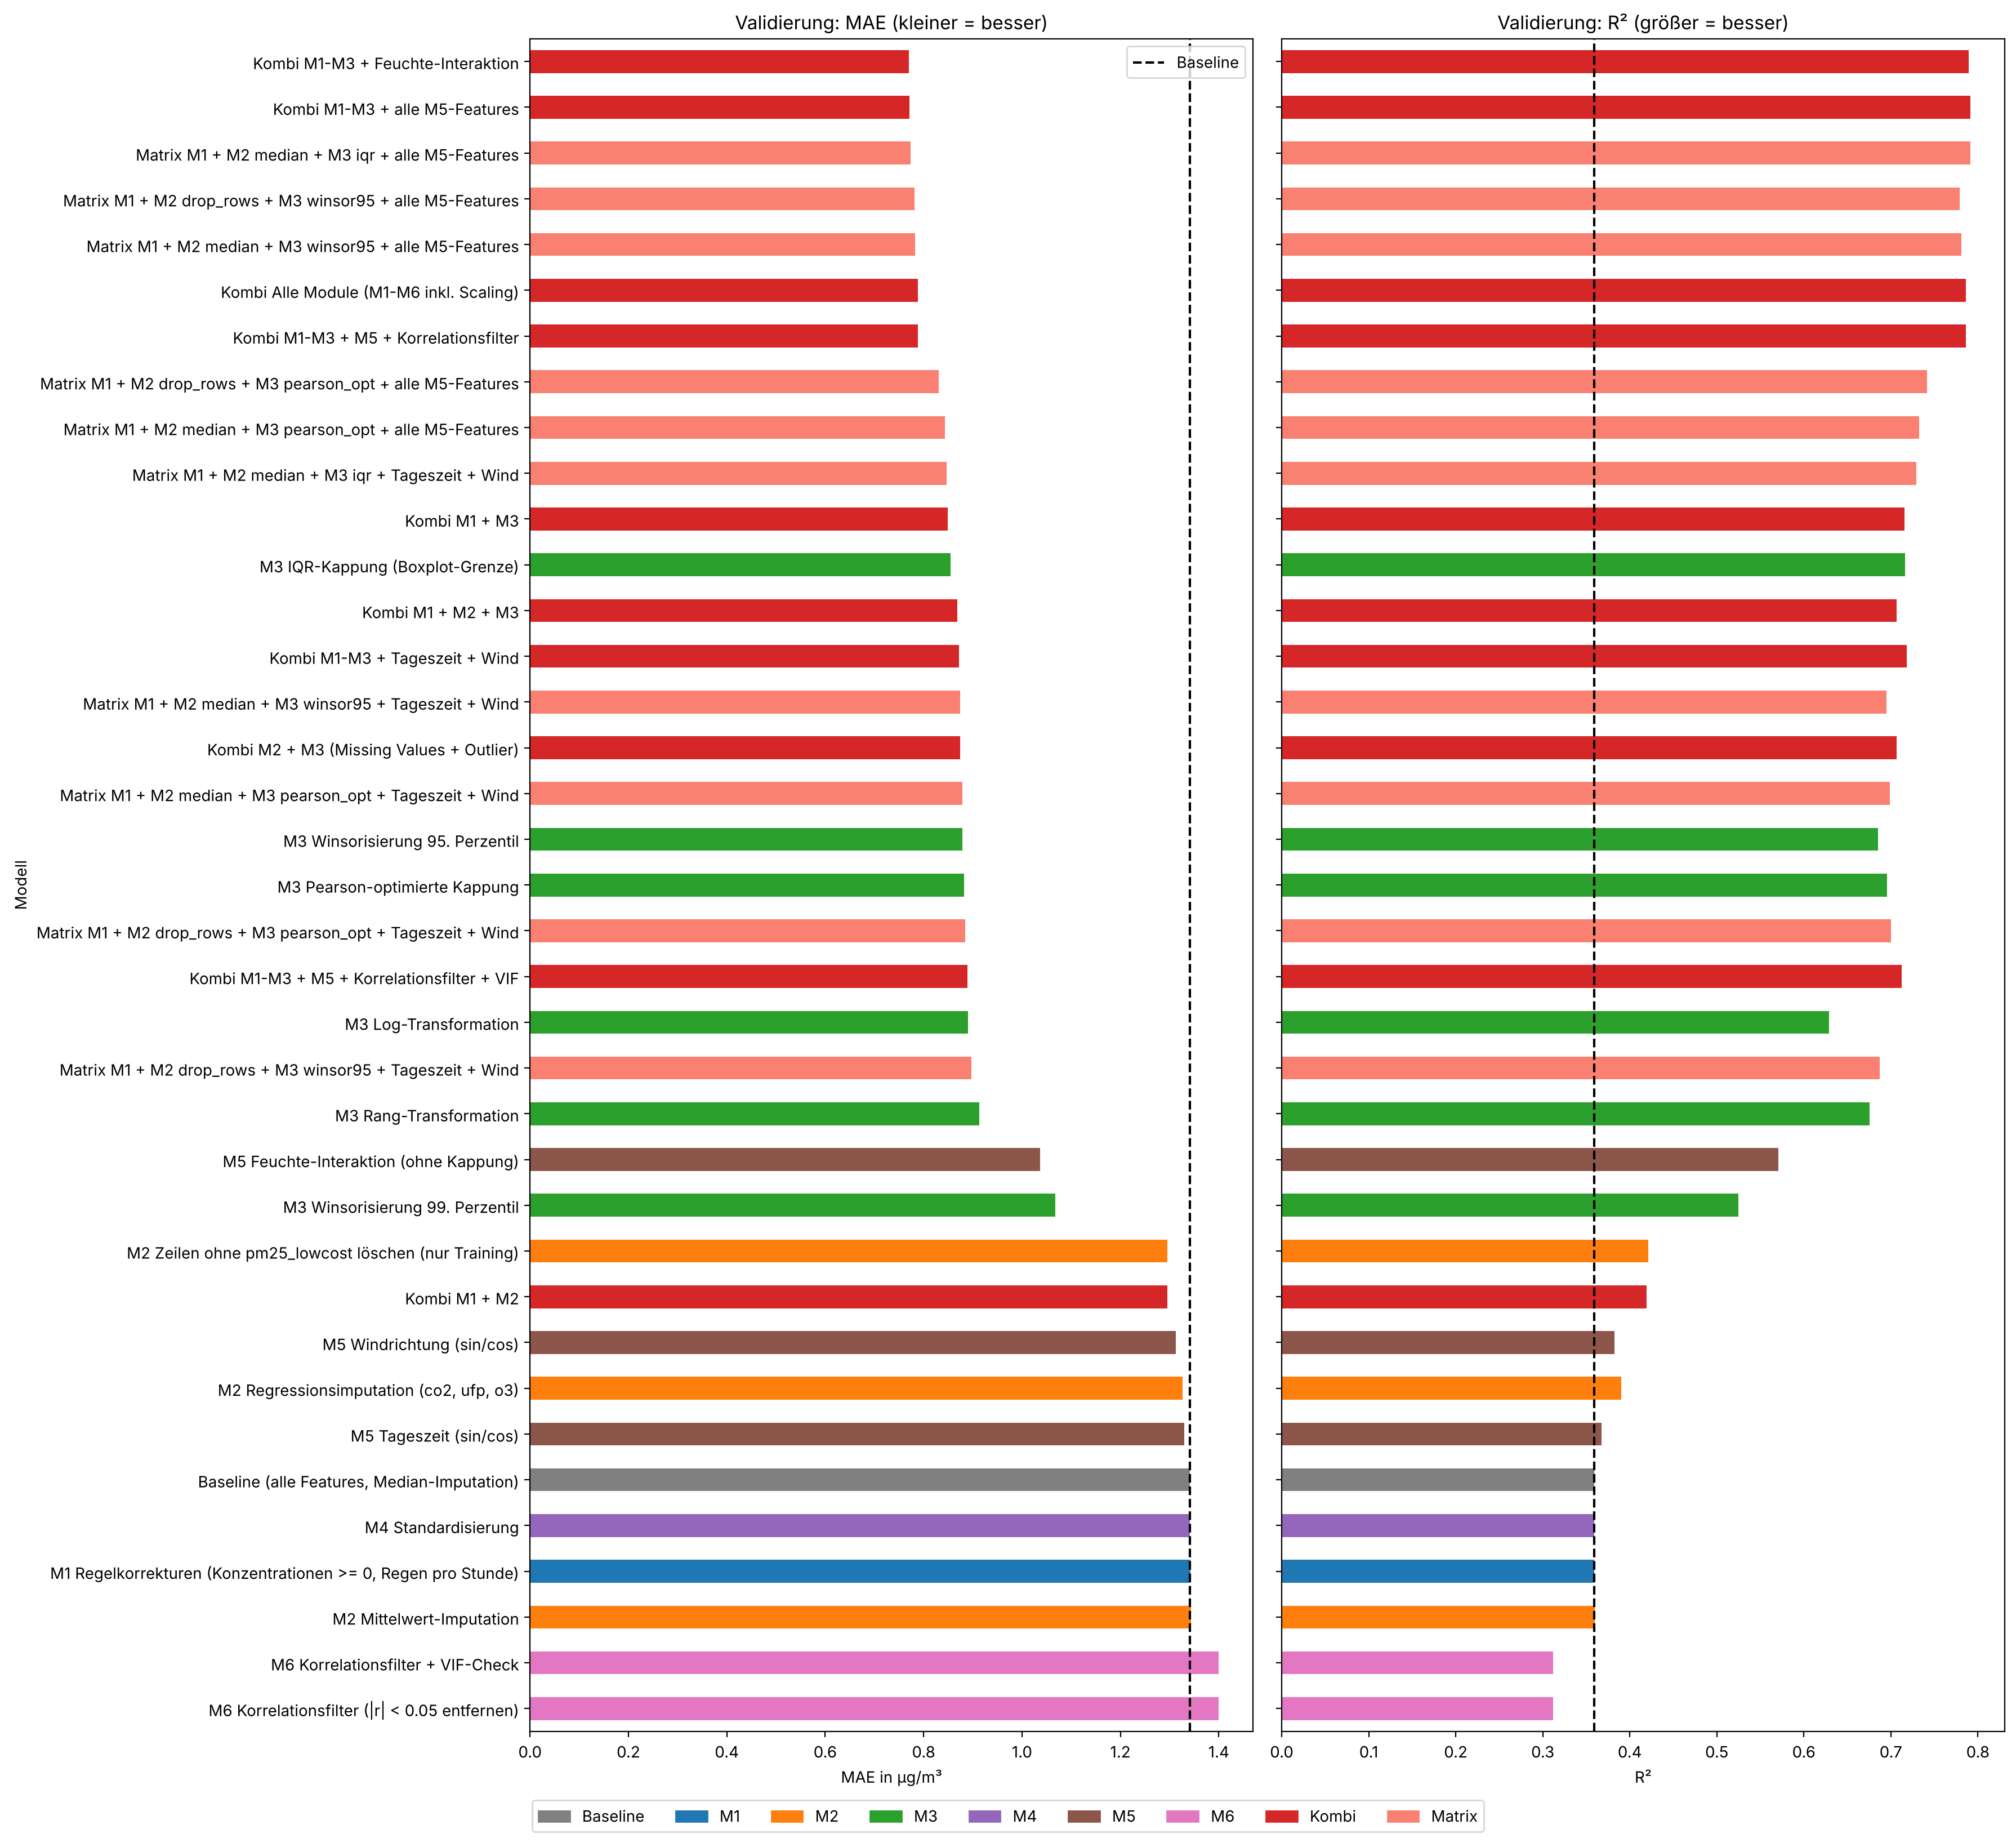

In [36]:
# Grafische Gegenüberstellung aller Modelle: absoluter MAE und R² auf der Validierung
plot_df = log_df.sort_values("MAE_val", ascending=False).set_index("Modell")
module_colors = {"Baseline": "grey", "M1": "tab:blue", "M2": "tab:orange", "M3": "tab:green", "M4": "tab:purple",
                 "M5": "tab:brown", "M6": "tab:pink", "Kombi": "tab:red", "Matrix": "salmon"}
colors = [module_colors[m] for m in plot_df["Modul"]]

fig, axes = plt.subplots(1, 2, figsize=(18, 0.38 * len(plot_df) + 2), sharey=True)
plot_df["MAE_val"].plot.barh(ax=axes[0], color=colors)
baseline_line = axes[0].axvline(baseline_metrics["MAE_val"], color="black", linestyle="--", label="Baseline")
axes[0].set_title("Validierung: MAE (kleiner = besser)")
axes[0].set_xlabel("MAE in µg/m³")
axes[0].legend(handles=[baseline_line])

plot_df["R2_val"].plot.barh(ax=axes[1], color=colors)
axes[1].axvline(baseline_metrics["R2_val"], color="black", linestyle="--")
axes[1].set_title("Validierung: R² (größer = besser)")
axes[1].set_xlabel("R²")

handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in module_colors.values()]
fig.legend(handles, module_colors.keys(), loc="lower center", ncol=len(module_colors), bbox_to_anchor=(0.5, -0.02))
plt.tight_layout()
plt.show()

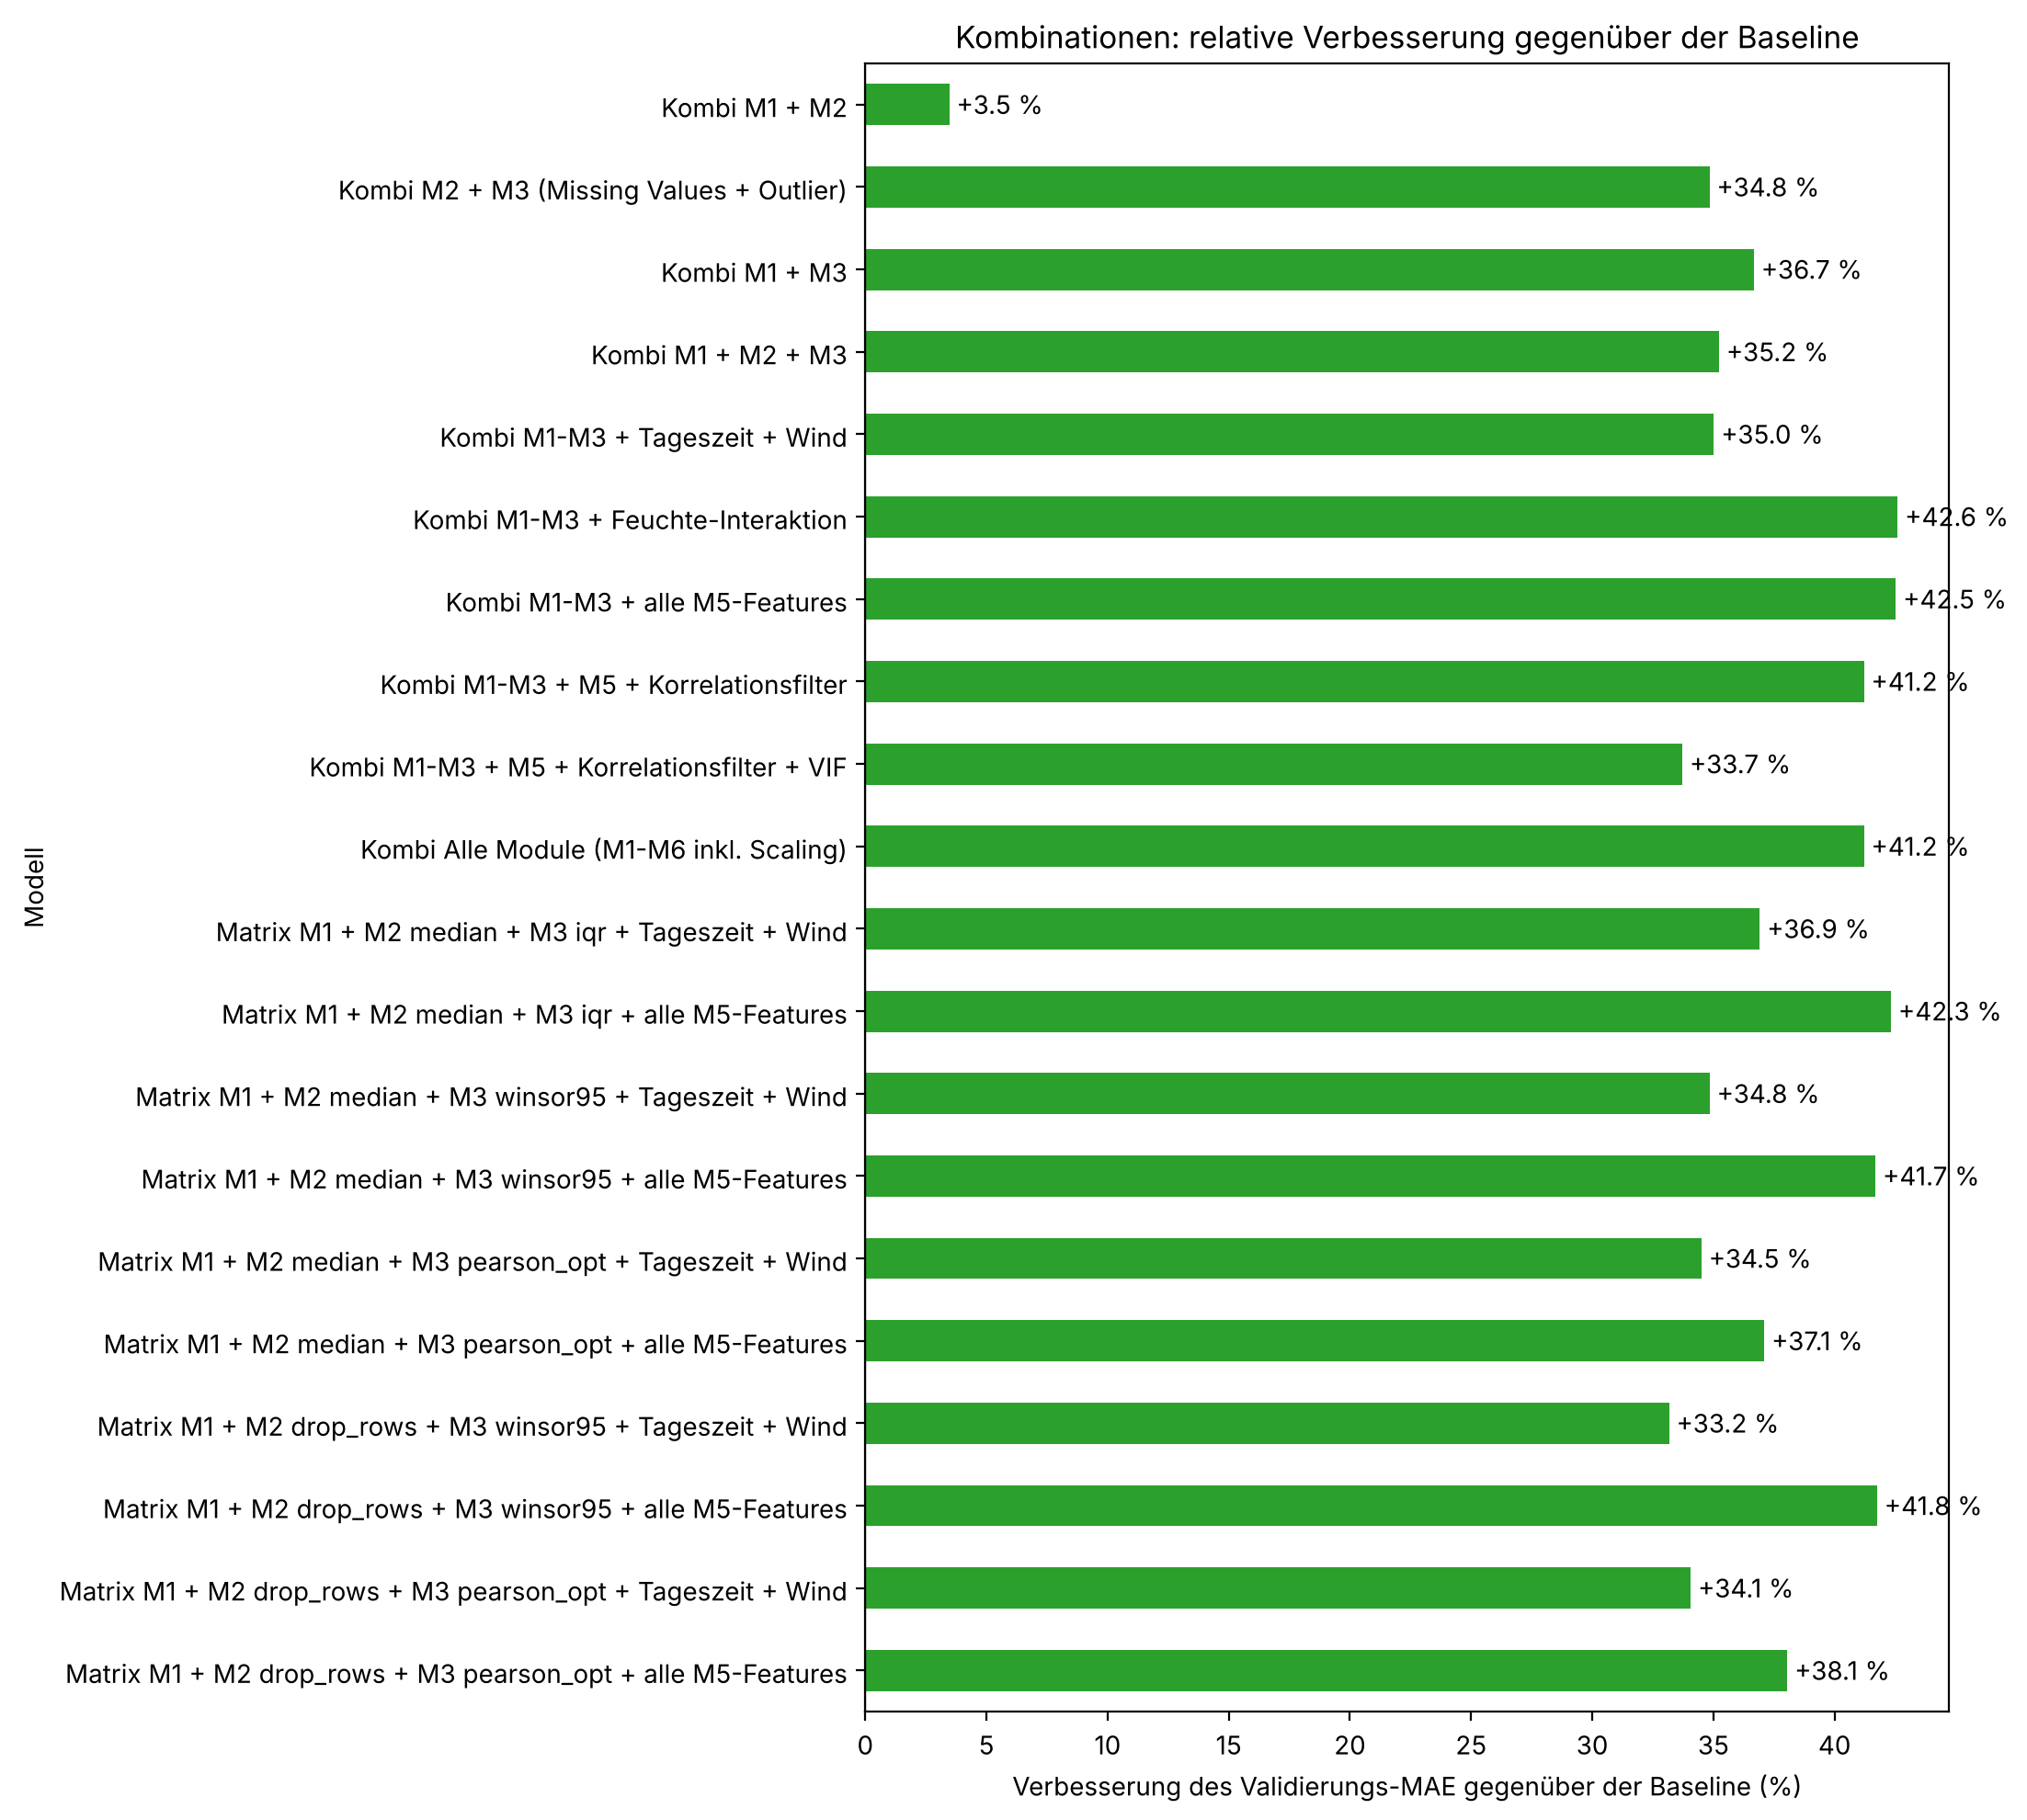

In [37]:
plot_delta(log_df, log_df.index[combo_start:], "Kombinationen: relative Verbesserung gegenüber der Baseline")

### 8.2 Auswahl des finalen Modells

**Auswahlregel (vor dem Blick auf den Test festgelegt):** Das Modell mit dem **kleinsten Validierungs-MAE** wird zum finalen Modell. Über die Kombinationsmatrix ist sichergestellt, dass wir nicht nur die naheliegende Kombination der Einzelsieger betrachten.

**Warum diese Regel?** Die Aufgabenstellung bewertet über MAE und R² auf der Validierung. Eine feste, vorher festgelegte Regel verhindert, dass wir nach Gefühl auswählen. Eine Alternative wäre gewesen, bei sehr kleinen Unterschieden das einfachere Modell zu nehmen. Das hätte aber eine zusätzliche Schwelle erfordert („sehr klein" = ?), die wir nicht begründen könnten. Wie nah die besten Modelle beieinander liegen, zeigen und diskutieren wir trotzdem.

In [38]:
final_name = log_df.loc[log_df["MAE_val"].idxmin(), "Modell"]
final_row = log_df.loc[log_df["MAE_val"].idxmin()]
all_configs = {name: cfg for name, _, _, cfg in single_experiments + combo_experiments}
all_configs.update(matrix_configs)
FINAL_CONFIG = {**BASE_CONFIG, **all_configs[final_name]}

print("Finales Modell:", final_name)
print("Konfiguration:", FINAL_CONFIG)
print("Validierung MAE:", round(final_row["MAE_val"], 4), "| R²:", round(final_row["R2_val"], 4))
print("Verbesserung ggü. Baseline:", round(final_row["Delta MAE (abs)"], 4), "µg/m³ bzw.",
      round(final_row["Delta MAE (%)"], 2), "%")

Finales Modell: Kombi M1-M3 + Feuchte-Interaktion
Konfiguration: {'M1_rules': True, 'M2_missing': 'drop_rows', 'M3_outliers': 'iqr', 'M4_scaling': None, 'M5_features': ['humidity'], 'M6_selection': None}
Validierung MAE: 0.7701 | R²: 0.7892
Verbesserung ggü. Baseline: 0.5716 µg/m³ bzw. 42.61 %


### 8.3 Overfitting-Check: Training vs. Validierung

Overfitting erkennt man daran, dass ein Modell auf den Trainingsdaten deutlich besser ist als auf unbekannten Daten. Wir vergleichen daher MAE und R² auf Training und Validierung für die Baseline, die Kombinationen aus Abschnitt 7 und das finale Modell.

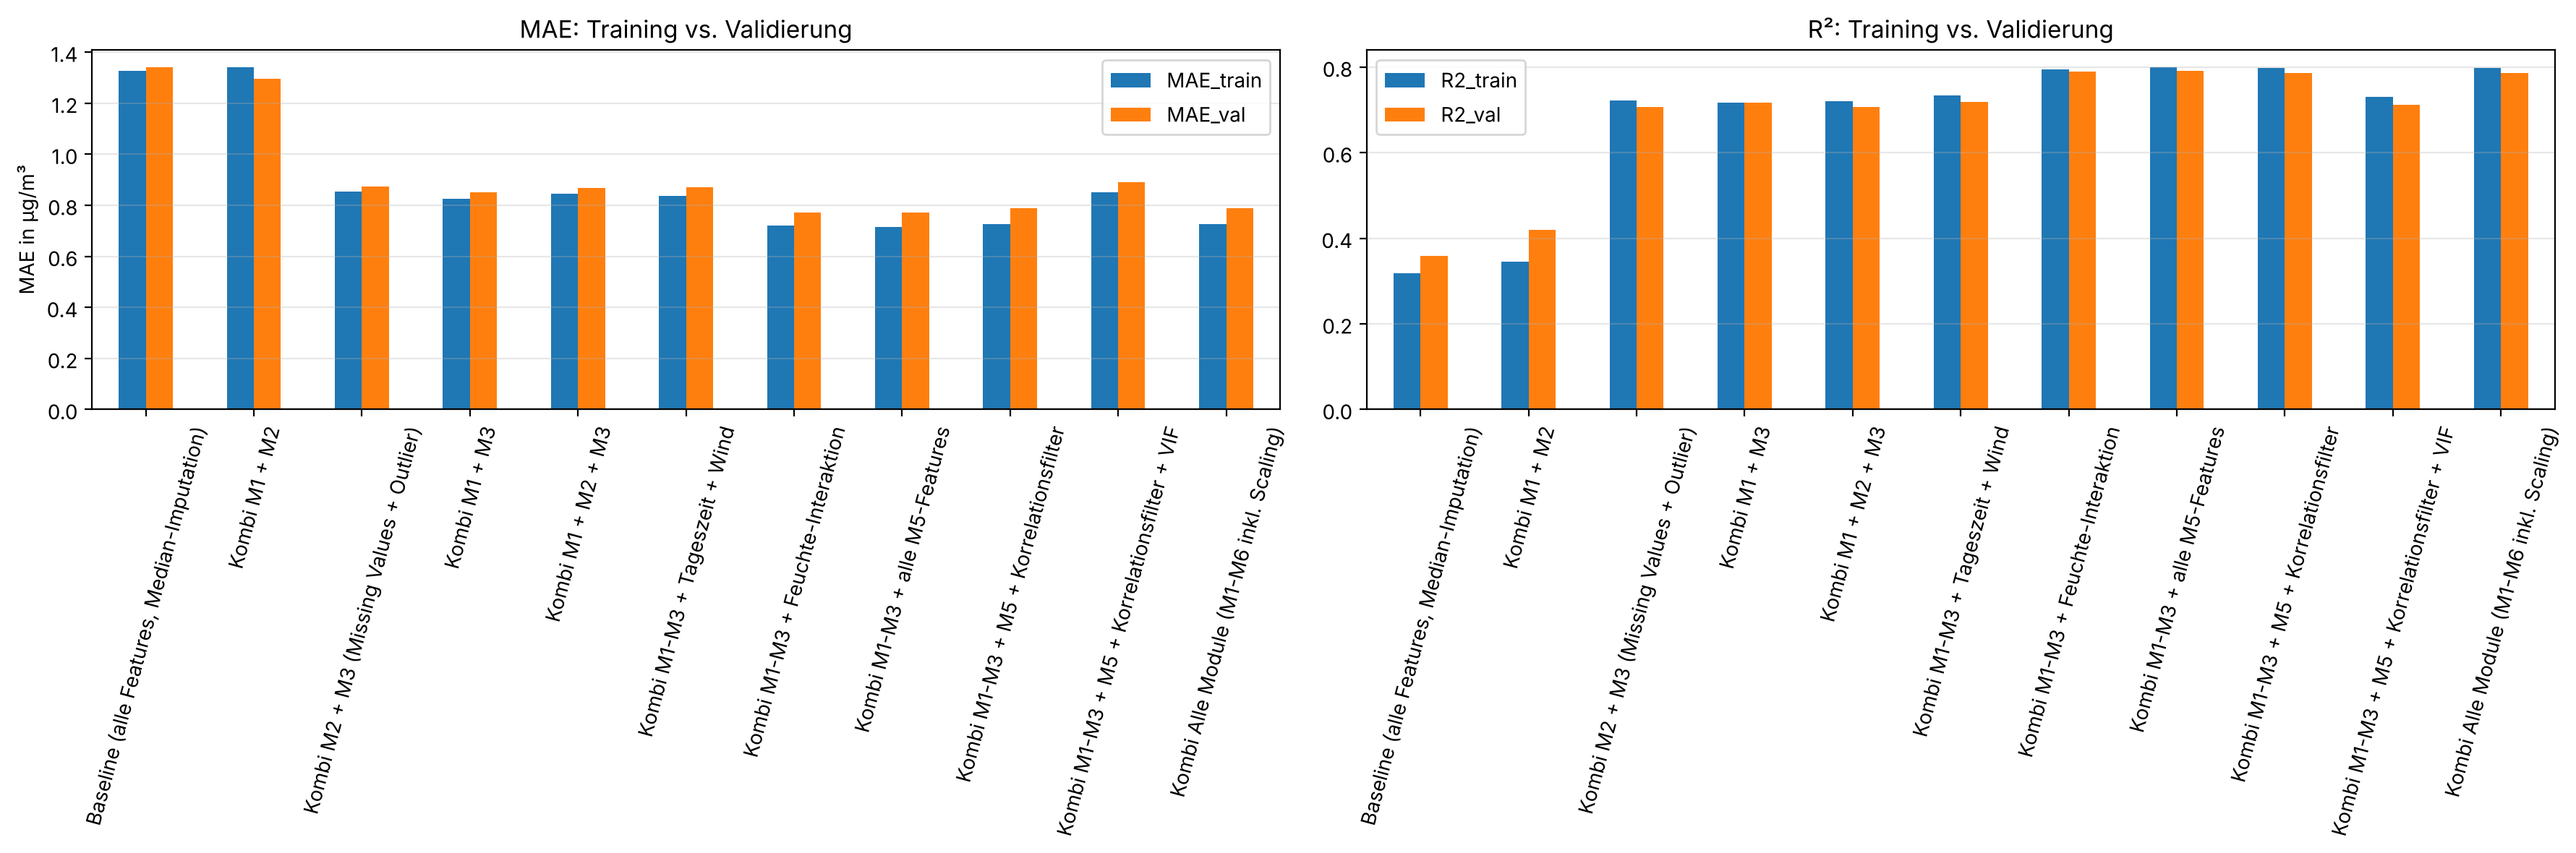

,MAE_train,MAE_val,Overfitting-Lücke (MAE_val - MAE_train),R2_train,R2_val
Modell,,,,,
"Baseline (alle Features, Median-Imputation)",1.3261,1.3417,0.0156,0.3183,0.3590
Kombi M1 + M2,1.3409,1.2951,-0.0458,0.3454,0.4196
Kombi M2 + M3 (Missing Values + Outlier),0.8522,0.8742,0.0220,0.7214,0.7068
Kombi M1 + M3,0.8240,0.8496,0.0256,0.7166,0.7160
Kombi M1 + M2 + M3,0.8441,0.8689,0.0248,0.7209,0.7065
Kombi M1-M3 + Tageszeit + Wind,0.8355,0.8718,0.0363,0.7328,0.7182
Kombi M1-M3 + Feuchte-Interaktion,0.7212,0.7701,0.0489,0.7943,0.7892
Kombi M1-M3 + alle M5-Features,0.7135,0.7711,0.0576,0.8000,0.7913
Kombi M1-M3 + M5 + Korrelationsfilter,0.7252,0.7887,0.0635,0.7974,0.7861


In [39]:
final_idx = log_df["MAE_val"].idxmin()
of_rows = [0] + list(range(combo_start, matrix_start)) + ([final_idx] if final_idx >= matrix_start else [])
of_df = log_df.loc[of_rows].set_index("Modell")

fig, axes = plt.subplots(1, 2, figsize=(18, 6))
of_df[["MAE_train", "MAE_val"]].plot.bar(ax=axes[0], rot=75)
axes[0].set_title("MAE: Training vs. Validierung")
axes[0].set_ylabel("MAE in µg/m³")
of_df[["R2_train", "R2_val"]].plot.bar(ax=axes[1], rot=75)
axes[1].set_title("R²: Training vs. Validierung")
for ax in axes:
    ax.set_xlabel("")
    ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

display(of_df[["MAE_train", "MAE_val", "Overfitting-Lücke (MAE_val - MAE_train)", "R2_train", "R2_val"]].round(4))

**Interpretation Overfitting:**
- Bei allen Modellen liegen Trainings- und Validierungsfehler nah beieinander. Die größte Lücke beträgt etwa **0,06 µg/m³**, beim finalen Modell 0,05 (R² 0,79 auf beiden).
- Die Lücke wächst mit zusätzlichen Features leicht an. Für eine lineare Regression mit 15 Features und rund 2.500 Trainingszeilen ist das unkritisch. Wir sehen **kein relevantes Overfitting**.

**Wichtig:** Dieser Check zeigt nur, dass das Modell innerhalb **desselben Zeitraums** (Juni–Oktober) gut generalisiert. Ob es auf einen anderen Zeitraum übertragbar ist, zeigt erst der Test. Den Vergleich Training vs. Test analysieren wir in Abschnitt 10.

## 9. Finales Modell auf den Testdaten

Erst jetzt verwenden wir die Testdaten. Die Pipeline lernt alle Parameter auf dem Trainingsanteil und wendet sie unverändert auf die Testdaten an. Zum fairen Vergleich bewerten wir die **Baseline** mit denselben Trainingsdaten ebenfalls auf dem Test.

Wie in Task 1 bleiben alle 1.464 Testzeilen erhalten; MAE/R² werden nur auf den Zeilen mit Label berechnet.

In [40]:
def evaluate_on_test(config):
    data = run_pipeline(config)
    feats = data["features"]
    model = LinearRegression().fit(data["train"][feats], data["train"][TARGET])
    has_label = data["test"][TARGET].notna().to_numpy()
    y_true = data["test"].loc[has_label, TARGET]
    y_pred = model.predict(data["test"][feats])
    return {"MAE": mean_absolute_error(y_true, y_pred[has_label]), "R2": r2_score(y_true, y_pred[has_label]),
            "pred": y_pred, "model": model, "data": data}


test_baseline = evaluate_on_test({})
test_final = evaluate_on_test(FINAL_CONFIG)

test_overview = pd.DataFrame({
    "MAE_val": [baseline_metrics["MAE_val"], final_row["MAE_val"]],
    "MAE_test": [test_baseline["MAE"], test_final["MAE"]],
    "R2_val": [baseline_metrics["R2_val"], final_row["R2_val"]],
    "R2_test": [test_baseline["R2"], test_final["R2"]],
}, index=["Baseline", "Finales Modell: " + final_name])
test_overview["Delta MAE_test ggü. Baseline (%)"] = (test_baseline["MAE"] - test_overview["MAE_test"]) / test_baseline["MAE"] * 100
display(test_overview.round(4))

print("Testzeilen gesamt:", len(raw_test), "| davon mit Label (bewertet):", int(raw_test[TARGET].notna().sum()))

# Testergebnis ebenfalls ins Log-File
test_log = test_overview.reset_index().rename(columns={"index": "Modell"})
test_log.round(4).to_csv(OUTPUT_DIR + "test_evaluation.csv", index=False, sep=";", decimal=",")

,MAE_val,MAE_test,R2_val,R2_test,Delta MAE_test ggü. Baseline (%)
Baseline,1.3417,2.2193,0.3590,-0.1453,0.0000
Finales Modell: Kombi M1-M3 + Feuchte-Interaktion,0.7701,1.5782,0.7892,0.4511,28.8875


Testzeilen gesamt: 1464 | davon mit Label (bewertet): 1419


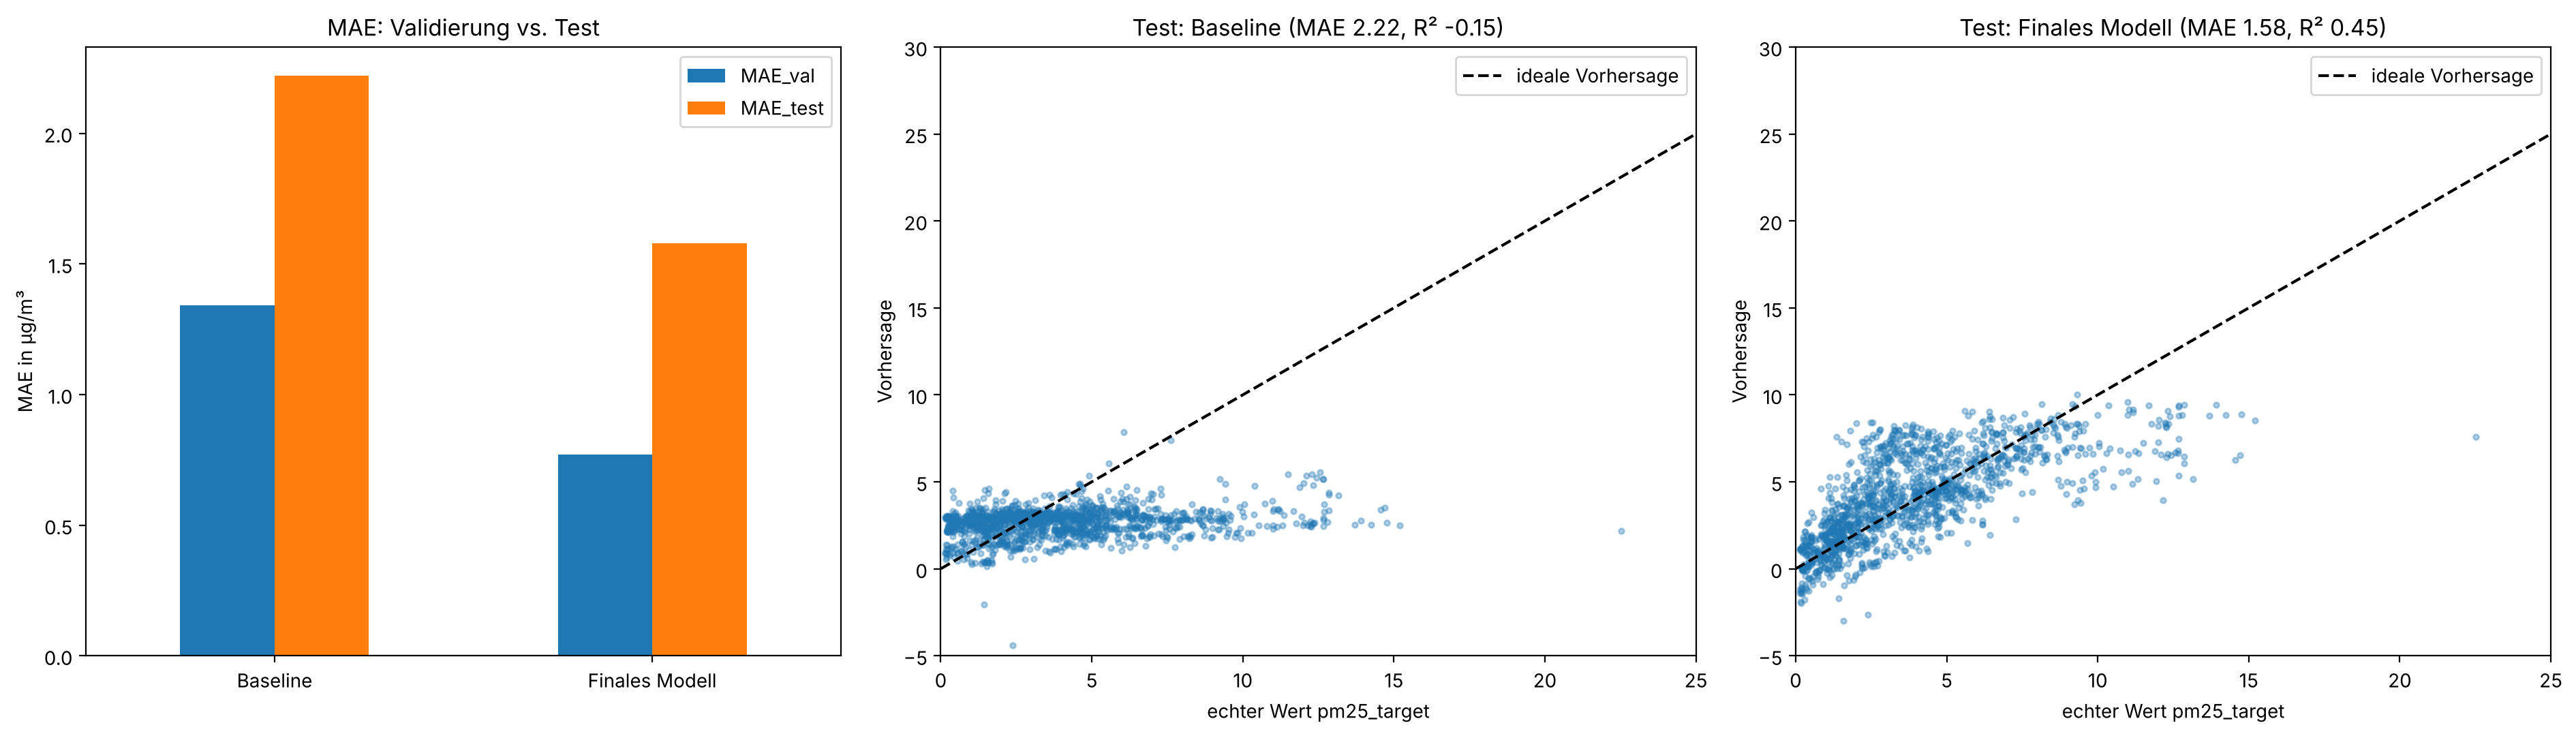

In [41]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))

test_overview[["MAE_val", "MAE_test"]].plot.bar(ax=axes[0], rot=0)
axes[0].set_title("MAE: Validierung vs. Test")
axes[0].set_xticks([0, 1], ["Baseline", "Finales Modell"])
axes[0].set_ylabel("MAE in µg/m³")

has_label = raw_test[TARGET].notna().to_numpy()
y_test = raw_test.loc[has_label, TARGET]
limits = (0, max(y_test.max(), 25))
for ax, (title, result) in zip(axes[1:], [("Test: Baseline", test_baseline), ("Test: Finales Modell", test_final)]):
    ax.scatter(y_test, result["pred"][has_label], s=8, alpha=0.35)
    ax.plot(limits, limits, "--", color="black", label="ideale Vorhersage")
    ax.set_xlim(limits)
    ax.set_ylim(-5, 30)
    ax.set_title(title + f" (MAE {result['MAE']:.2f}, R² {result['R2']:.2f})")
    ax.set_xlabel("echter Wert pm25_target")
    ax.set_ylabel("Vorhersage")
    ax.legend()

plt.tight_layout()
plt.show()

**Interpretation Testergebnis:**
- Das finale Modell verbessert den Test-MAE gegenüber der Baseline von **2,22 auf 1,58 µg/m³ (−28,9 %)**. Das R² steigt von **−0,15** (schlechter als eine konstante Mittelwert-Vorhersage) auf **0,45**. Die Data Preparation wirkt also auch auf unbekannten Daten deutlich.
- Im Streudiagramm sieht man den Unterschied: Die Baseline sagt fast immer 2–4 µg/m³ voraus, unabhängig vom echten Wert. Das finale Modell folgt der Diagonale, überschätzt aber bei niedrigen echten Werten häufig.
- **Aber:** Der Test-MAE (1,58) ist etwa doppelt so hoch wie der Validierungs-MAE (0,77). Das untersuchen wir im nächsten Abschnitt.
- **Welche Zahl ist aussagekräftiger?** Die −42,6 % auf der Validierung sind eher zu optimistisch, weil Training und Validierung aus demselben Zeitraum stammen. Die **−28,9 % auf dem Test** sind die ehrlichere Zahl, weil das Modell dort wirklich unbekannte Daten aus einer anderen Jahreszeit sieht. Für die Bewertung der Data Preparation stellen wir deshalb das Testergebnis in den Vordergrund.
- **Einordnung des R²:** Ein Test-R² von 0,45 bedeutet, dass das Modell knapp die Hälfte der Schwankung der Referenzmessung erklärt. Das ist eine deutliche Verbesserung, aber noch weit von einer präzisen Kalibrierung entfernt. Der durchschnittliche Fehler von 1,58 µg/m³ liegt bei etwa 40 % des mittleren Testwerts (3,9 µg/m³).
- Zum Vergleich Task 1b: Dort war das Modell mit zusätzlichen Features auf dem Test schlechter als die reine Low-Cost-Baseline (2,21 vs. 2,16). Mit der Data Preparation ist das Modell jetzt klar besser als beide.

## 10. Analyse: Warum ist der Test schlechter als die Validierung?

Diese Frage war schon in Task 1 offen. Wir sehen uns zwei mögliche Ursachen **beschreibend** an:

1. **Datenqualität der Testfeatures:** Fehlen im Test andere oder mehr Werte als im Training?
2. **Saison:** Die Testdaten (Nov/Dez) stammen aus einer anderen Jahreszeit als die Trainingsdaten (Jun–Okt).

Wie viel jede Ursache zum höheren Testfehler beiträgt, können wir damit **nicht** quantitativ trennen. Dafür bräuchte man z. B. Testdaten aus derselben Saison ohne Lücken. Wir formulieren die Ergebnisse deshalb als begründete Hypothesen.

**Wichtig:** Diese Analyse findet **nach** der Modellauswahl statt und ändert die Auswahl nicht mehr.

In [42]:
missing_compare = pd.DataFrame({
    "fehlend Training (%)": (raw_train.isna().mean() * 100).round(1),
    "fehlend Test (%)": (raw_test.isna().mean() * 100).round(1),
    "längster Block Test (Stunden)": [longest_gap(raw_test[col]) for col in raw_test.columns],
})
display(missing_compare[(missing_compare["fehlend Training (%)"] > 0) | (missing_compare["fehlend Test (%)"] > 0)])

print("Fehlende Wetterdaten im Test liegen im Zeitraum",
      raw_test.loc[raw_test["temperature"].isna(), "timestamp"].min(), "bis",
      raw_test.loc[raw_test["temperature"].isna(), "timestamp"].max())

,fehlend Training (%),fehlend Test (%),längster Block Test (Stunden)
pm25_target,5.6,3.1,45
pm25_lowcost,12.8,0.2,3
no,0.6,0.1,2
no2,0.6,0.1,2
o3,20.7,10.7,156
co2,25.7,58.6,744
black_carbon,0.1,48.7,713
ufp,21.5,42.0,576
temperature,11.8,67.3,984
relative_humidity,11.8,67.3,984


Fehlende Wetterdaten im Test liegen im Zeitraum 2024-11-07 13:00:00 bis 2024-12-31 23:00:00


,pm25_target,pm25_lowcost,temperature,relative_humidity,black_carbon
year_month,,,,,
2024-06,2.80,2.71,17.66,70.75,0.43
2024-07,2.34,1.95,19.81,72.80,0.50
2024-08,3.24,2.61,21.66,73.39,0.65
2024-09,2.79,3.31,16.58,78.13,0.73
2024-10,2.66,3.75,13.11,83.69,0.95
2024-11,3.52,5.98,8.20,85.20,0.88
2024-12,3.04,5.57,4.81,81.56,0.56


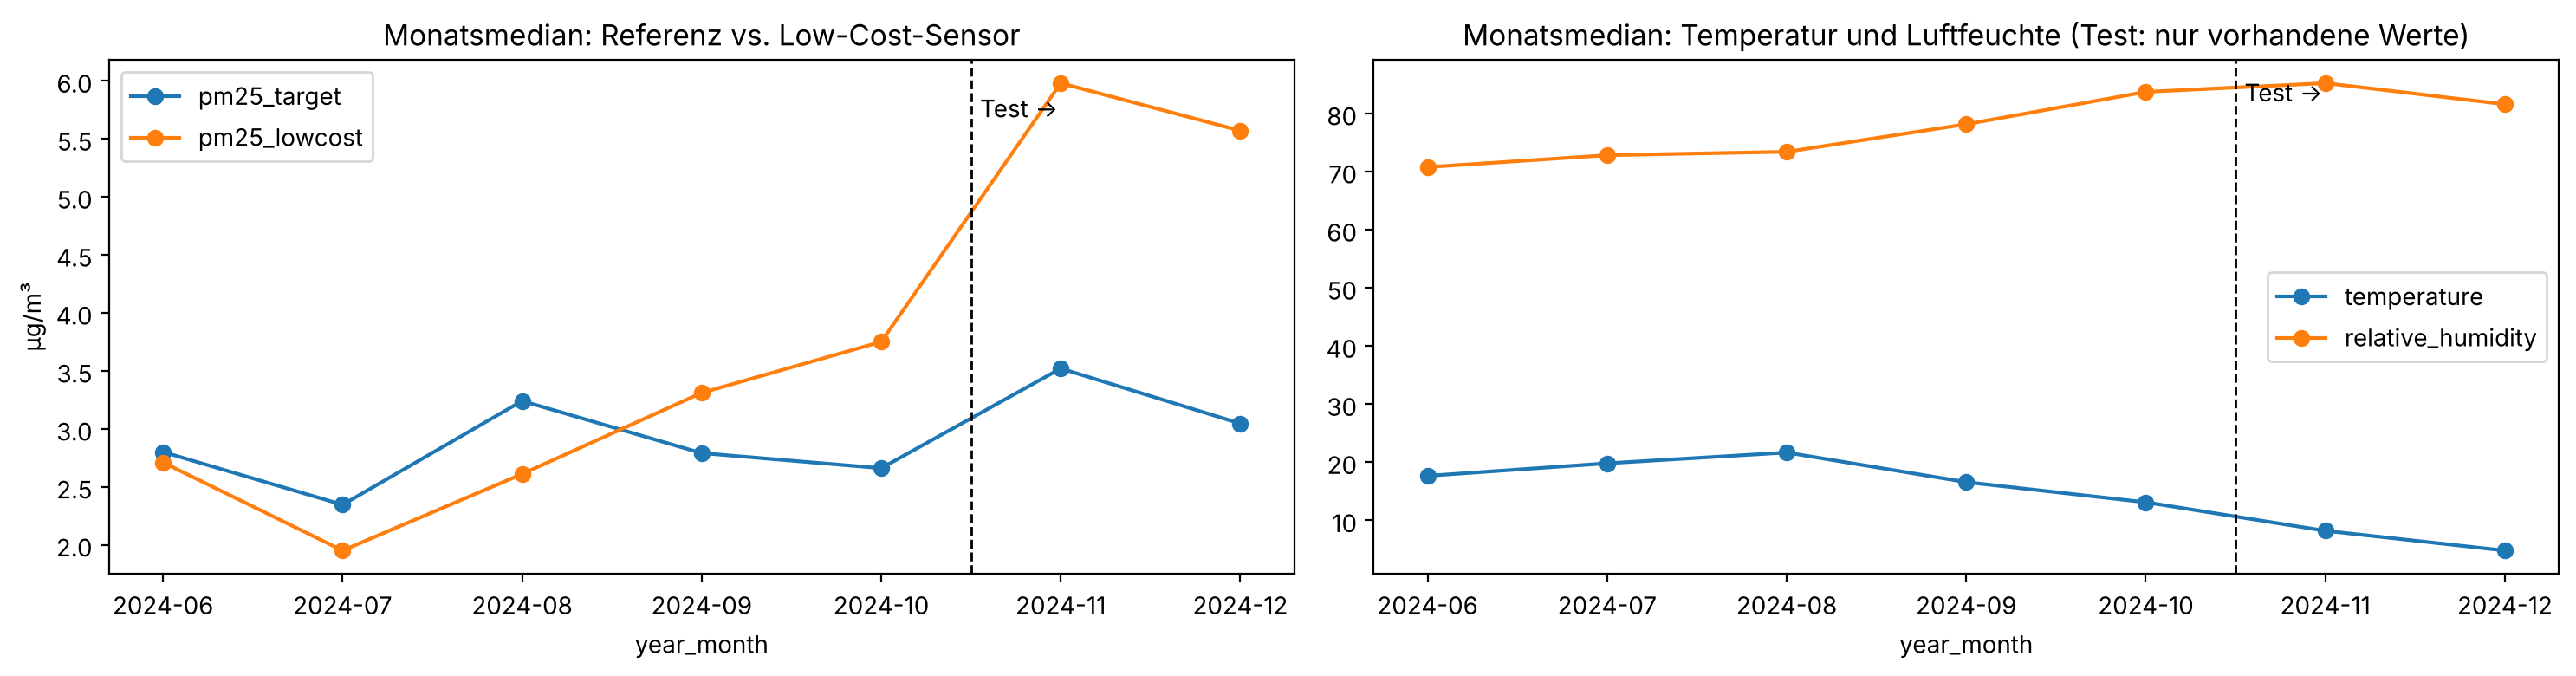

In [43]:
monthly = pd.concat([raw_train, raw_test]).groupby("year_month")[
    ["pm25_target", "pm25_lowcost", "temperature", "relative_humidity", "black_carbon"]].median()
display(monthly.round(2))

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
monthly[["pm25_target", "pm25_lowcost"]].plot(marker="o", ax=axes[0])
axes[0].set_title("Monatsmedian: Referenz vs. Low-Cost-Sensor")
axes[0].set_ylabel("µg/m³")
monthly[["temperature", "relative_humidity"]].plot(marker="o", ax=axes[1])
axes[1].set_title("Monatsmedian: Temperatur und Luftfeuchte (Test: nur vorhandene Werte)")
for ax in axes:
    ax.axvline(4.5, color="black", linestyle="--", linewidth=1)
    ax.text(4.55, ax.get_ylim()[1] * 0.92, "Test →")
plt.tight_layout()
plt.show()

#### Training vs. Test: Overfitting oder Verteilungsverschiebung?

Zwischen Trainings-MAE (0,72) und Test-MAE (1,58) liegt mehr als ein Faktor 2. Das sieht nach Overfitting aus. Wir prüfen deshalb genauer, woher der Abstand kommt:

1. **Klassisches Overfitting** würde sich schon zwischen Training und Validierung zeigen, weil beide aus demselben Zeitraum stammen (Abschnitt 8.3). Tritt der Sprung erst beim Test auf, liegt die Ursache eher in den anderen Testdaten.
2. Zeigt **auch die Baseline** einen großen Sprung, hat er nichts mit unserer Data Preparation zu tun.
3. Wir vergleichen das finale Modell mit derselben Pipeline **ohne Feuchte-Feature**, um zu sehen, ob sich gerade dieses Feature schlecht auf den Winter überträgt.
4. Wir teilen die Testzeilen in solche **mit** und **ohne** gemessene Luftfeuchte. Liegt das Problem an fehlenden Werten, müssten die Zeilen ohne Feuchte deutlich schlechter sein.
5. Wir prüfen, wie oft die gelernte Kappungsgrenze im Test greift.

**Wichtig:** Das ist eine nachträgliche Analyse. Sie ändert die Modellauswahl nicht, sie erklärt das Ergebnis und gibt Task 3 Hinweise.

,Modell,MAE Train,MAE Val,MAE Test,Test: Feuchte gemessen,Test: Feuchte fehlt,Faktor Test / Train
0,Baseline,1.326,1.342,2.219,2.127,2.260,1.674
1,"M1 + M3 (IQR), ohne Feuchte-Feature",0.824,0.850,1.474,1.636,1.403,1.789
2,Finales Modell ohne Feuchte-Feature,0.844,0.869,1.485,1.641,1.416,1.759
3,Finales Modell,0.721,0.770,1.578,1.833,1.466,2.188


Testzeilen mit Label – Feuchte gemessen: 434 | Feuchte fehlt: 985
Kappungsgrenze pm25_lowcost: 9.689 µg/m³
Anteil gekappter Werte – Training: 7.0 % | Test: 23.5 %


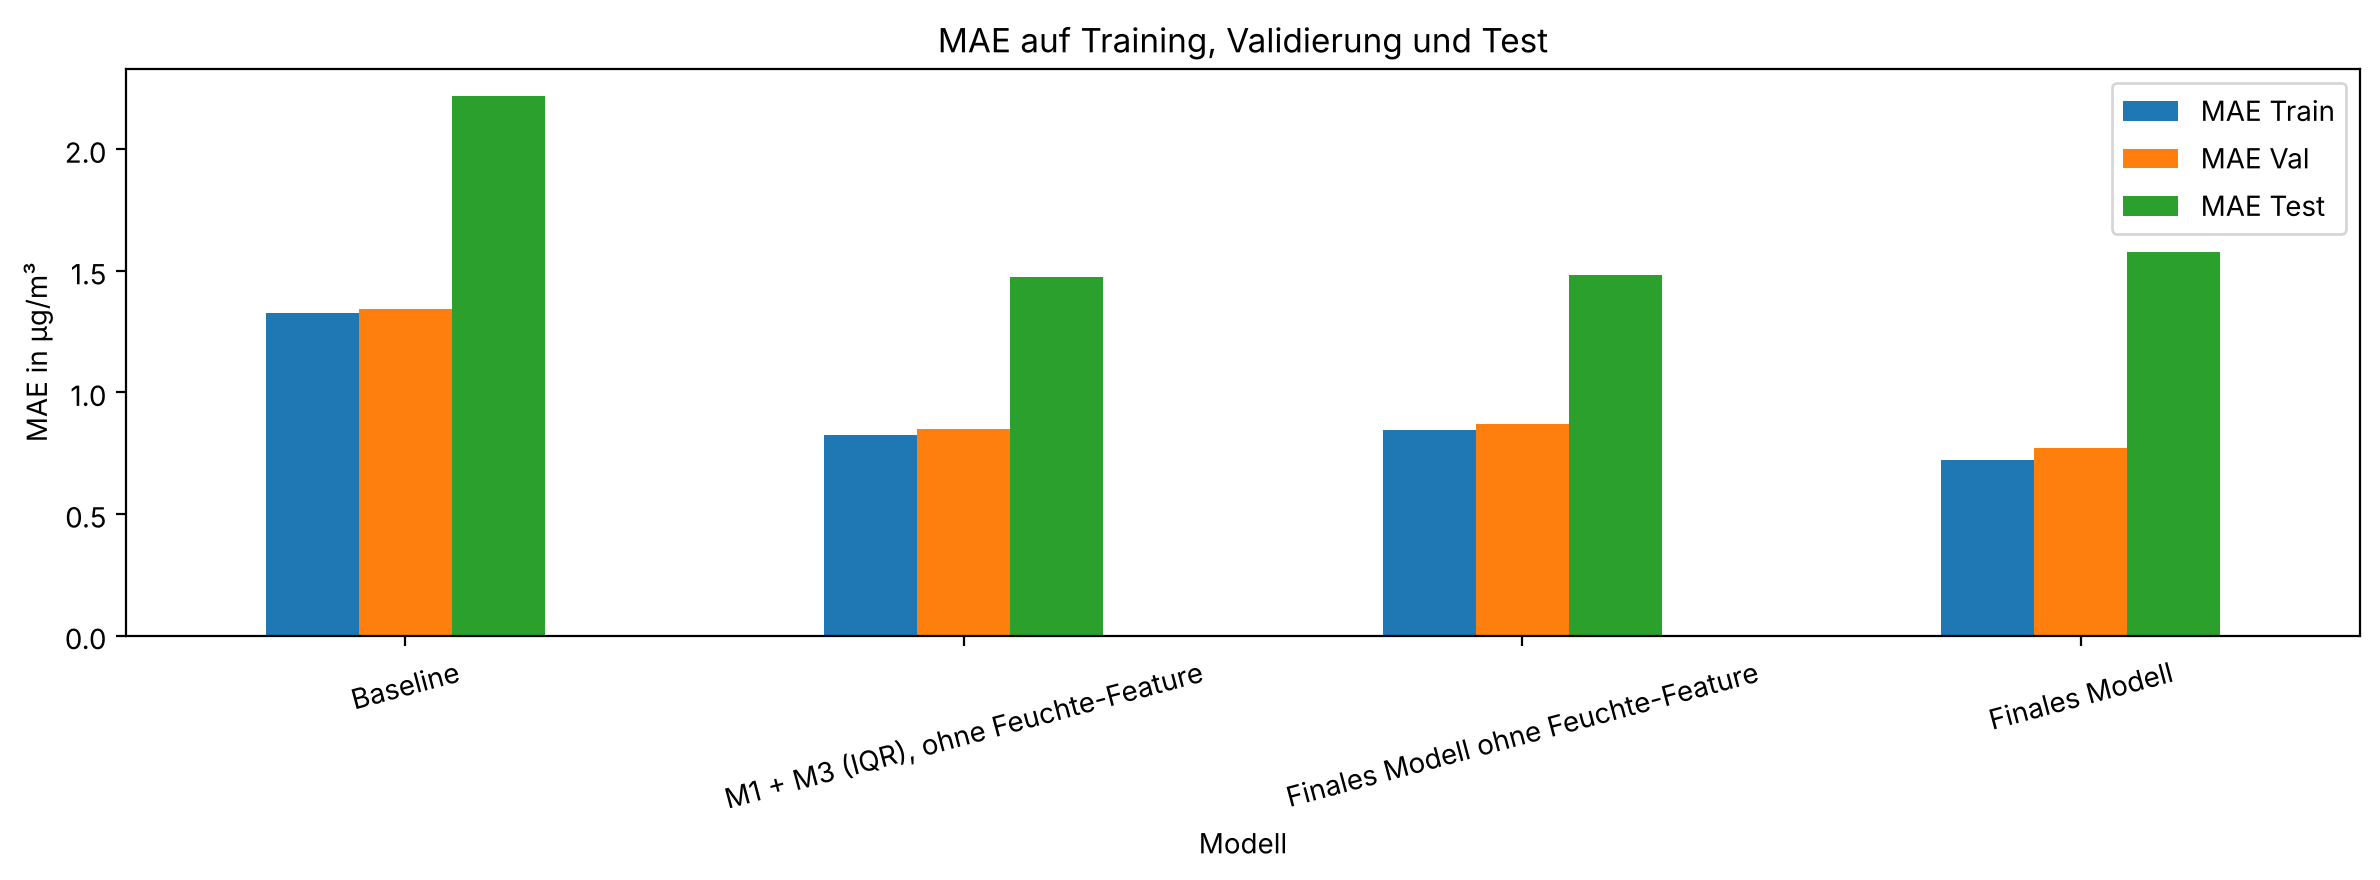

In [44]:
from sklearn.metrics import mean_absolute_error as mae_score

rh_measured = raw_test["relative_humidity"].notna().to_numpy()
test_has_label = raw_test[TARGET].notna().to_numpy()

gap_rows = []
for name, config in [("Baseline", {}),
                     ("M1 + M3 (IQR), ohne Feuchte-Feature", {"M1_rules": True, "M3_outliers": "iqr"}),
                     ("Finales Modell ohne Feuchte-Feature", {**FINAL_CONFIG, "M5_features": []}),
                     ("Finales Modell", FINAL_CONFIG)]:
    data = run_pipeline(config)
    feats = data["features"]
    model = LinearRegression().fit(data["train"][feats], data["train"][TARGET])
    pred_test = model.predict(data["test"][feats])
    val_label = data["val"][TARGET].notna().to_numpy()
    gap_rows.append({
        "Modell": name,
        "MAE Train": mae_score(data["train"][TARGET], model.predict(data["train"][feats])),
        "MAE Val": mae_score(data["val"][TARGET][val_label], model.predict(data["val"][feats])[val_label]),
        "MAE Test": mae_score(raw_test[TARGET][test_has_label], pred_test[test_has_label]),
        "Test: Feuchte gemessen": mae_score(raw_test[TARGET][test_has_label & rh_measured], pred_test[test_has_label & rh_measured]),
        "Test: Feuchte fehlt": mae_score(raw_test[TARGET][test_has_label & ~rh_measured], pred_test[test_has_label & ~rh_measured]),
    })

gap_table = pd.DataFrame(gap_rows)
gap_table["Faktor Test / Train"] = gap_table["MAE Test"] / gap_table["MAE Train"]
display(gap_table.round(3))
print("Testzeilen mit Label – Feuchte gemessen:", int((test_has_label & rh_measured).sum()),
      "| Feuchte fehlt:", int((test_has_label & ~rh_measured).sum()))

# Wie oft greift die Kappungsgrenze von pm25_lowcost?
cap = test_final["data"]["info"]["M3"]["pm25_lowcost Obergrenze"]
print("Kappungsgrenze pm25_lowcost:", cap, "µg/m³")
print("Anteil gekappter Werte – Training:", round((raw_train.loc[train_idx, "pm25_lowcost"] > cap).mean() * 100, 1), "%",
      "| Test:", round((raw_test["pm25_lowcost"] > cap).mean() * 100, 1), "%")

gap_table.set_index("Modell")[["MAE Train", "MAE Val", "MAE Test"]].plot.bar(rot=15, figsize=(12, 4.5))
plt.title("MAE auf Training, Validierung und Test")
plt.ylabel("MAE in µg/m³")
plt.tight_layout()
plt.show()

**Interpretation: Training vs. Test**

1. **Kein klassisches Overfitting:** Bei allen Modellen liegen Training und Validierung nah beieinander. Den großen Sprung gibt es erst beim Test, und zwar auch bei der Baseline (Faktor 1,7). Der Abstand hat also seine Ursache in den anderen Testdaten, nicht in einer Überanpassung durch unsere Data Preparation.
2. **Aber: Das Feuchte-Feature überträgt sich nicht auf den Winter.** Ohne Feuchte-Feature ist die Pipeline auf der Validierung schlechter (0,87 statt 0,77), auf dem Test aber **besser** (1,49 statt 1,58). Der Faktor Test/Train steigt durch das Feature von etwa 1,8 auf 2,2. Das Feature hat einen Zusammenhang gelernt, der im Sommer gilt, im Winter aber nicht mehr in gleicher Form.
3. **Fehlende Feuchte ist nicht die Hauptursache:** Das finale Modell ist auf den Testzeilen **mit** gemessener Luftfeuchte schlechter (1,83) als auf denen ohne (1,47). Unsere Vermutung aus der ersten Fassung („die mit dem Sommer-Median gefüllte Feuchte schadet“) wird damit nicht gestützt.
4. **Die Kappung greift im Winter viel häufiger:** Im Training liegen 7 % der Low-Cost-Werte über der Grenze von 9,7 µg/m³, im Test 23,5 %. Im Winter misst der Sensor insgesamt höher (siehe Monatsmediane). Ein Teil dieser höheren Werte ist echt und wird durch die im Sommer gelernte Grenze abgeschnitten. Das ist eine plausible Mitursache, die wir nicht weiter isoliert haben.

**Konsequenz:** Wir ändern die Modellauswahl **nicht**, weil eine Auswahl anhand des Tests Leakage wäre. Nach unserer festgelegten Regel ist das finale Modell das beste auf der Validierung. Für Task 3 ist das aber ein wichtiger Hinweis: Das Feuchte-Feature und die Kappungsgrenze sollten mit einer **zeitlichen Validierung** geprüft werden (z. B. Oktober als Validierung), weil eine zufällige Validierung aus dem Sommer diesen Effekt nicht zeigen kann.

**Learning:** „Kein Overfitting“ (Training ≈ Validierung) heißt nicht „generalisiert auf alles“. Ein Feature kann innerhalb einer Saison helfen und bei veränderten Bedingungen schaden. Das erkennt man nur, wenn die Validierung diese Veränderung abbildet.

#### Nachträgliche Kontrolle: Wie schneiden die besten Validierungsmodelle auf dem Test ab?

Diese Tabelle ist ausdrücklich **keine Grundlage für die Modellauswahl** (das wäre Test-Leakage), sondern dient nur dem Verständnis und der Übergabe an Task 3.

In [45]:
# Alle Modelle, die auf der Validierung höchstens 0,02 µg/m³ schlechter sind als das beste
# (0,02 = Größenordnung der Unterschiede innerhalb der Kombinationsmatrix, siehe Abschnitt 7)
best_val = log_df["MAE_val"].min()
top_names = log_df[log_df["MAE_val"] <= best_val + 0.02].sort_values("MAE_val")["Modell"].tolist()
posthoc = []
for name in top_names:
    result = evaluate_on_test({**BASE_CONFIG, **all_configs[name]})
    posthoc.append({"Modell": name, "MAE_val": log_df.set_index("Modell").loc[name, "MAE_val"],
                    "MAE_test": result["MAE"], "R2_test": result["R2"]})
posthoc.append({"Modell": "Baseline", "MAE_val": baseline_metrics["MAE_val"], "MAE_test": test_baseline["MAE"],
                "R2_test": test_baseline["R2"]})
display(pd.DataFrame(posthoc).round(4))

,Modell,MAE_val,MAE_test,R2_test
0,Kombi M1-M3 + Feuchte-Interaktion,0.7701,1.5782,0.4511
1,Kombi M1-M3 + alle M5-Features,0.7711,1.5822,0.4542
2,Matrix M1 + M2 median + M3 iqr + alle M5-Features,0.7737,1.5442,0.4762
3,Matrix M1 + M2 drop_rows + M3 winsor95 + alle ...,0.7814,1.6284,0.4245
4,Matrix M1 + M2 median + M3 winsor95 + alle M5-...,0.7823,1.5921,0.4527
5,Kombi Alle Module (M1-M6 inkl. Scaling),0.7887,1.5773,0.4555
6,Kombi M1-M3 + M5 + Korrelationsfilter,0.7887,1.5773,0.4555
7,Baseline,1.3417,2.2193,-0.1453


**Interpretation: mögliche Gründe für den schlechteren Test**

**1. Fehlende Werte im Test (Datenqualität):**
Im Test fehlen die Wetterdaten zu **67 %**, überwiegend ab dem 07.11. `black_carbon` fehlt zu **49 %** (im Training nur 2 Werte), `co2` zu 59 % und `ufp` zu 42 %. Diese Lücken werden mit Werten aus dem Sommer gefüllt, für die Temperatur z. B. mit etwa 17 °C statt der tatsächlichen 5–8 °C. Das könnte Task 1b erklären, wo sich das Modell stark auf `black_carbon` gestützt hat. Für unser Feuchte-Feature hatten wir zunächst vermutet, dass vor allem die fehlende Luftfeuchte schadet. Die Analyse „Training vs. Test“ oben zeigt aber das Gegenteil: Das Modell ist auf den Testzeilen **mit** gemessener Feuchte schlechter. Diese Vermutung haben wir deshalb verworfen.

**2. Saison (Verteilungsverschiebung):**
Die Monatsmediane zeigen einen klaren Trend: Je kälter und feuchter es wird, desto stärker misst der Low-Cost-Sensor über der Referenz. Im Juni messen beide fast gleich (2,7 vs. 2,8 µg/m³), im November liegt der Low-Cost-Sensor bei 6,0 gegenüber 3,5 µg/m³. Solche Bedingungen kommen in den Trainingsdaten kaum vor. Das Modell muss also **extrapolieren**, was eine lineare Regression nur begrenzt kann.

**Was wir nicht sagen können:** Wie viel des Unterschieds auf die fehlenden Werte und wie viel auf die Saison entfällt, lässt sich mit diesen Daten nicht sauber trennen. Beide Effekte treten im Test gleichzeitig auf.

**3. Nachträgliche Kontrolle:**
Die besten Validierungsmodelle liegen auf dem Test zwischen 1,54 und 1,63. Die Reihenfolge der Top-Modelle ist also nicht stabil, die Größenordnung der Verbesserung schon. Wir ändern unsere Auswahl **bewusst nicht**: Eine Auswahl anhand des Tests wäre Leakage. Für Task 3 nehmen wir aber mit, dass die Unterschiede zwischen den Top-Varianten auf der Validierung zu klein sind, um eine davon klar zu bevorzugen.

**Learning:** Eine zufällige Validierung aus demselben Zeitraum misst nur, wie gut das Modell **innerhalb der Saison** ist. Sie kann den Fehler unterschätzen, wenn sich Bedingungen oder Datenqualität ändern.

## 11. Export der vorbereiteten Datensätze

Für Task 3 exportieren wir die mit der finalen Pipeline vorbereiteten Datensätze. Sie enthalten den `timestamp`, alle finalen Features und das Label. Den `timestamp` geben wir mit, obwohl er kein Feature ist, damit Task 3 z. B. eine zeitliche Validierung bauen kann (Empfehlung in Abschnitt 12). Die Datensätze speichern wir im Standard-CSV-Format (`,` als Trenner), damit Task 3 sie direkt mit `pd.read_csv()` laden kann. Das Log-File dagegen im deutschen Excel-Format (`;` und Dezimalkomma), weil es zum Lesen und für die Folien gedacht ist. Im Validierungs- und Testdatensatz sind **alle Zeilen** enthalten, auch die ohne Label, und die Labels sind unverändert.

In [46]:
final_data = test_final["data"]
export_cols = ["timestamp"] + final_data["features"] + [TARGET]

exports = {"Task2_preprocessed_train.csv": final_data["train"],
           "Task2_preprocessed_validation.csv": final_data["val"],
           "Task2_preprocessed_test.csv": final_data["test"]}

for file_name, df in exports.items():
    df[export_cols].to_csv(OUTPUT_DIR + file_name, index=False)
    print(f"{file_name:38s} Zeilen: {len(df):5d} | Spalten: {len(export_cols)} | Zeilen ohne Label: {df[TARGET].isna().sum()}")

# Kontrollen gemäß Aufgabenstellung
assert len(final_data["val"]) == len(val_idx)
assert len(final_data["test"]) == len(raw_test)
assert final_data["test"][TARGET].equals(raw_test[TARGET])

print("\nFeatures im Export:", final_data["features"])
print("Gelernte Parameter:", final_data["info"])

Task2_preprocessed_train.csv           Zeilen:  2464 | Spalten: 17 | Zeilen ohne Label: 0
Task2_preprocessed_validation.csv      Zeilen:   682 | Spalten: 17 | Zeilen ohne Label: 0
Task2_preprocessed_test.csv            Zeilen:  1464 | Spalten: 17 | Zeilen ohne Label: 45

Features im Export: ['pm25_lowcost', 'no', 'no2', 'o3', 'co2', 'black_carbon', 'ufp', 'temperature', 'relative_humidity', 'pressure', 'wind_speed', 'wind_direction', 'glob_rad', 'rain_hourly', 'lowcost_x_humidity']
Gelernte Parameter: {'M2': {'Methode': 'drop_rows', 'gelöschte Trainingszeilen': 263, 'noch fehlende Werte vor dem Füllen (Training)': 3751}, 'M3': {'Methode': 'iqr', 'pm25_lowcost Obergrenze': np.float64(9.689), 'black_carbon Obergrenze': np.float64(2.102), 'no Obergrenze': np.float64(11.65)}, 'M5': {'neue Features': ['humidity']}, 'M6': {'Methode': None}, 'M4': {'Methode': None}}


## 12. Learnings, Übergabe an Task 3 und Coding-Reflexion

### 12.1 Zusammenfassung der Ergebnisse

| | Validierung MAE | Validierung R² | Test MAE | Test R² |
|---|---|---|---|---|
| Baseline (alle Features, Median) | 1,34 | 0,36 | 2,22 | −0,15 |
| Finales Modell (M1 + Zeilenlöschung + IQR-Kappung + Feuchte-Interaktion) | 0,77 | 0,79 | 1,58 | 0,45 |
| **Verbesserung** | **−42,6 %** | **+0,43** | **−28,9 %** | **+0,60** |

Die Validierung verwendet exakt den Split aus Task 1b (682 Zeilen); die Baseline entspricht dort dem Modell mit allen Features.

### 12.2 Annahmen- und Entscheidungsregister

Jede Annahme und jede Entscheidung, die in die Data Preparation eingeflossen ist, ist im Notebook vor ihrer Verwendung begründet und, wo möglich, im Modell geprüft.

| Annahme / Entscheidung | Beleg oder Begründung im Notebook | Geprüft im Modell |
|---|---|---|
| Split wie Task 1b ist korrekt übernommen | Abschnitt 1: `assert` auf 2.727/682 Zeilen; Abschnitt 3: Baseline-MAE = 1,3417 wie Task 1b | – |
| Negative Konzentrationen sind Messrauschen | M1: Tabelle der negativen Werte (klein, nahe 0, im Verhältnis zur Spannweite) | Abschnitt 6: M1 |
| Temperatur darf negativ sein | M1: negative Werte nur im Test (Winter) | – |
| `rain_vol` ist ein aufsummierter Zähler | M1: nie sinkend, Testdatei startet beim letzten Trainingswert, Neustart nach Ausfall | Abschnitt 6: M1 |
| Lücken sind Blöcke, keine Einzelwerte | M2: Tabelle „längster Block" | – |
| Zeilenlöschung nur bei fehlendem `pm25_lowcost` | M2: komplette Listwise Deletion würde 1.718 von 2.727 Zeilen (63 %) löschen, unsere Variante 263 | Abschnitt 6: M2 |
| Keine zeitliche Interpolation | M2: nicht in den Labs, Lücken sind Blöcke, würde Validierungswerte ins Training mischen | – |
| Prädiktoren der Regressionsimputation | M2: Korrelations- und Vollständigkeitstabelle | Abschnitt 6: M2 |
| Pearson/Spearman-Lücke zeigt Ausreißer-Features | M3: Tabelle und Diagramm; Matrizen vorher/nachher | Abschnitt 6.1: Schwellen 0,10/0,15/0,25 |
| Extremwerte von `pm25_lowcost` sind Fehlmessungen | M3: Referenz bei Extremwerten max. 7,6 µg/m³, Uhrzeit, Luftfeuchte (Hypothese) | – |
| Schwelle 30 µg/m³ für „Extremwert" | M3: ca. 2 × Maximum der Referenz | nur Analyse, nicht für die Kappung |
| Kappung nur nach oben | M3: Begründung; Vorlesung beidseitig | Abschnitt 6.1: beidseitig vs. oben |
| Beste Kappungsgrenze | M3: Pearson-Scan je Perzentil (eine gemeinsame Perzentil-Liste für Scan und `pearson_opt`) | Abschnitt 6: sechs M3-Varianten |
| `log1p` statt `log`, Rang als Gleichverteilung | M3: Werte von 0 vorhanden; Vorlesung: Rang-Transformation = gleichverteilt | Abschnitt 6 |
| Scaling ändert bei LR nichts; nur `StandardScaler` getestet | M4: alle Scaler der Vorlesung sind linear | Abschnitt 6: M4 = exakt 0 % |
| Tagesrhythmus und Windrichtung als Kreis | M5: Stunden-Mediane, Verteilung der Windrichtung | Abschnitt 6/7: M5-Varianten |
| Feuchte-Interaktion als Produkt, Feuchte / 100 | M3: Verhältnis steigt mit der Feuchte (proportionaler Fehler); M5: / 100 ändert die Vorhersage nicht | Abschnitt 6/7 |
| Feature erst nach der Kappung bilden | M5: Begründung | Abschnitt 6 vs. 7: ohne Kappung 1,037, mit Kappung 0,770 |
| Korrelationsfilter 0,05 | M6: Begründung | Abschnitt 6.1: 0,05/0,10/0,15/ohne |
| VIF ≥ 10 | M6: Vorlesung Feature Selection Part 2 | Abschnitt 7 |
| `pm25_lowcost` wird nie entfernt | M6: Forschungsfrage und Task-1b-Vorgabe | – |
| Reihenfolge M2 vor M3 | Abschnitt 5: Median-Füllung verschiebt die Grenzen kaum (z. B. 11,3 → 11,0) | – |
| Reihenfolge M1 vor M3 | Abschnitt 5: `np.log1p(−2,7)` = NaN | – |
| Großer Abstand Train/Test ist kein klassisches Overfitting | Abschnitt 10: Train ≈ Val bei allen Modellen, Baseline zeigt denselben Sprung; Feuchte-Feature überträgt sich schlecht auf den Winter | nachträgliche Analyse, ändert die Auswahl nicht |
| Auswahl nach Validierungs-MAE | Abschnitt 8.2, vor dem Test festgelegt; Alternative „einfacheres Modell" begründet verworfen | – |
| Kombinationen aus den besten Einzelvarianten + Matrix | Abschnitt 7 und 7.1 | Abschnitt 7.1 |
| Nachträgliche Testkontrolle: Modelle bis +0,02 MAE | Abschnitt 10: Größenordnung der Unterschiede in der Matrix | nur zur Einordnung |
| Export mit `timestamp`, Standard-CSV | Abschnitt 11: zeitliche Validierung in Task 3 möglich, direkt mit `pd.read_csv()` lesbar | – |

### 12.3 Fachliche Learnings

1. **Der Pearson/Spearman-Vergleich hat uns gezeigt, wo wir suchen müssen.** Pearson 0,08 vs. Spearman 0,72 bei `pm25_lowcost` war der Hinweis; dass die Kappung die Lücke großteils schließt, hat ihn bestätigt. Über die Lücke haben wir außerdem die Features für das Outlier Handling ausgewählt (`pm25_lowcost`, `black_carbon`, `no`).
2. **Erst prüfen, dann behandeln.** Die Extremwerte treten nachts bei über 90 % Luftfeuchte auf, während die Referenz normal misst. Daraus haben wir die Hypothese eines Feuchteeffekts abgeleitet und ein Feature gebaut, das auf der Validierung der zweitgrößte Hebel war.
3. **Die beste Kappungsgrenze liegt zwischen „zu streng" und „zu großzügig".** Das 99. Perzentil ist zu großzügig, die Pearson-optimierte Grenze (85. Perzentil) zu streng. Die Boxplot-Grenze (IQR) und das 95. Perzentil funktionieren am besten.
4. **Kombinationen verhalten sich anders als Einzelmaßnahmen.** Die Zeilenlöschung war einzeln die beste Missing-Value-Variante, in Kombination mit dem Outlier Handling aber nicht mehr. Der VIF-Check entfernte ein hilfreiches Feature, weil „ähnlich" nicht „überflüssig" heißt.
5. **Scaling bringt bei linearer Regression nichts.** Das konnten wir erklären (lineare Transformation wird über die Koeffizienten ausgeglichen) und belegen (exakt gleicher MAE).
6. **Validierung ≠ Test, und kein Overfitting heißt nicht „generalisiert immer“.** Training und Validierung liegen nah beieinander, der Test ist trotzdem deutlich schlechter. Ursache sind die anderen Testdaten (Winter, Lücken). Besonders das Feuchte-Feature hilft auf der Validierung, schadet aber auf dem Test.

### 12.4 Übergabe an Task 3

- **Dateien:** `Output/Task2_preprocessed_train.csv`, `..._validation.csv`, `..._test.csv` (15 Features + `timestamp` + Label). Der Split ist identisch mit Task 1b; der Test enthält alle 1.464 Zeilen mit unveränderten Labels.
- **Keine erneute Skalierung nötig für lineare Modelle.** Für distanz- oder regularisierungsbasierte Verfahren (z. B. KNN, Ridge/Lasso) sollte Task 3 auf diesen Daten standardisieren.
- **Achtung bei den Testdaten:** Wetterdaten fehlen dort zu 67 %, `black_carbon` zu 49 %. Diese Werte sind im Export mit dem Trainings-Median gefüllt. Modelle, die sich stark auf diese Features stützen, könnten auf dem Test schwächer sein als auf der Validierung.
- **Wichtigster Hinweis aus Abschnitt 10:** Das Feuchte-Feature verbessert die Validierung, verschlechtert aber den Test (1,58 statt 1,49 ohne das Feature). Task 3 sollte das Feature und die Kappungsgrenze mit einer zeitlichen Validierung prüfen.
- **Empfehlung:** Nichtlineare Verfahren (z. B. Regression Trees, Polynomial Regression) testen, weil der Zusammenhang zwischen Sensor und Referenz nicht rein linear ist. Zusätzlich mit einer **zeitlichen Validierung** (z. B. Oktober als Validierung) prüfen, wie gut ein Modell auf kältere Monate übertragbar ist.
- **Alle Experimente** sind mit Beschreibung in `Output/evaluation_log.csv` dokumentiert, das Testergebnis in `Output/test_evaluation.csv`.

### 12.5 Coding-Reflexion

**Was hat sich bewährt?**
- **Einheitliche Modul-Schnittstelle** (`train_part`, `other_parts`, `method`), angelehnt an das `fit`/`transform`-Prinzip aus den Pipeline-Labs: Jede Kombination ist nur noch ein Dictionary. Im Vorjahr mussten wir für jede Stufe eigene Zellen schreiben.
- **Sicherheitsprüfungen mit `assert`**: Die Pipeline prüft bei jedem Lauf, dass Validierung und Test vollständig sind, die Labels unverändert sind und keine NaN übrig bleiben. Zusätzlich prüfen wir, dass der Split dieselben Größen wie in Task 1b hat und die Pipeline ohne Module exakt die Baseline reproduziert.
- **Automatisches Log-File**: Jedes Experiment wird sofort mit sprechendem Namen und Beschreibung gespeichert. Die Auswahl der besten Varianten erfolgt aus dem Log und nicht von Hand.

**Konkrete Fehler und was wir daraus gelernt haben:**
- **Split nicht identisch mit Task 1:** In einer ersten Version haben wir zuerst geteilt und erst danach die Zeilen ohne Label entfernt. Trotz gleicher `random_state` stimmten nur 233 von 682 Validierungszeilen mit Task 1 überein. **Learning:** Für vergleichbare Ergebnisse muss der gesamte Ablauf vor dem Split identisch sein, nicht nur der Seed.
- Beim ersten Test der Log-Transformation entstanden NaN-Werte, weil `np.log1p` für negative Werte nicht definiert ist. Daraus haben wir gelernt, dass die **Reihenfolge der Module** wichtig ist (M1 vor M3).
- Unsere erste Version des VIF-Checks brach zu früh ab. Seitdem prüfen wir die `info`-Ausgaben der Module gezielt auf Plausibilität.
- Eine erste Version enthielt eine **Stress-Validierung**: Wir haben in einer Kopie der Validierung zufällig so viele Werte gelöscht, wie im Test fehlen, um den Einfluss der Lücken vom Einfluss der Saison zu trennen. Wir haben sie wieder entfernt, weil sie das nicht sauber leisten kann: Zufällige Lücken bilden wochenlange Sensorausfälle nicht realistisch nach, bereits vorhandene Lücken erhöhten die tatsächliche Fehlquote, und durch die Neuberechnung des Regenzählers änderten sich sogar 53 Trainingswerte mit. **Learning:** Eine Analyse, die eine Ursache quantitativ belegen soll, muss genau das isolieren, was sie messen will. Sonst ist eine ehrliche Beschreibung besser als eine scheinbar genaue Zahl.
- Eine erste Version enthielt eine zeitliche Interpolation auf der ganzen Trainingsdatei. Dabei wären Werte aus Validierungszeilen in Trainingszeilen eingeflossen. Wir haben sie durch die Regressionsimputation aus Lab 04 ersetzt. **Learning:** „Kein Label verwendet" heißt nicht automatisch „keine Leakage".

**Was würden wir beim nächsten Mal anders machen?**
- Die Testdaten von Anfang an auf **Vollständigkeit der Features** prüfen (ohne Labels).
- Zusätzlich zur zufälligen Validierung eine **zeitliche Validierung** verwenden, weil die Daten eine Zeitreihe sind und der Test in einer anderen Saison liegt.
- Aussagen aus Diagrammen von Anfang an als **Hypothesen** formulieren und erst nach einer Prüfung im Modell als Ergebnis darstellen.